# ⭐ STARTRACE
## Learning Stellar Signal Morphology from TESS

**Research area:** Astrophysics × Machine Learning × Time-Series Analysis  
**Project type:** Exploratory research project using real NASA TESS observations

---

## 1. What is STARTRACE?

STARTRACE is a project I started to explore how machine learning can help us understand the changing brightness of stars.

A light curve is basically a record of how a star's brightness changes over time. These changes can tell us a lot about what is happening around or inside a star, from planets passing in front of it to eclipsing binaries and pulsating variable stars.

For this project, I built a pipeline using real observations from NASA's Transiting Exoplanet Survey Satellite (TESS). It downloads light-curve data, checks the targets against astronomical catalogues, cleans the data, and divides each light curve into smaller, fixed-length windows.

I then trained convolutional autoencoders to reconstruct and denoise these signals. After that, I explored whether the patterns learned by the models could help group different types of stellar signals together.

I chose four targets with different astrophysical characteristics:

| Target | Why I included it | TESS data used |
|---|---|---|
| HD 209458 | A known host of a transiting exoplanet | Sector 56, SPOC, 20-second cadence |
| TOI-700 | A known planetary system | Sector 1, SPOC, 2-minute cadence |
| Algol | An eclipsing binary system | Sector 18, SPOC, 2-minute cadence |
| RR Lyrae | A pulsating variable star | Sector 14, SPOC, 2-minute cadence |

I wanted to work with real astronomical data rather than rely entirely on simulated examples. At the same time, I wanted to understand where machine learning actually helps, where it struggles, and how carefully its results need to be interpreted.

## 2. The Question I Wanted to Explore

**Can a convolutional denoising model learn useful patterns from real TESS light curves, and do those patterns help us group stellar signals according to measurable properties?**

This was an exploratory question, not an attempt to claim a new astronomical discovery. My goal was to build the pipeline, test different approaches, compare the results, and see what the evidence could actually tell me.

## 3. How I Built the Project

I organised the notebook into three main parts so I could develop the pipeline step by step.

| Stage | What I worked on | What it produced |
|---|---|---|
| **Start — Data collection** | Downloaded TESS observations and cross-checked targets against astronomical catalogues | Four light curves, planet catalogue data, transit ephemerides, and predicted transits for HD 209458 |
| **Middle — First experiments** | Cleaned the signals, created fixed-length windows, trained the first autoencoder (v1), and examined the Algol and RR Lyrae data | 1,158 windows, the v1 model, data-quality audits, and an initial evaluation report |
| **End — Denoising and analysis** | Developed the second model (v2), evaluated its reconstructions, extracted learned representations, and compared clustering approaches | The v2 model, embeddings, clustering results, and a final research report |

Working through these stages helped me examine the project as a complete data pipeline rather than treating model training as the only important part.

## 4. What the Experiments Showed

### Dataset

The pipeline produced **1,158 windows**, each containing 256 samples.

- HD 209458: 843 windows
- RR Lyrae: 127 windows
- TOI-700: 113 windows
- Algol: 75 windows

The dataset was enough to run an initial set of experiments, but it was still small and heavily dominated by one target.

### First autoencoder — v1

The first autoencoder was trained on HD 209458, TOI-700, and Algol, with RR Lyrae held out from training.

Its validation mean absolute error (MAE) was **0.414**. When reconstructing clean inputs, it retained approximately 46% of the signal standard deviation for HD 209458 and TOI-700.

This gave me a useful starting point, but it also showed that reconstructing a signal does not automatically mean preserving all its important features.

### Denoising autoencoder — v2

I then developed a second model designed to reconstruct the original signal from inputs with masking and added noise.

On temporally held-out validation windows, v2 achieved:

- **MAE:** 0.149
- **Correlation:** 0.916

For comparison, v1 achieved an MAE of 0.576 and a correlation of 0.431 in the corresponding evaluation.

On the held-out RR Lyrae windows, v2 achieved an MAE of **0.109** and a correlation of **0.960**, compared with v1's MAE of 0.201 and correlation of 0.912.

These results were encouraging because the second model reconstructed the evaluated signals more closely. However, good reconstruction scores alone do not establish that the model has learned scientifically meaningful features or can generalise to a much wider range of stars.

### Clustering the learned patterns

I also used K-means clustering with \(k = 4\) to explore whether the learned representations could organise the windows into groups.

| Measurement | Learned embeddings | Handcrafted features |
|---|---:|---:|
| Silhouette score | 0.311 | 0.416 |

The agreement between the two cluster partitions was very low:

- **Adjusted Rand Index (ARI):** 0.001
- **Normalized Mutual Information (NMI):** 0.021

The learned clusters remained identical across five random seeds.

This was an important part of the experiment because the learned representations did not outperform the handcrafted features in silhouette score. The very low ARI and NMI also showed that the two approaches produced substantially different groupings.

Although the learned clustering was stable across these initialisations, that does not establish that its groups correspond to real astrophysical categories.

## 5. What Still Needs Work?

I wanted the final report to be honest about the limitations, because a working model is not the same thing as a validated scientific result.

**1. The dataset is small.**  
Only four stars are included, so the results cannot yet be generalised to stellar populations more broadly.

**2. The windows overlap.**  
Adjacent windows share data points, meaning they are not independent observations. This needs to be considered when evaluating the model and interpreting the results.

**3. The RR Lyrae correction has not been carried through the complete pipeline.**  
The corrected PDCSAP flux was retrieved, but it was not propagated into the saved window array used in these experiments.

**4. Period estimation is still incomplete.**  
Autocorrelation at a few fixed lags can reveal repeating patterns, but it is not a validated method for establishing a star's period in this pipeline.

**5. No confirmed discoveries have been made.**  
The project has not established independently verified labels or identified any confirmed new astronomical events.

**6. Stable clusters do not necessarily mean meaningful clusters.**  
The same grouping across five random seeds shows stability under those initialisations, but it does not prove that the results will reproduce across different datasets or represent genuine astrophysical categories.

One distinction is especially important throughout this project: reconstruction error is not the probability that an astronomical event has occurred, and a silhouette score does not establish astrophysical validity.

## 6. What I Want to Do Next

The next stage is to move beyond exploratory reconstruction and towards a more rigorous evaluation of whether the models can identify useful stellar-signal patterns.

My planned steps are:

1. Verify the target metadata and event labels against independent astronomical catalogues.
2. Define consistent event windows and appropriate negative examples.
3. Build a labelled dataset and split it by target, so observations from the same star cannot leak across training, validation, and test sets.
4. Compare simple baseline methods with a one-dimensional CNN, provided the expanded dataset supports a meaningful comparison.
5. Evaluate the models using precision, recall, F1-score, PR-AUC, and performance on genuinely held-out targets.

The main priority is to improve the quality of the data and the evaluation before making stronger claims about what the models have learned.

---

## Why I Built STARTRACE

I am interested in the intersection of astrophysics and artificial intelligence, particularly in how computational methods can help us study astronomical observations.

STARTRACE gave me an opportunity to work with real space-mission data, build a time-series processing pipeline, experiment with neural networks, and examine the difference between promising numerical results and scientifically supported conclusions.

I also learned that a model producing impressive metrics does not necessarily mean the underlying research question has been answered. The data, validation strategy, choice of baseline, and interpretation of the results matter just as much.

For me, this is an ongoing research project rather than a finished discovery. I want to expand the dataset, strengthen the evaluation, and find out whether the patterns learned by these models remain useful when they encounter stars they have never seen before.

**My guiding principle is simple: learn from real astronomical observations, test on genuinely unseen stars, and make claims only when the evidence supports them.**

---

# 🔭 Part 1 — Data Acquisition and Catalogue Cross-Matching

## What I worked on

I started STARTRACE by setting up the project structure and collecting real observations from NASA's TESS mission. Before moving into machine learning, I wanted to make sure the data was properly organised and that I understood which observations and astronomical targets I was working with.

I fixed the random seed at 42, created separate folders for raw data, processed data, results, and figures, and added a `config.json` file to keep the project settings organised.

Using `lightkurve`, I downloaded one TESS SPOC light curve for each of my four targets. I saved the original observations as FITS files, recorded the downloaded files in a manifest, and plotted the raw light curves to get an initial look at the data.

### 1. Collecting the TESS observations

| Target | TESS sector | Number of observations |
|---|---:|---:|
| HD 209458 | 56 | 117,488 |
| TOI-700 | 1 | 18,279 |
| Algol | 18 | 15,837 (14,648 finite observations) |
| RR Lyrae | 14 | 18,292 |

These targets represent different types of stellar behaviour, which made them useful for exploring how a machine-learning model might handle different signal patterns.

### 2. Checking the data against NASA catalogues

Once the light curves were downloaded, I moved on to the catalogue cross-matching. I queried the NASA Exoplanet Archive to retrieve confirmed transiting-planet host stars and planets with usable transit ephemerides.

The queries returned:

- **3,687** confirmed transiting-planet host stars.
- **3,393** planets with usable transit ephemerides, belonging to **2,634** host stars.

I also converted the catalogue times from BJD to BTJD so they could be compared with the observation times in the TESS light curves.

My aim here was to check whether the predicted planetary transits actually fell within the time ranges covered by my observations, rather than simply assuming that a known planetary system would contain a transit in every downloaded light curve.

### 3. Matching predicted transits to the observations

After comparing the catalogue ephemerides with the observed time ranges, I found that TOI-700 had four planets with predicted transits falling within the available observations.

| Planet | Predicted transits in range |
|---|---:|
| TOI-700 b | 3 |
| TOI-700 c | 1 |
| TOI-700 e | 1 |
| TOI-700 d | 1 |

No confirmed transiting-planet matches were found for Algol or RR Lyrae, which was consistent with the different types of targets I had selected.

HD 209458 needed a closer look. Although it is a known transiting-exoplanet host, the catalogue entry I initially used contained its orbital period of **3.524749 days** but did not provide the transit mid-time or duration needed for the cross-matching step.

Instead of treating this as a simple failed match, I investigated further. I retrieved 72 predicted transit rows covering the observed time range from NASA's transit service and examined the available ephemeris solutions, including those associated with Kokori et al. (2022 and 2023), Rosenthal et al. (2021), and ExoFOP.

This helped me understand why a known planet host might not match through the initial catalogue query and why checking the underlying ephemeris information matters when working with real astronomical observations.

## What I took from this stage

For me, this first part was about more than downloading data. I wanted to establish a reliable starting point for the rest of STARTRACE, understand the observation coverage of each target, and check the astronomical information against independent catalogue sources.

It also showed me that working with real scientific data is not always straightforward. Missing catalogue fields, differences in time formats, and incomplete initial matches can all affect the analysis before a machine-learning model is even trained.

**The main outcome of Part 1 was a structured collection of four real TESS light curves, together with catalogue cross-matching and transit-ephemeris checks that informed the next stage of the project.**

---

In [ ]:
# Imports
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import json
import time
import os
import requests
from io import StringIO
import sys
import platform
import random

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = "/content/STARTRACE"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
RAW_DIR = os.path.join(DATA_DIR, "raw")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

for directory in [
    RAW_DIR, PROCESSED_DIR, RESULTS_DIR, FIGURES_DIR
]:
    os.makedirs(directory, exist_ok=True)

config = {
    "project": "STARTRACE",
    "random_seed": SEED,
    "sampling_unit": "stellar light-curve window",
    "evaluation_goal": "generalization to unseen stars",
    "data_source": "NASA TESS",
}

with open(
    os.path.join(PROJECT_DIR, "config.json"),
    "w"
) as f:
    json.dump(config, f, indent=2)

print("STARTRACE environment initialized.")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Results directory:", RESULTS_DIR)


STARTRACE environment initialized.
Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
Project directory: /content/STARTRACE
Raw data directory: /content/STARTRACE/data/raw
Processed data directory: /content/STARTRACE/data/processed
Results directory: /content/STARTRACE/results


## Download a pilot sample of real TESS observations

In [ ]:
%pip -q install lightkurve
import lightkurve as lk

RAW_DIR = "/content/STARTRACE/data/raw"
RESULTS_DIR = "/content/STARTRACE/results"
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Pilot targets represent different astrophysical contexts.
# These are examples for checking data access, not training labels.
targets = {
    "HD_209458": "HD 209458",  # Known transiting exoplanet host
    "TOI_700": "TOI-700",      # Known planetary system
    "Algol": "Algol",          # Eclipsing binary system
    "RR_Lyr": "RR Lyrae",      # Pulsating variable star
}

records = []
lightcurves = {}

for target_key, target_name in targets.items():
    print(f"\nSearching TESS archive for {target_name}...")

    try:
        search = lk.search_lightcurve(
            target_name,
            mission="TESS",
            author="SPOC"
        )

        if len(search) == 0:
            print("No SPOC products found; trying other TESS products.")
            search = lk.search_lightcurve(
                target_name,
                mission="TESS"
            )

        if len(search) == 0:
            print("No TESS light curves found for this target.")
            records.append({
                "target": target_key,
                "status": "No products found"
            })
            continue

        # Select one product for the initial pipeline test.
        # We will inspect all available sectors later.
        product = search[0]
        print("Selected archive product:")
        print(product)

        lc = product.download(download_dir=RAW_DIR)

        if lc is None:
            raise RuntimeError("Download returned no light curve.")

        # Keep the downloaded observation in FITS format.
        fits_path = os.path.join(
            RAW_DIR, f"{target_key}_pilot.fits"
        )
        lc.to_fits(path=fits_path, overwrite=True)

        # Retain the object for inspection in this notebook.
        lightcurves[target_key] = lc

        time_values = np.asarray(lc.time.value, dtype=float)
        flux_values = np.asarray(lc.flux.value, dtype=float)

        finite = np.isfinite(time_values) & np.isfinite(flux_values)
        finite_flux = flux_values[finite]

        records.append({
            "target": target_key,
            "archive_name": target_name,
            "status": "Downloaded",
            "n_observations": len(lc),
            "finite_observations": int(finite.sum()),
            "time_start_btjd": (
                float(np.nanmin(time_values[finite]))
                if finite.any() else np.nan
            ),
            "time_end_btjd": (
                float(np.nanmax(time_values[finite]))
                if finite.any() else np.nan
            ),
            "sector": str(lc.meta.get("SECTOR", "unknown")),
            "author": str(lc.meta.get("AUTHOR", "unknown")),
            "fits_file": fits_path,
        })

        print("Saved:", fits_path)
        print("Observations:", len(lc))

    except Exception as exc:
        print(f"Could not process {target_name}: {exc}")
        records.append({
            "target": target_key,
            "archive_name": target_name,
            "status": f"Error: {str(exc)[:180]}"
        })

manifest = pd.DataFrame(records)
manifest_path = os.path.join(RAW_DIR, "pilot_manifest.csv")
manifest.to_csv(manifest_path, index=False)

print("\nPILOT DOWNLOAD SUMMARY")
display(manifest)

print("\nManifest saved to:", manifest_path)


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 43.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(



Searching TESS archive for HD 209458...
Selected archive product:
SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 56 2022   SPOC      20   420814525      0.0
Saved: /content/STARTRACE/data/raw/HD_209458_pilot.fits
Observations: 117488

Searching TESS archive for TOI-700...
Selected archive product:
SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   150428135      0.0
Saved: /content/STARTRACE/data/raw/TOI_700_pilot.fits
Observations: 18279

Searching TESS archive for Algol...
Selected archive product:
SearchResult containing 1 data products.

 #     mission     year author exptime target_na

,target,archive_name,status,n_observations,finite_observations,time_start_btjd,time_end_btjd,sector,author,fits_file
0,HD_209458,HD 209458,Downloaded,117488,117488,2825.262051,2853.143860,56,SPOC,/content/STARTRACE/data/raw/HD_209458_pilot.fits
1,TOI_700,TOI-700,Downloaded,18279,18279,1325.295495,1353.175974,1,SPOC,/content/STARTRACE/data/raw/TOI_700_pilot.fits
2,Algol,Algol,Downloaded,15837,14648,1790.661752,1814.297974,18,SPOC,/content/STARTRACE/data/raw/Algol_pilot.fits
3,RR_Lyr,RR Lyrae,Downloaded,18292,18292,1683.356471,1710.206415,14,SPOC,/content/STARTRACE/data/raw/RR_Lyr_pilot.fits



Manifest saved to: /content/STARTRACE/data/raw/pilot_manifest.csv


## Visually inspect the real signals

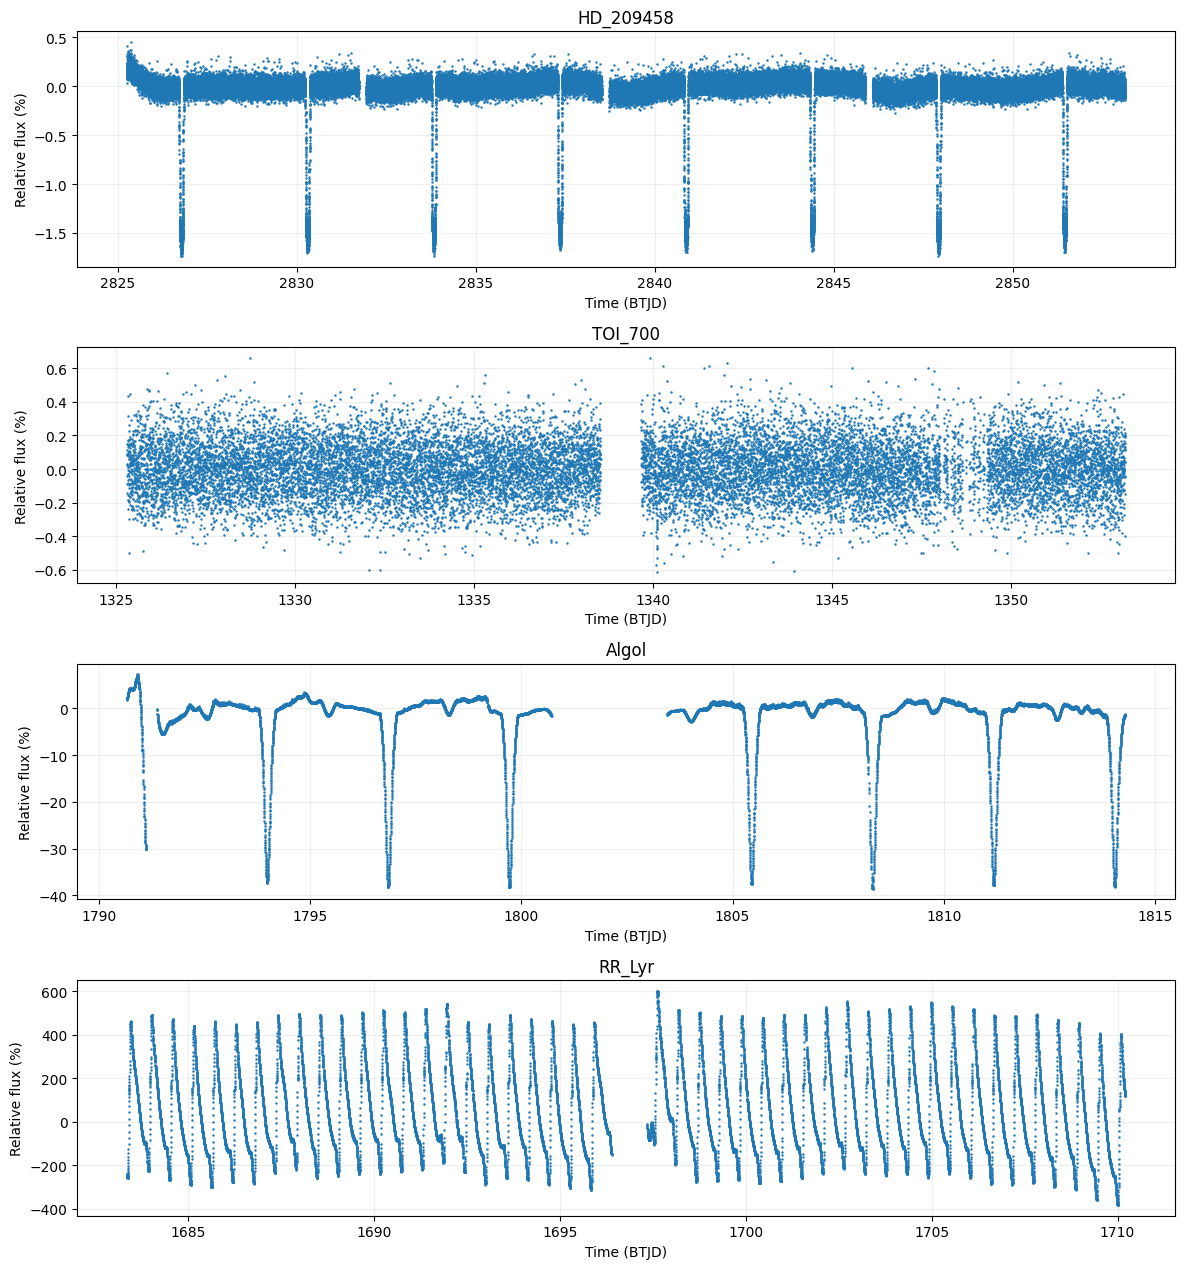

In [ ]:
# Inspect raw pilot light curves

if not lightcurves:
    print("No light curves were downloaded. Check the previous cell's output.")
else:
    fig, axes = plt.subplots(
        len(lightcurves), 1,
        figsize=(12, 3.2 * len(lightcurves)),
        squeeze=False
    )

    for ax, (name, lc) in zip(axes[:, 0], lightcurves.items()):
        t = np.asarray(lc.time.value, dtype=float)
        f = np.asarray(lc.flux.value, dtype=float)

        valid = np.isfinite(t) & np.isfinite(f)
        t, f = t[valid], f[valid]

        # Relative flux is for visual comparison only.
        median_flux = np.median(f)
        if median_flux != 0:
            relative_flux = (f / median_flux - 1) * 100
        else:
            relative_flux = f

        ax.plot(t, relative_flux, ".", markersize=1.5)
        ax.set_title(name)
        ax.set_xlabel("Time (BTJD)")
        ax.set_ylabel("Relative flux (%)")
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        "/content/STARTRACE/results/figures/pilot_lightcurves.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()


## Build the catalogue-backed target list

In [ ]:
# Retrieve an authoritative reference catalogue

PROJECT_DIR = "/content/STARTRACE"
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")

os.makedirs(RAW_DIR, exist_ok=True)

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

query = """
SELECT DISTINCT hostname
FROM ps
WHERE default_flag = 1
AND tran_flag = 1
ORDER BY hostname
"""

print("Querying NASA Exoplanet Archive...")

response = requests.get(
    url,
    params={"query": query, "format": "csv"},
    timeout=90
)
response.raise_for_status()

planet_hosts = pd.read_csv(StringIO(response.text))
planet_hosts = planet_hosts.dropna(subset=["hostname"])
planet_hosts = planet_hosts.drop_duplicates(
    subset=["hostname"]
).reset_index(drop=True)

catalog_path = os.path.join(
    RAW_DIR, "confirmed_transiting_planet_hosts.csv"
)
planet_hosts.to_csv(catalog_path, index=False)

print("Catalogue downloaded successfully.")
print("Unique host stars:", len(planet_hosts))
print("Saved to:", catalog_path)
display(planet_hosts.head(15))


Querying NASA Exoplanet Archive...
Catalogue downloaded successfully.
Unique host stars: 3687
Saved to: /content/STARTRACE/data/raw/confirmed_transiting_planet_hosts.csv


,hostname
0,55 Cnc
1,AU Mic
2,BD+05 4868 A
3,BD+20 594
4,BD-14 3065 A
5,CoRoT-1
6,CoRoT-10
7,CoRoT-11
8,CoRoT-12
9,CoRoT-13


## Turn the planet catalogue into usable scientific labels

In [ ]:
RAW_DIR = "/content/STARTRACE/data/raw"
os.makedirs(RAW_DIR, exist_ok=True)

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

query = """
SELECT pl_name, hostname, pl_orbper, pl_tranmid,
       pl_trandur, tran_flag, default_flag, disc_facility
FROM ps
WHERE tran_flag = 1
  AND default_flag = 1
  AND pl_orbper IS NOT NULL
  AND pl_tranmid IS NOT NULL
  AND pl_trandur IS NOT NULL
ORDER BY hostname
"""

print("Retrieving planets with usable transit ephemerides...")

response = requests.get(
    url,
    params={"query": query, "format": "csv"},
    timeout=90
)
response.raise_for_status()

ephemerides = pd.read_csv(StringIO(response.text))

# Remove incomplete or physically unusable entries.
for col in ["pl_orbper", "pl_tranmid", "pl_trandur"]:
    ephemerides[col] = pd.to_numeric(
        ephemerides[col], errors="coerce"
    )

ephemerides = ephemerides.dropna(
    subset=["hostname", "pl_orbper", "pl_tranmid", "pl_trandur"]
)

ephemerides = ephemerides[
    (ephemerides["pl_orbper"] > 0) &
    (ephemerides["pl_trandur"] > 0)
].copy()

# BJD to BTJD conversion: BTJD = BJD - 2457000.
ephemerides["transit_epoch_btjd"] = (
    ephemerides["pl_tranmid"] - 2457000.0
)

save_path = os.path.join(
    RAW_DIR, "transit_ephemerides.csv"
)
ephemerides.to_csv(save_path, index=False)

print("\nEPHEMERIS CATALOGUE")
print("Planet records:", len(ephemerides))
print("Unique host stars:", ephemerides["hostname"].nunique())
print("Saved:", save_path)

display(ephemerides.head(15))


Retrieving planets with usable transit ephemerides...

EPHEMERIS CATALOGUE
Planet records: 3393
Unique host stars: 2634
Saved: /content/STARTRACE/data/raw/transit_ephemerides.csv


,pl_name,hostname,pl_orbper,pl_tranmid,pl_trandur,tran_flag,default_flag,disc_facility,transit_epoch_btjd
0,AU Mic c,AU Mic,18.859023,2.458342e+06,4.29000,1,1,Transiting Exoplanet Survey Satellite (TESS),1342.223325
1,AU Mic b,AU Mic,8.463446,2.458330e+06,3.24000,1,1,Transiting Exoplanet Survey Satellite (TESS),1330.350878
2,BD-14 3065 b,BD-14 3065 A,4.288973,2.459313e+06,3.08600,1,1,Transiting Exoplanet Survey Satellite (TESS),2313.485780
3,CoRoT-10 b,CoRoT-10,13.240600,2.454273e+06,2.98000,1,1,CoRoT,-2726.656400
4,CoRoT-11 b,CoRoT-11,2.994330,2.454598e+06,2.50090,1,1,CoRoT,-2402.321000
5,CoRoT-12 b,CoRoT-12,2.828042,2.454399e+06,2.57424,1,1,CoRoT,-2601.372930
6,CoRoT-13 b,CoRoT-13,4.035190,2.454791e+06,3.14000,1,1,CoRoT,-2209.190900
7,CoRoT-14 b,CoRoT-14,1.512140,2.454788e+06,1.66200,1,1,CoRoT,-2212.330600
8,CoRoT-16 b,CoRoT-16,5.352270,2.454924e+06,2.39000,1,1,CoRoT,-2076.086200
9,CoRoT-17 b,CoRoT-17,3.768100,2.454923e+06,4.72001,1,1,CoRoT,-2076.690700


In [ ]:
RAW_DIR = "/content/STARTRACE/data/raw"

ephemerides = pd.read_csv(
    os.path.join(RAW_DIR, "transit_ephemerides.csv")
)
manifest = pd.read_csv(
    os.path.join(RAW_DIR, "pilot_manifest.csv")
)

# Use the time ranges measured from the downloaded TESS observations.
pilot_ranges = {
    "HD_209458": (2825.262051, 2853.143860),
    "TOI_700": (1325.295495, 1353.175974),
    "Algol": (1790.661752, 1814.297974),
    "RR_Lyr": (1683.356471, 1710.206415),
}

# Normalize names for matching.
def normalize_name(s):
    return str(s).lower().replace(" ", "").replace("-", "")

ephemerides["host_key"] = ephemerides["hostname"].map(normalize_name)

pilot_aliases = {
    "HD_209458": ["HD 209458"],
    "TOI_700": ["TOI-700"],
    "Algol": ["Algol"],
    "RR_Lyr": ["RR Lyrae", "RR Lyr"],
}

matches = []

for target, aliases in pilot_aliases.items():
    start, end = pilot_ranges[target]
    alias_keys = [normalize_name(x) for x in aliases]

    subset = ephemerides[
        ephemerides["host_key"].isin(alias_keys)
    ]

    if subset.empty:
        matches.append({
            "target": target,
            "planet": None,
            "coverage_start_btjd": start,
            "coverage_end_btjd": end,
            "expected_transits": 0,
            "status": "No matching confirmed transiting planet"
        })
        continue

    for _, row in subset.iterrows():
        period = float(row["pl_orbper"])
        epoch = float(row["transit_epoch_btjd"])

        # Transit centers within the observing interval.
        first_n = int(np.ceil((start - epoch) / period))
        last_n = int(np.floor((end - epoch) / period))
        n_events = max(0, last_n - first_n + 1)

        matches.append({
            "target": target,
            "planet": row["pl_name"],
            "period_days": period,
            "reference_epoch_btjd": epoch,
            "duration_hours": float(row["pl_trandur"]),
            "coverage_start_btjd": start,
            "coverage_end_btjd": end,
            "expected_transits": n_events,
            "status": (
                "Predicted transit centers in coverage"
                if n_events > 0 else
                "No predicted transit centers in coverage"
            )
        })

crossmatch = pd.DataFrame(matches)
out_path = os.path.join(RAW_DIR, "pilot_ephemeris_crossmatch.csv")
crossmatch.to_csv(out_path, index=False)

print("PILOT TARGET / EPHEMERIS CROSS-MATCH")
display(crossmatch)
print("Saved:", out_path)


PILOT TARGET / EPHEMERIS CROSS-MATCH


,target,planet,coverage_start_btjd,coverage_end_btjd,expected_transits,status,period_days,reference_epoch_btjd,duration_hours
0,HD_209458,None,2825.262051,2853.143860,0,No matching confirmed transiting planet,NaN,NaN,NaN
1,TOI_700,TOI-700 b,1325.295495,1353.175974,3,Predicted transit centers in coverage,9.977220,1880.09940,2.1300
2,TOI_700,TOI-700 c,1325.295495,1353.175974,1,Predicted transit centers in coverage,16.051104,1821.62190,1.3990
3,TOI_700,TOI-700 e,1325.295495,1353.175974,1,Predicted transit centers in coverage,27.810124,3772.46343,3.0593
4,TOI_700,TOI-700 d,1325.295495,1353.175974,1,Predicted transit centers in coverage,37.423457,3763.01612,3.3029
5,Algol,None,1790.661752,1814.297974,0,No matching confirmed transiting planet,NaN,NaN,NaN
6,RR_Lyr,None,1683.356471,1710.206415,0,No matching confirmed transiting planet,NaN,NaN,NaN


Saved: /content/STARTRACE/data/raw/pilot_ephemeris_crossmatch.csv


In [ ]:
base = Path("/content/STARTRACE/data/raw")
ephemerides_path = base / "transit_ephemerides.csv"

ephemerides = pd.read_csv(ephemerides_path)

# Inspect the exact catalogue names first.
print("Catalogue rows matching either target:")
mask = ephemerides["hostname"].astype(str).str.contains(
    r"209458|TOI.?700", case=False, regex=True, na=False
)

display(
    ephemerides.loc[mask, [
        "hostname", "pl_name", "pl_orbper",
        "pl_tranmid", "pl_trandur", "disc_facility"
    ]].sort_values(["hostname", "pl_name"])
)

# Inspect the original stored host names for HD 209458.
print("\nUnique host names containing 209458:")
display(
    ephemerides.loc[
        ephemerides["hostname"].astype(str).str.contains(
            "209458", case=False, na=False
        ),
        ["hostname", "pl_name", "pl_orbper", "pl_tranmid"]
    ]
)


Catalogue rows matching either target:


,hostname,pl_name,pl_orbper,pl_tranmid,pl_trandur,disc_facility
3235,TOI-700,TOI-700 b,9.977220,2.458880e+06,2.13000,Transiting Exoplanet Survey Satellite (TESS)
3236,TOI-700,TOI-700 c,16.051104,2.458822e+06,1.39900,Transiting Exoplanet Survey Satellite (TESS)
3238,TOI-700,TOI-700 d,37.423457,2.460763e+06,3.30290,Transiting Exoplanet Survey Satellite (TESS)
3237,TOI-700,TOI-700 e,27.810124,2.460772e+06,3.05930,Transiting Exoplanet Survey Satellite (TESS)
3239,TOI-7008,TOI-7008 b,0.840690,2.459412e+06,1.67023,Transiting Exoplanet Survey Satellite (TESS)
3240,TOI-7009,TOI-7009 b,2.320661,2.460392e+06,1.22700,Transiting Exoplanet Survey Satellite (TESS)



Unique host names containing 209458:


,hostname,pl_name,pl_orbper,pl_tranmid


In [ ]:
base = Path("/content/STARTRACE/data/raw")
base.mkdir(parents=True, exist_ok=True)

query = """
SELECT hostname, pl_name, pl_orbper, pl_tranmid,
       pl_trandur, pl_tranmiderr1, pl_tranmiderr2,
       pl_orbpererr1, pl_orbpererr2, tran_flag, default_flag
FROM ps
WHERE hostname LIKE '%209458%'
  AND tran_flag = 1
  AND default_flag = 1
"""

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

try:
    response = requests.get(
        url,
        params={"query": query, "format": "csv"},
        timeout=60
    )
    response.raise_for_status()

    hd209458 = pd.read_csv(StringIO(response.text))

    if hd209458.empty:
        print("Query succeeded, but no matching rows were returned.")
    else:
        display(hd209458)

        output_path = base / "HD_209458_ephemeris.csv"
        hd209458.to_csv(output_path, index=False)
        print(f"\nSaved catalogue results to: {output_path}")

except Exception as e:
    print("Request failed:", repr(e))


,hostname,pl_name,pl_orbper,pl_tranmid,pl_trandur,pl_tranmiderr1,pl_tranmiderr2,pl_orbpererr1,pl_orbpererr2,tran_flag,default_flag
0,HD 209458,HD 209458 b,3.524749,NaN,NaN,NaN,NaN,3.800000e-07,-3.800000e-07,1,1



Saved catalogue results to: /content/STARTRACE/data/raw/HD_209458_ephemeris.csv


In [ ]:
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

query = """
SELECT *
FROM ps
WHERE pl_name = 'HD 209458 b'
  AND default_flag = 1
"""

response = requests.get(
    url,
    params={"query": query, "format": "csv"},
    timeout=60
)
response.raise_for_status()

planet_record = pd.read_csv(StringIO(response.text))

# Show columns that could help establish transit timing.
candidate_fields = [
    c for c in planet_record.columns
    if any(term in c.lower() for term in [
        "tranmid", "trandur", "orbper", "epoch",
        "time", "transit", "ref"
    ])
]

display(planet_record[candidate_fields].T)


,0
pl_refname,<a refstr=STASSUN_ET_AL__2017 href=https://ui....
sy_refname,<a refstr=STASSUN_ET_AL__2019 href=https://ui....
disc_refname,<a refstr=HENRY_ET_AL__2000 href=https://ui.ad...
pl_orbper,3.524749
pl_orbpererr1,0.0
pl_orbpererr2,-0.0
pl_orbperlim,0
pl_orbperstr,3.52474859&plusmn;0.00000038
pl_tranmid,NaN
pl_tranmiderr1,NaN


In [ ]:
API = (
    "https://exoplanetarchive.ipac.caltech.edu/"
    "cgi-bin/TransitSearch/nph-transits-api"
)

# Coverage of the downloaded HD 209458 TESS light curve.
start_btjd = 2825.262051
end_btjd = 2853.143860

# Convert BTJD to the Julian Date convention used by this API.
begin_jd = start_btjd + 2457000.0
end_jd = end_btjd + 2457000.0

params = {
    "sname": "HD 209458 b",
    "begin": begin_jd,
    "end": end_jd,
    "most_precise_ephem": 1,
    "format": "json",
}

response = requests.get(API, params=params, timeout=60)
response.raise_for_status()
result = response.json()

print("API status:", result.get("stat"))

if result.get("stat") == "OK":
    events = pd.DataFrame(result.get("data", []))

    if events.empty:
        print("No predicted events returned for this coverage window.")
    else:
        display(events)
        events.to_csv(
            "/content/STARTRACE/data/raw/HD_209458_predicted_transits.csv",
            index=False
        )
        print("Saved predicted transit events.")
elif result.get("stat") == "PENDING":
    print("The query is still running.")
    print("Poll URL:", result.get("poll_url"))
else:
    print("API response:", result)


API status: OK


,username,defaultname,sourcetable,planetname,ra_str,ra,dec_str,dec,obsname,obslat,...,vsini,magnitude_visible,magnitude_gaia,magnitude_j,magnitude_h,magnitude_k,magnitude_w1,magnitude_w2,magnitude_w3,magnitude_w4
0,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
1,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
2,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
3,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
4,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
68,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
69,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265
70,N/A,HD 209458 b,Planetary Systems Planet Data,HD 209458 b,22h03m10.81s,330.795022,18d53m03.27s,18.884242,N/A,N/A,...,4.4,7.65,7.50866,6.591,6.366,6.308,6.308,6.191,6.32,6.265


Saved predicted transit events.


In [ ]:
path = Path(
    "/content/STARTRACE/data/raw/HD_209458_predicted_transits.csv"
)

events = pd.read_csv(path)

print("Rows:", len(events))
print("\nAll column names:")
print(events.columns.tolist())

# Find columns potentially related to predicted events.
terms = ["transit", "mid", "time", "begin", "end", "epoch", "duration", "error"]

relevant = [
    col for col in events.columns
    if any(term in col.lower() for term in terms)
]

print("\nTransit/time-related columns:", relevant)

if relevant:
    display(events[relevant].head(15))

print("\nUnique rows:", len(events.drop_duplicates()))


Rows: 72

All column names:
['username', 'defaultname', 'sourcetable', 'planetname', 'ra_str', 'ra', 'dec_str', 'dec', 'obsname', 'obslat', 'obslon', 'refname', 'refpubldate', 'refid', 'solnid', 'reflink', 'algorithm', 'isdefault', 'ismostprecise', 'hasmoreprecise', 'eccenwarning', 'phase', 'period', 'eccen', 'fsini', 'transitduration', 'transitdepthdb', 'transitdepthcalc', 'ttv', 'onesigmawindowstartcalendar', 'onesigmawindowstartjd', 'onesigmawindowstartairmass', 'onesigmawindowstartaltitude', 'onesigmawindowstartazimuth', 'ingresscalendar', 'ingressjd', 'ingressairmass', 'ingressaltitude', 'ingressazimuth', 'midpointcalendar', 'midpointjd', 'propmidpointunc', 'midpointairmass', 'midpointaltitude', 'midpointazimuth', 'egresscalendar', 'egressjd', 'egressairmass', 'egressaltitude', 'egressazimuth', 'onesigmawindowendcalendar', 'onesigmawindowendjd', 'onesigmawindowendairmass', 'onesigmawindowendaltitude', 'onesigmawindowendazimuth', 'targetrisecalendar', 'targetrisejd', 'targetsetcale

,transitduration,transitdepthdb,transitdepthcalc,onesigmawindowstartcalendar,ingresscalendar,midpointcalendar,midpointjd,propmidpointunc,midpointairmass,midpointaltitude,...,targetobsstartcalendar,targetobsendcalendar,targetobsendjd,sunsetcalendar,sunrisecalendar,targetobsduration,durationbeforeevent,durationafterevent,durationoutsideevent,durationinsideevent
0,NaN,NaN,0.0,NaN,NaN,09/04/2022 06:45,2.459827e+06,0.000560,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,0.0,NaN,NaN,09/07/2022 19:21,2.459830e+06,0.000560,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,0.0,NaN,NaN,09/11/2022 07:57,2.459834e+06,0.000561,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,0.0,NaN,NaN,09/14/2022 20:32,2.459837e+06,0.000561,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,0.0,NaN,NaN,09/18/2022 09:08,2.459841e+06,0.000561,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,0.0,NaN,NaN,09/21/2022 21:44,2.459844e+06,0.000562,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,0.0,NaN,NaN,09/25/2022 10:19,2.459848e+06,0.000562,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,0.0,NaN,NaN,09/28/2022 22:55,2.459851e+06,0.000562,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,0.0,NaN,NaN,09/04/2022 06:46,2.459827e+06,0.000530,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,0.0,NaN,NaN,09/07/2022 19:22,2.459830e+06,0.000530,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique rows: 72


In [ ]:
path = Path(
    "/content/STARTRACE/data/raw/HD_209458_predicted_transits.csv"
)
events = pd.read_csv(path)

start_btjd = 2825.262051
end_btjd = 2853.143860

# Convert predicted Julian Date midpoints to BTJD.
events["midpointjd"] = pd.to_numeric(
    events["midpointjd"], errors="coerce"
)
events["midpoint_btjd"] = events["midpointjd"] - 2457000.0

#Inspecting the uncertainty
for col in ["ismostprecise", "isdefault", "hasmoreprecise"]:
    if col in events.columns:
        print(f"\n{col} counts:")
        print(events[col].value_counts(dropna=False))

summary_cols = [
    c for c in [
        "refname", "refpubldate", "algorithm",
        "isdefault", "ismostprecise", "hasmoreprecise",
        "period", "midpointcalendar", "midpointjd",
        "midpoint_btjd", "propmidpointunc"
    ]
    if c in events.columns
]

print("\nEphemeris solutions:")
display(events[summary_cols].drop_duplicates().head(25))

# Only show predicted midpoints within the observed TESS coverage.
in_coverage = events[
    events["midpoint_btjd"].between(start_btjd, end_btjd)
].copy()

print("\nPredicted midpoint rows inside TESS coverage:", len(in_coverage))
display(in_coverage[summary_cols].head(30))



ismostprecise counts:
ismostprecise
0    64
1     8
Name: count, dtype: int64

isdefault counts:
isdefault
0    72
Name: count, dtype: int64

hasmoreprecise counts:
hasmoreprecise
0    72
Name: count, dtype: int64

Ephemeris solutions:


,refname,refpubldate,algorithm,isdefault,ismostprecise,hasmoreprecise,period,midpointcalendar,midpointjd,midpoint_btjd,propmidpointunc
0,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/04/2022 06:45,2.459827e+06,2826.781497,0.000560
1,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/07/2022 19:21,2.459830e+06,2830.306247,0.000560
2,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/11/2022 07:57,2.459834e+06,2833.830997,0.000561
3,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/14/2022 20:32,2.459837e+06,2837.355746,0.000561
4,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/18/2022 09:08,2.459841e+06,2840.880496,0.000561
5,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/21/2022 21:44,2.459844e+06,2844.405245,0.000562
6,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/25/2022 10:19,2.459848e+06,2847.929995,0.000562
7,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/28/2022 22:55,2.459851e+06,2851.454744,0.000562
8,Kokori et al. 2022,2022-02,Transit Ephemeris (Circular Orbit),0,1,0,3.524750,09/04/2022 06:46,2.459827e+06,2826.782053,0.000530
9,Kokori et al. 2022,2022-02,Transit Ephemeris (Circular Orbit),0,1,0,3.524750,09/07/2022 19:22,2.459830e+06,2830.306803,0.000530



Predicted midpoint rows inside TESS coverage: 72


,refname,refpubldate,algorithm,isdefault,ismostprecise,hasmoreprecise,period,midpointcalendar,midpointjd,midpoint_btjd,propmidpointunc
0,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/04/2022 06:45,2.459827e+06,2826.781497,0.000560
1,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/07/2022 19:21,2.459830e+06,2830.306247,0.000560
2,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/11/2022 07:57,2.459834e+06,2833.830997,0.000561
3,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/14/2022 20:32,2.459837e+06,2837.355746,0.000561
4,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/18/2022 09:08,2.459841e+06,2840.880496,0.000561
5,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/21/2022 21:44,2.459844e+06,2844.405245,0.000562
6,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/25/2022 10:19,2.459848e+06,2847.929995,0.000562
7,Kokori et al. 2023,2023-03,Transit Ephemeris (Circular Orbit),0,0,0,3.524750,09/28/2022 22:55,2.459851e+06,2851.454744,0.000562
8,Kokori et al. 2022,2022-02,Transit Ephemeris (Circular Orbit),0,1,0,3.524750,09/04/2022 06:46,2.459827e+06,2826.782053,0.000530
9,Kokori et al. 2022,2022-02,Transit Ephemeris (Circular Orbit),0,1,0,3.524750,09/07/2022 19:22,2.459830e+06,2830.306803,0.000530


---

# 🔭 Part 2 — Cleaning, Windowing, First Model, and Data Audits

## What I worked on

After collecting the TESS observations, I moved on to preparing the data for machine learning. This stage involved cleaning the light curves, turning them into smaller windows, training my first autoencoder, and checking the data for issues that could affect the results.

I also built an interactive inspector and carried out separate audits of Algol and RR Lyrae. I wanted to understand the data I was feeding into the model rather than simply train a network and assume everything was working correctly.

## 1. Cleaning the light curves

I started by keeping observations with finite flux values and a quality flag of zero. I then used a robust median-and-MAD method to identify and remove outliers beyond five robust standard deviations.

After that, I normalised each light curve around a flux level of 1.0.

The number of observations retained after cleaning was:

| Target | Observations retained |
|---|---:|
| HD 209458 | 110,897 |
| TOI-700 | 18,279 |
| Algol | 13,247 |
| RR Lyrae | 18,292 |

This gave me a cleaner starting point for the next stage, although cleaning alone does not guarantee that every remaining feature is astrophysical.

## 2. Creating fixed-length windows

The cleaned light curves were not all the same length, so I divided them into windows of **256 samples**, using a stride of 128 samples. This meant neighbouring windows overlapped by half their length.

I also skipped windows that crossed large gaps in the observations, defined as gaps greater than five times the cadence.

To make the signals easier to work with, I applied robust scaling using the median and MAD for each target, clipping the scaled values to the range of −8 to +8.

The final dataset contained **1,158 windows**.

This step transformed the original light curves into a consistent format that I could use to train and evaluate the model. However, because the windows overlap, they cannot be treated as fully independent observations.

## 3. Training my first autoencoder — v1

With the windows prepared, I trained my first convolutional autoencoder using data from HD 209458, TOI-700, and Algol. RR Lyrae was held out from training so I could examine how the model behaved on a target it had not seen during training.

The model was trained for 12 epochs using 1,031 windows.

| Training result | MAE |
|---|---:|
| Final training error | 0.582 |
| Validation error | 0.414 |

These results gave me my first working baseline for reconstructing the stellar signals.

However, I did not want to judge the model using a single overall score. Different stars have different signal characteristics, and a model that reconstructs one target reasonably well may struggle with another. That is why I also evaluated the reconstruction errors separately for each target.

## 4. Building an interactive light-curve inspector

I also built an interactive inspector widget to examine individual windows and compare their original signals with the model's reconstructions.

The inspector displays each window's reconstruction error and its unusualness percentile relative to the evaluated windows.

This made it easier to identify windows worth examining more closely instead of relying only on aggregate metrics.

One distinction I kept in mind was that **a high reconstruction error does not automatically mean an astronomical event has occurred**. It only indicates that the model reconstructed that particular window less accurately relative to the evaluation being used.

## 5. Auditing Algol

Algol was one of the targets I examined more closely because its eclipsing-binary behaviour makes changes in brightness particularly relevant to the project.

I inspected window 956, covering BTJD 1791.381–1791.748, and checked its flux values and surrounding observations.

The window had a median flux of **0.958**, and a gap of approximately **512 minutes** preceded it. I also found that the full light curve contained 15 observing segments.

To explore potentially interesting low-flux behaviour, I applied a threshold at the 10th percentile, corresponding to a flux value of 0.981. This identified **33 candidate low-flux runs**.

I saved these candidates with audit notes explicitly stating that they were exploratory rather than confirmed eclipses.

The point of this audit was to identify regions that deserved further investigation, not to assign astronomical labels based on brightness alone. Gaps, instrumental effects, and the shape of the surrounding signal all matter when interpreting a possible event.

## 6. Investigating the RR Lyrae flux issue

RR Lyrae required a different kind of investigation.

Its processed flux values ranged from **−2.83 to 7.03**, with a standard deviation of 2.13 and 5,441 negative values.

Rather than immediately treating these values as a model or processing failure, I compared them with the raw flux in the original FITS file. I found that approximately 30% of the raw flux values were negative, so I inspected the FITS header and available data columns to understand the discrepancy.

I then queried the archive again using the target's TIC identifier, **TIC 159717514**. This returned six products, and I downloaded the SPOC Sector 14 product for further inspection.

This investigation highlighted an important issue: the flux representation and the way it is processed can affect the signal that eventually reaches the model. It also reinforced the need to trace unexpected values back to their source before drawing conclusions from them.

## 7. Checking the dataset

Before moving further, I ran a dataset audit.

The audit confirmed that all saved window values were finite and that the windows had no missing metadata.

However, the quality report still marked the catalogue label for every target as **unverified**.

That distinction matters. A dataset can be technically clean and ready for model training without having independently verified labels for evaluating astrophysical events.

## 8. Evaluating the first model

I evaluated v1 separately on each target to see how its reconstruction performance varied.

| Target | Reconstruction MAE | Improvement over zero baseline |
|---|---:|---:|
| Algol | 0.140 | 81.2% |
| HD 209458 | 0.575 | 28.6% |
| RR Lyrae | 0.105 | 87.0% |
| TOI-700 | 0.668 | 15.8% |

The model performed differently across the four targets. Its MAE was lower for Algol and RR Lyrae, while TOI-700 had the highest reconstruction error and the smallest improvement over the zero baseline.

These comparisons helped me see why evaluating each target separately is important. An overall validation score can hide substantial differences in how a model handles different signals.

### Testing the held-out RR Lyrae data

I also tested how the model responded when I deliberately made the held-out RR Lyrae inputs more difficult to reconstruct.

- Adding noise increased the MAE to **0.125**.
- Replacing 20% of the samples with zeros increased the MAE to **0.255**.

The results showed that reconstruction performance depended on the condition of the input signal, with the zero-filled test producing a larger error.

### Looking more closely at TOI-700

TOI-700 window 843 was another useful example. Its reconstruction retained only **38.8% of the original signal's standard deviation**, with a correlation of **0.409**.

This suggested that the reconstruction did not preserve the signal's variation particularly well in that window. It was a useful reminder that a numerical reconstruction error alone does not tell the whole story; the shape and variation of the reconstructed signal also deserve attention.

## 9. Progress report

At the end of this stage, I saved a progress report recording the project's status against its objectives.

By this point, I had a cleaned and windowed dataset, a first trained autoencoder, an interactive inspection tool, individual target audits, and an evaluation report highlighting both the model's strengths and its weaknesses.

## What I learned from Part 2

This stage taught me that preparing astronomical data and checking its quality are just as important as building the neural network itself.

The first model gave me a starting point, but its performance varied between targets. The Algol audit produced candidate low-flux regions rather than confirmed events, while the RR Lyrae investigation showed why unexpected flux values need to be traced back to the original observations.

I also became more careful about distinguishing technical success from scientific validation. Having finite data, a trained model, and measurable reconstruction scores does not automatically mean the model has learned meaningful astrophysical patterns.

**The main outcome of Part 2 was a working first autoencoder, a dataset of 1,158 windows, and a set of data-quality and model-evaluation results that helped guide the next stage of STARTRACE.**

---

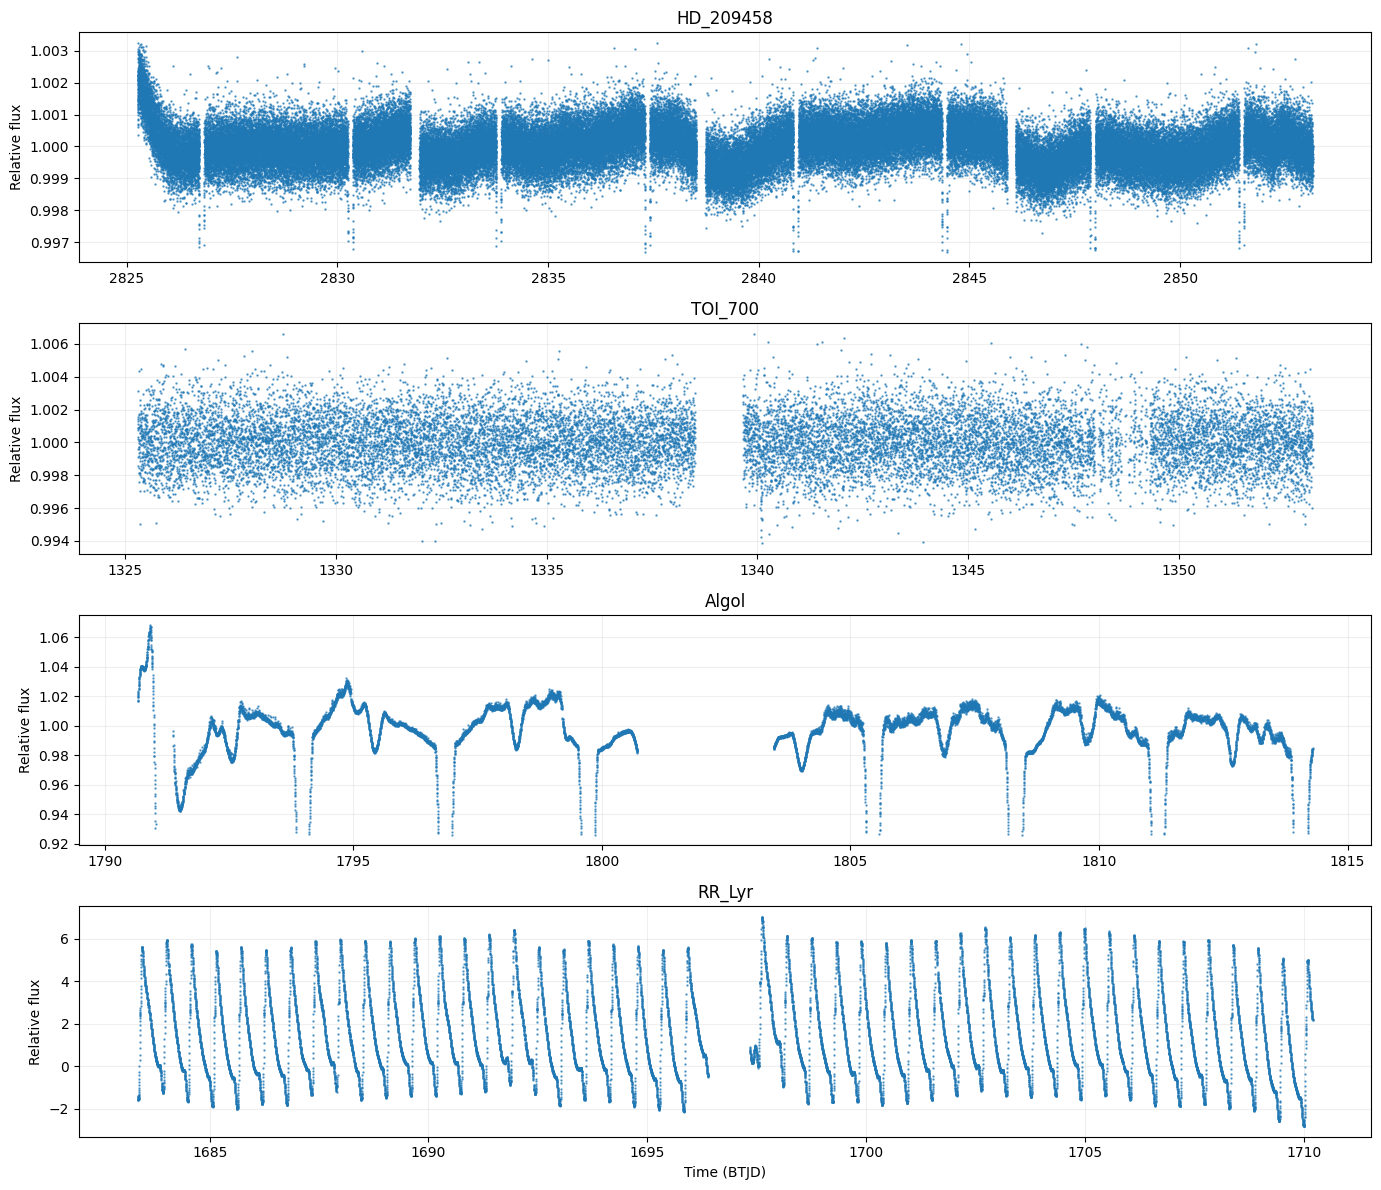

,target,retained_observations,time_start_btjd,time_end_btjd,relative_flux_std,saved_to
0,HD_209458,110897,2825.262051,2853.143860,0.000654,/content/STARTRACE/data/processed/HD_209458_cl...
1,TOI_700,18279,1325.295495,1353.175974,0.001656,/content/STARTRACE/data/processed/TOI_700_clea...
2,Algol,13247,1790.661752,1814.297974,0.016182,/content/STARTRACE/data/processed/Algol_clean.csv
3,RR_Lyr,18292,1683.356471,1710.206415,2.125370,/content/STARTRACE/data/processed/RR_Lyr_clean...



Clean curves saved: 4
Summary: /content/STARTRACE/data/processed/pilot_summary.csv
Plot: /content/STARTRACE/results/figures/pilot_light_curves.png


In [ ]:
ROOT = Path("/content/STARTRACE")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"

PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

targets = {
    "HD_209458": "HD_209458_pilot.fits",
    "TOI_700": "TOI_700_pilot.fits",
    "Algol": "Algol_pilot.fits",
    "RR_Lyr": "RR_Lyr_pilot.fits",
}

clean_curves = {}
summary = []

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

for ax, (target, filename) in zip(axes, targets.items()):
    path = RAW / filename

    if not path.exists():
        print(f"SKIPPED — file not found: {path}")
        continue

    lc = lk.read(path)

    time = np.asarray(lc.time.value, dtype=float)
    flux = np.asarray(lc.flux.value, dtype=float)

    # Retain finite measurements and reject flagged cadences.
    valid = np.isfinite(time) & np.isfinite(flux)

    try:
        quality = np.asarray(lc.quality)
        valid &= (quality == 0)
    except (AttributeError, TypeError):
        pass

    time = time[valid]
    flux = flux[valid]

    # Remove extreme outliers using a robust median/MAD criterion.
    median = np.median(flux)
    mad = np.median(np.abs(flux - median))

    if mad > 0:
        robust_sigma = 1.4826 * mad
        keep = np.abs(flux - median) < 5 * robust_sigma
        time, flux = time[keep], flux[keep]

    # Normalize around 1.0 so targets with different brightness
    # can be compared by their relative variability.
    baseline = np.median(flux)
    normalized_flux = flux / baseline

    curve = pd.DataFrame({
        "time_btjd": time,
        "normalized_flux": normalized_flux,
    }).sort_values("time_btjd")

    output = PROCESSED / f"{target}_clean.csv"
    curve.to_csv(output, index=False)
    clean_curves[target] = curve

    ax.plot(
        curve["time_btjd"],
        curve["normalized_flux"],
        ".",
        markersize=1.5,
        alpha=0.65
    )
    ax.set_title(target)
    ax.set_ylabel("Relative flux")
    ax.grid(alpha=0.2)

    summary.append({
        "target": target,
        "retained_observations": len(curve),
        "time_start_btjd": curve["time_btjd"].min(),
        "time_end_btjd": curve["time_btjd"].max(),
        "relative_flux_std": curve["normalized_flux"].std(),
        "saved_to": str(output),
    })

axes[-1].set_xlabel("Time (BTJD)")
plt.tight_layout()

plot_path = FIGURES / "pilot_light_curves.png"
plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

summary_df = pd.DataFrame(summary)
display(summary_df)

summary_df.to_csv(PROCESSED / "pilot_summary.csv", index=False)

print(f"\nClean curves saved: {len(clean_curves)}")
print(f"Summary: {PROCESSED / 'pilot_summary.csv'}")
print(f"Plot: {plot_path}")


## build the time-series window dataset

,target,points,flux_median,flux_min,flux_max,robust_scale,flux_std
0,HD_209458,110897,1.0,0.996688,1.003259,0.000632,0.000654
1,TOI_700,18279,1.0,0.993850,1.006604,0.001672,0.001656
2,Algol,13247,1.0,0.926054,1.067964,0.012192,0.016181
3,RR_Lyr,18292,1.0,-2.830627,7.034658,2.192788,2.125312


Window array shape: (1158, 256)
Windows per target:


,target,windows
0,Algol,75
1,HD_209458,843
2,RR_Lyr,127
3,TOI_700,113


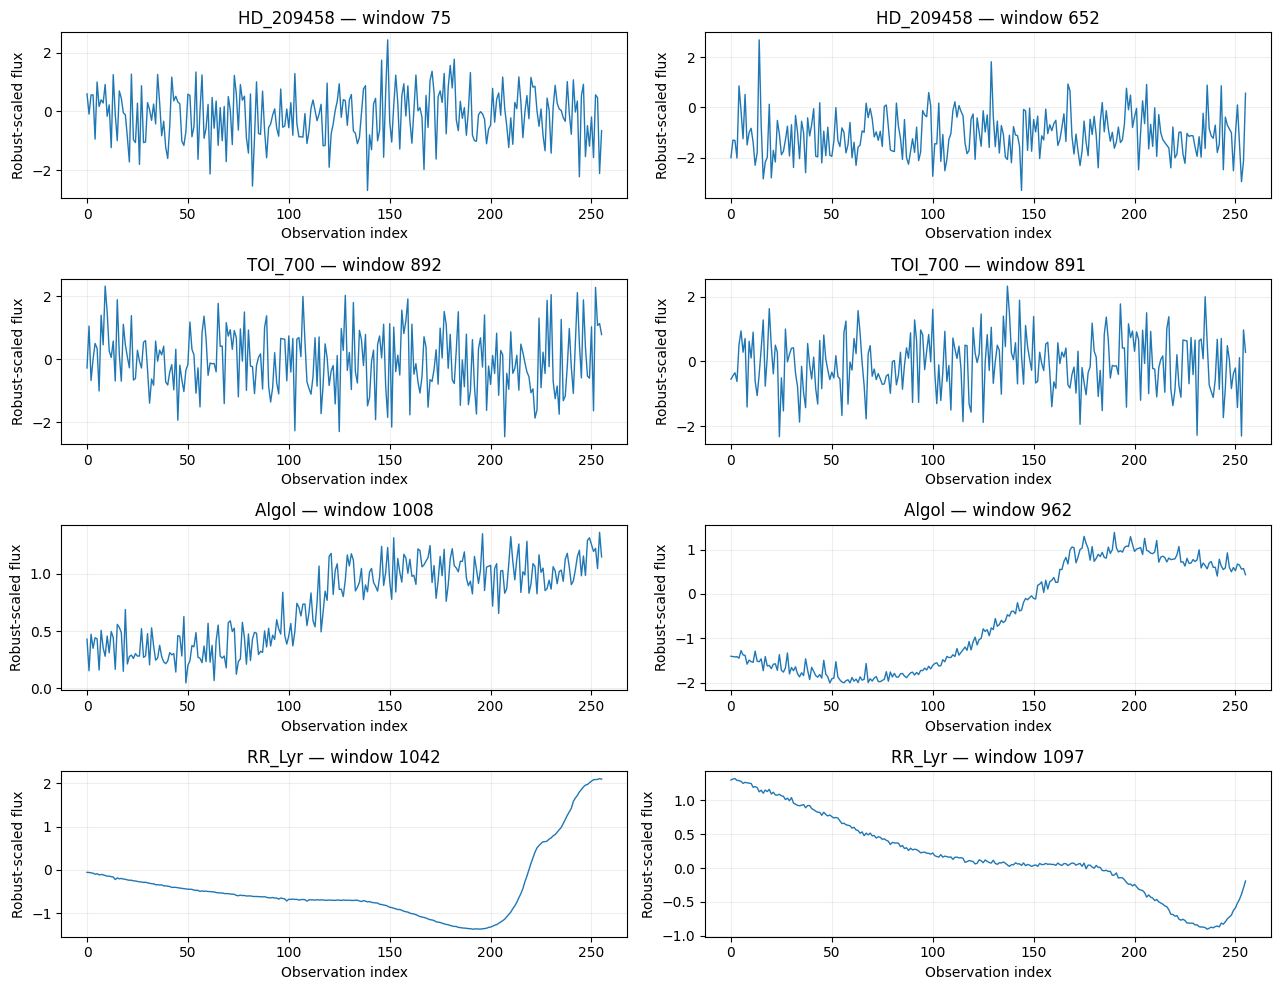

Saved X_windows.npy, window_metadata.csv, and flux_diagnostics.csv


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"

WINDOW_SIZE = 256
STRIDE = 128
windows = []
diagnostics = []

for target in ["HD_209458", "TOI_700", "Algol", "RR_Lyr"]:
    path = PROCESSED / f"{target}_clean.csv"
    df = pd.read_csv(path)

    time = df["time_btjd"].to_numpy(dtype=np.float64)
    flux = df["normalized_flux"].to_numpy(dtype=np.float64)

    finite = np.isfinite(time) & np.isfinite(flux)
    time, flux = time[finite], flux[finite]

    # Diagnose scale before generating windows.
    med = np.median(flux)
    mad = np.median(np.abs(flux - med))
    robust_scale = 1.4826 * mad

    diagnostics.append({
        "target": target,
        "points": len(flux),
        "flux_median": med,
        "flux_min": np.min(flux),
        "flux_max": np.max(flux),
        "robust_scale": robust_scale,
        "flux_std": np.std(flux),
    })

    if not np.isfinite(robust_scale) or robust_scale < 1e-10:
        print(f"Skipping {target}: unreliable robust scale.")
        continue

    # Robust per-target scaling; clipping protects training from
    # extreme excursions without changing the stored raw curve.
    scaled = np.clip((flux - med) / robust_scale, -8, 8)

    for start in range(0, len(flux) - WINDOW_SIZE + 1, STRIDE):
        end = start + WINDOW_SIZE
        t_window = time[start:end]

        # Avoid windows spanning large gaps in the observations.
        cadence = np.median(np.diff(t_window))
        if cadence <= 0:
            continue

        if np.max(np.diff(t_window)) > 5 * cadence:
            continue

        windows.append({
            "target": target,
            "start_btjd": t_window[0],
            "end_btjd": t_window[-1],
            "flux_window": scaled[start:end].astype(np.float32),
        })

diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df)

# Save model inputs and their metadata separately.
X = np.stack([item["flux_window"] for item in windows])
metadata = pd.DataFrame([
    {
        "window_id": i,
        "target": item["target"],
        "start_btjd": item["start_btjd"],
        "end_btjd": item["end_btjd"],
    }
    for i, item in enumerate(windows)
])

np.save(PROCESSED / "X_windows.npy", X)
metadata.to_csv(PROCESSED / "window_metadata.csv", index=False)
diagnostics_df.to_csv(PROCESSED / "flux_diagnostics.csv", index=False)

print("Window array shape:", X.shape)
print("Windows per target:")
display(metadata.groupby("target").size().rename("windows").reset_index())

# Visualize examples to check whether morphology is preserved.
fig, axes = plt.subplots(4, 2, figsize=(13, 10))
rng = np.random.default_rng(42)

for row, target in enumerate(["HD_209458", "TOI_700", "Algol", "RR_Lyr"]):
    ids = np.flatnonzero(metadata["target"].to_numpy() == target)

    if len(ids) == 0:
        continue

    chosen = rng.choice(ids, size=min(2, len(ids)), replace=False)

    for col, idx in enumerate(chosen):
        axes[row, col].plot(X[idx], linewidth=1)
        axes[row, col].set_title(f"{target} — window {idx}")
        axes[row, col].set_xlabel("Observation index")
        axes[row, col].set_ylabel("Robust-scaled flux")
        axes[row, col].grid(alpha=0.2)

plt.tight_layout()
plt.savefig(FIGURES / "sample_windows.png", dpi=160)
plt.show()

print("Saved X_windows.npy, window_metadata.csv, and flux_diagnostics.csv")


## diagnose RR Lyrae and let the AI learn

RR Lyrae original FITS flux diagnostics
Finite points: 18292
Flux min / median / max: -38778.98046875 13699.78466796875 96373.3046875
Fraction of negative flux: 0.29745243822436035


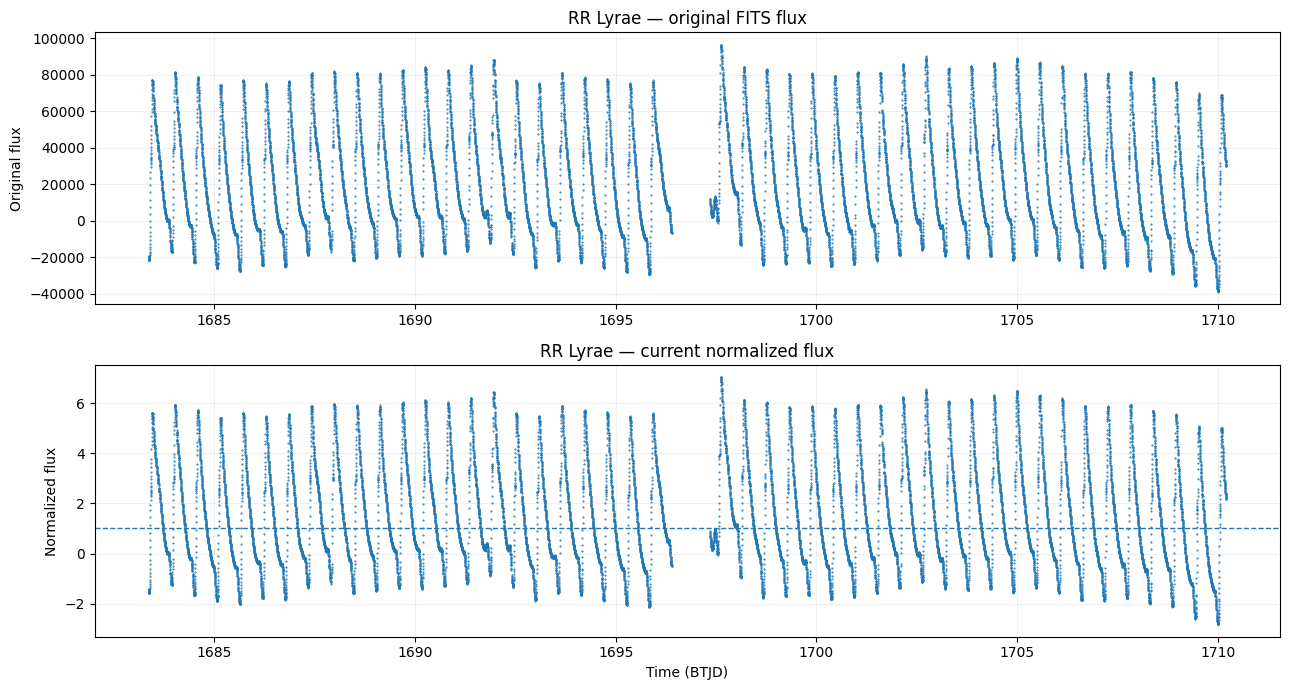

Epoch 1/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.7946 - val_loss: 0.7177
Epoch 2/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.7343 - val_loss: 0.6009
Epoch 3/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6992 - val_loss: 0.5669
Epoch 4/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6748 - val_loss: 0.5310
Epoch 5/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6425 - val_loss: 0.4706
Epoch 6/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6262 - val_loss: 0.4524
Epoch 7/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6155 - val_loss: 0.4423
Epoch 8/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6094 - val_loss: 0.4310
Epoch 9/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.6036 - val_loss: 0.4251
Epoch 10/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.5974 - val_loss: 0.4211
Epoch 11/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.5903 - val_loss: 0.4159
Epoch 12/12
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.5

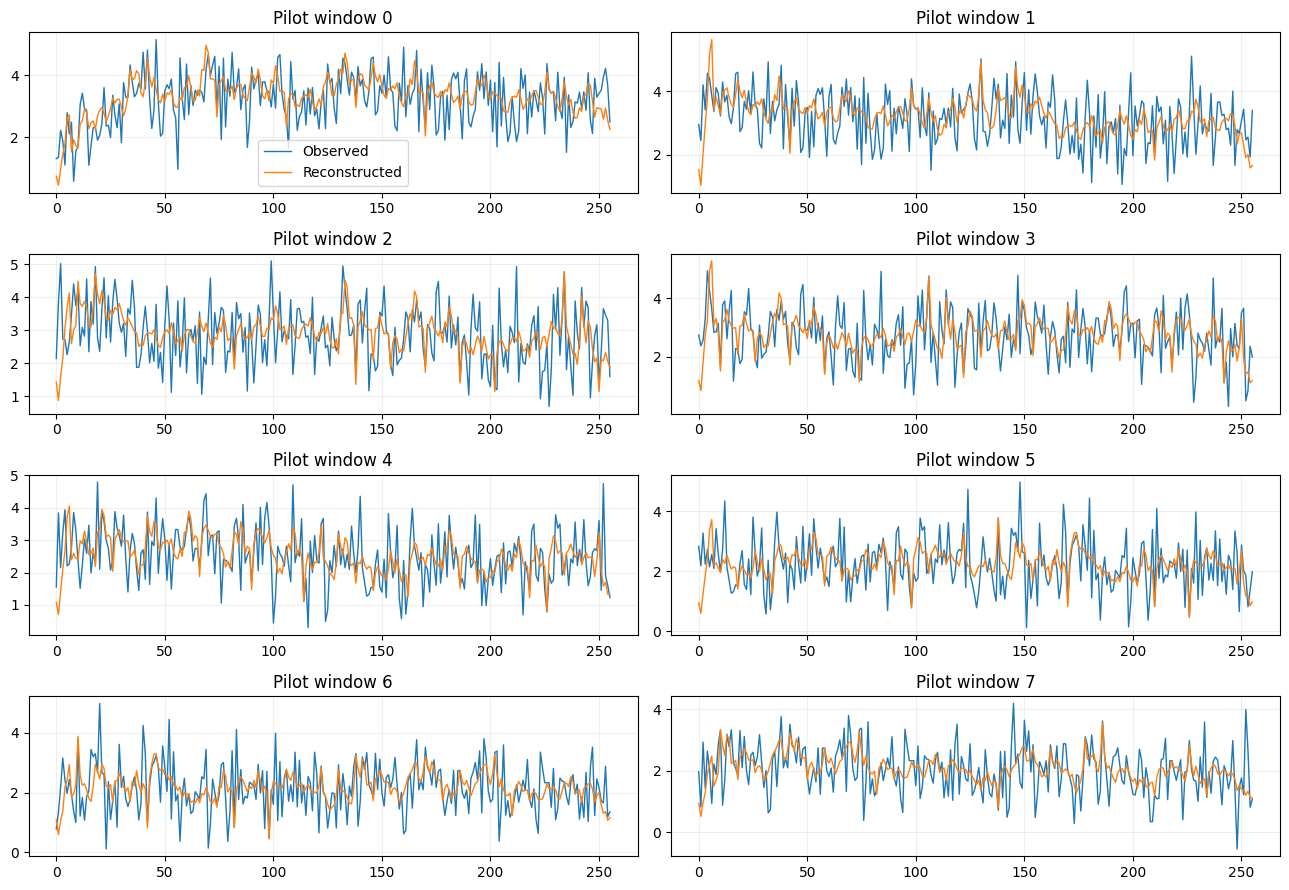


AI training complete.
Training windows: 1031
Final training MAE: 0.58217
Final validation MAE: 0.41416
Saved model: /content/STARTRACE/startrace_autoencoder.keras


In [ ]:
ROOT = Path("/content/STARTRACE")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Inspect RR Lyrae's original measurements

rr = lk.read(RAW / "RR_Lyr_pilot.fits")

raw_flux = np.asarray(rr.flux.value, dtype=np.float64)
raw_time = np.asarray(rr.time.value, dtype=np.float64)
finite = np.isfinite(raw_flux) & np.isfinite(raw_time)
raw_flux = raw_flux[finite]
raw_time = raw_time[finite]

print("RR Lyrae original FITS flux diagnostics")
print("Finite points:", len(raw_flux))
print("Flux min / median / max:",
      np.min(raw_flux), np.median(raw_flux), np.max(raw_flux))
print("Fraction of negative flux:", np.mean(raw_flux < 0))

clean_rr = pd.read_csv(PROCESSED / "RR_Lyr_clean.csv")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(raw_time, raw_flux, ".", markersize=1)
axes[0].set_title("RR Lyrae — original FITS flux")
axes[0].set_ylabel("Original flux")
axes[0].grid(alpha=0.2)

axes[1].plot(
    clean_rr["time_btjd"],
    clean_rr["normalized_flux"],
    ".",
    markersize=1
)
axes[1].axhline(1, linestyle="--", linewidth=1)
axes[1].set_title("RR Lyrae — current normalized flux")
axes[1].set_xlabel("Time (BTJD)")
axes[1].set_ylabel("Normalized flux")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig(FIGURES / "rr_lyrae_flux_audit.png", dpi=160)
plt.show()


# Train an exploratory convolutional
# autoencoder on windows from the other 3 targets.
# RR Lyrae is held out pending flux inspection.
metadata = pd.read_csv(PROCESSED / "window_metadata.csv")
X_all = np.load(PROCESSED / "X_windows.npy")

use = metadata["target"].isin(
    ["HD_209458", "TOI_700", "Algol"]
).to_numpy()

X_train = X_all[use].astype("float32")[..., np.newaxis]

tf.keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(256, 1))

x = layers.Conv1D(16, 7, strides=2, padding="same",
                  activation="relu")(inputs)
x = layers.Conv1D(8, 5, strides=2, padding="same",
                  activation="relu")(x)
encoded = layers.Conv1D(4, 3, strides=2, padding="same",
                        activation="relu", name="learned_features")(x)

x = layers.Conv1DTranspose(8, 3, strides=2, padding="same",
                           activation="relu")(encoded)
x = layers.Conv1DTranspose(16, 5, strides=2, padding="same",
                           activation="relu")(x)
outputs = layers.Conv1DTranspose(
    1, 7, strides=2, padding="same", activation="linear"
)(x)

autoencoder = keras.Model(inputs, outputs, name="STARTRACE_Autoencoder")
autoencoder.compile(optimizer="adam", loss="mae")

history = autoencoder.fit(
    X_train, X_train,
    epochs=12,
    batch_size=32,
    validation_split=0.15,
    shuffle=True,
    verbose=1,
)

# Save the learned model and training history.
autoencoder.save(ROOT / "startrace_autoencoder.keras")

pd.DataFrame({
    "epoch": np.arange(1, len(history.history["loss"]) + 1),
    "training_mae": history.history["loss"],
    "validation_mae": history.history["val_loss"],
}).to_csv(PROCESSED / "autoencoder_training_history.csv", index=False)

# Compare real windows against their reconstructions.
reconstructed = autoencoder.predict(X_train[:8], verbose=0)

fig, axes = plt.subplots(4, 2, figsize=(13, 9))
for i, ax in enumerate(axes.flat):
    ax.plot(X_train[i, :, 0], label="Observed", linewidth=1)
    ax.plot(reconstructed[i, :, 0], label="Reconstructed", linewidth=1)
    ax.set_title(f"Pilot window {i}")
    ax.grid(alpha=0.2)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / "autoencoder_reconstructions.png", dpi=160)
plt.show()

print("\nAI training complete.")
print("Training windows:", len(X_train))
print("Final training MAE:", round(history.history["loss"][-1], 5))
print("Final validation MAE:", round(history.history["val_loss"][-1], 5))
print("Saved model:", ROOT / "startrace_autoencoder.keras")


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"

metadata = pd.read_csv(PROCESSED / "window_metadata.csv")
X_all = np.load(PROCESSED / "X_windows.npy")

model_path = ROOT / "startrace_autoencoder.keras"
model = tf.keras.models.load_model(model_path)

# Exclude RR Lyrae from this initial inspector until its flux
# preprocessing has been checked.
keep = metadata["target"].isin(
    ["HD_209458", "TOI_700", "Algol"]
).to_numpy()

meta = metadata.loc[keep].reset_index(drop=True)
X = X_all[keep].astype("float32")[..., np.newaxis]

# Run inference once and cache reconstruction errors.
predictions = model.predict(X, batch_size=64, verbose=0)
meta["reconstruction_mae"] = np.mean(
    np.abs(X - predictions), axis=(1, 2)
)

# Percentile is calculated within each target because targets can
# have different distributions of reconstruction errors.
meta["unusualness_percentile"] = (
    meta.groupby("target")["reconstruction_mae"]
        .rank(pct=True) * 100
)

target_picker = widgets.Dropdown(
    options=sorted(meta["target"].unique()),
    description="Target:",
    layout=widgets.Layout(width="350px")
)

window_picker = widgets.Dropdown(
    options=[],
    description="Window:",
    layout=widgets.Layout(width="350px")
)

question = widgets.Text(
    value="Which window looks most unusual?",
    description="Ask:",
    placeholder="Ask about this light curve...",
    layout=widgets.Layout(width="650px")
)

inspect_button = widgets.Button(
    description="Inspect / Answer",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def update_window_options(change=None):
    target = target_picker.value
    ids = meta.index[meta["target"] == target].tolist()
    window_picker.options = [
        (f"Window {i} — {meta.loc[i, 'start_btjd']:.3f} BTJD", i)
        for i in ids
    ]
    if ids:
        window_picker.value = ids[0]

def inspect_window(_=None):
    with output:
        clear_output(wait=True)

        target = target_picker.value
        idx = window_picker.value

        if idx is None:
            print("No window available.")
            return

        row = meta.loc[idx]
        observed = X[idx, :, 0]
        reconstructed = predictions[idx, :, 0]

        # Find the most unusual window for this target.
        target_rows = meta[meta["target"] == target]
        most_unusual_idx = target_rows["reconstruction_mae"].idxmax()
        strongest_dip_idx = int(np.argmin(observed))
        largest_peak_idx = int(np.argmax(observed))

        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(observed, label="Observed pattern", linewidth=1.2)
        ax.plot(reconstructed, label="AI reconstruction", linewidth=1.2)
        ax.set_title(
            f"{target} | Window {idx} | "
            f"Reconstruction MAE: {row['reconstruction_mae']:.4f}"
        )
        ax.set_xlabel("Observation index within window")
        ax.set_ylabel("Robust-scaled flux")
        ax.grid(alpha=0.25)
        ax.legend()
        plt.tight_layout()
        plt.show()

        print(f"Target: {target}")
        print(
            f"Time interval: {row['start_btjd']:.5f} to "
            f"{row['end_btjd']:.5f} BTJD"
        )
        print(f"Reconstruction MAE: {row['reconstruction_mae']:.5f}")
        print(
            f"Unusualness percentile within target: "
            f"{row['unusualness_percentile']:.1f}%"
        )
        print(f"Lowest point in this window: index {strongest_dip_idx}")
        print(f"Highest point in this window: index {largest_peak_idx}")
        print(
            f"Most unusual window for {target}: window "
            f"{most_unusual_idx}, MAE "
            f"{meta.loc[most_unusual_idx, 'reconstruction_mae']:.5f}"
        )

        q = question.value.lower()

        print("\nSTARTRACE answer:")
        if any(word in q for word in ["unusual", "anomal", "strange", "odd"]):
            print(
                f"Among the pilot windows for {target}, window "
                f"{most_unusual_idx} has the largest reconstruction error. "
                "This means it is hardest for the current autoencoder to "
                "reconstruct—not that it is necessarily an astronomical event."
            )
        elif any(word in q for word in ["dip", "lowest", "minimum"]):
            print(
                f"The lowest robust-scaled point in the selected window is "
                f"at observation index {strongest_dip_idx}. A dip alone "
                "does not establish a planetary transit."
            )
        elif any(word in q for word in ["peak", "highest", "maximum"]):
            print(
                f"The highest robust-scaled point in the selected window "
                f"is at observation index {largest_peak_idx}."
            )
        elif any(word in q for word in ["reconstruct", "error", "confidence"]):
            print(
                f"The reconstruction MAE is {row['reconstruction_mae']:.5f}. "
                "This is a reconstruction error, not a probability or "
                "classification confidence."
            )
        elif any(word in q for word in ["when", "time", "interval"]):
            print(
                f"The selected window covers BTJD "
                f"{row['start_btjd']:.5f}–{row['end_btjd']:.5f}."
            )
        else:
            print(
                "I can report the selected interval, reconstruction error, "
                "largest dip, largest peak, and most unusual pilot window. "
                "Astrophysical classification requires verified event labels."
            )

target_picker.observe(update_window_options, names="value")
inspect_button.on_click(inspect_window)

update_window_options()
display(widgets.VBox([
    widgets.HTML("<h3>STARTRACE — Light-Curve Inspector</h3>"),
    target_picker,
    window_picker,
    question,
    inspect_button,
    output
]))

print("Inspector ready. Choose a target and window, then ask a question.")


Inspector ready. Choose a target and window, then ask a question.


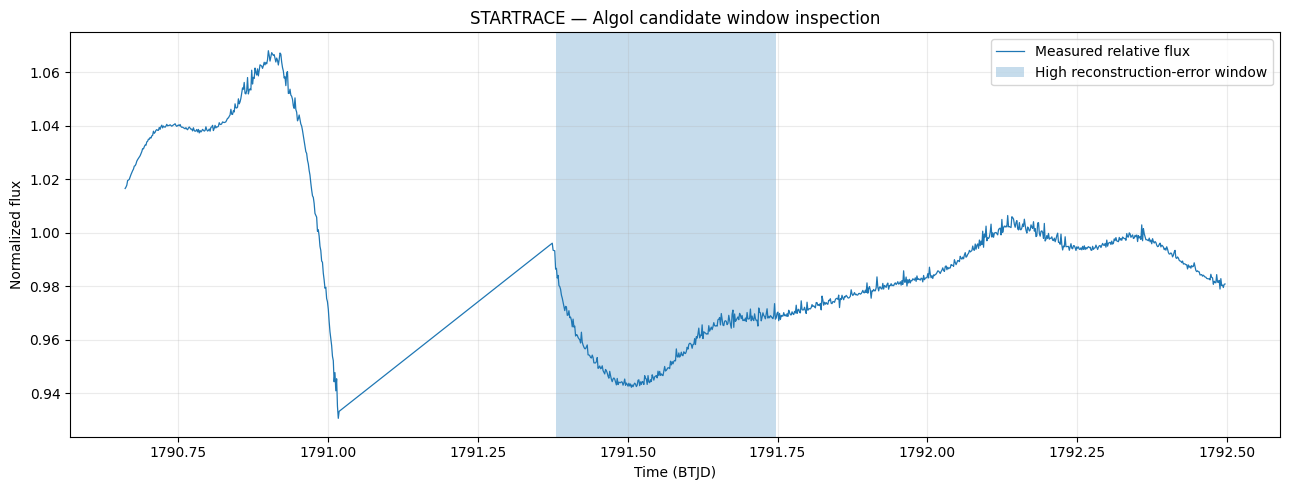

Candidate observations: 255
Flux range in candidate: 0.942247 to 0.984035
Median flux in candidate: 0.958275
Plot saved to: /content/STARTRACE/results/figures/algol_candidate_956_context.png


In [ ]:
ROOT = "/content/STARTRACE"
FIGURES = f"{ROOT}/results/figures"
os.makedirs(FIGURES, exist_ok=True)

algol = pd.read_csv(f"{ROOT}/data/processed/Algol_clean.csv")
time = pd.to_numeric(algol["time_btjd"], errors="coerce").to_numpy()
flux = pd.to_numeric(algol["normalized_flux"], errors="coerce").to_numpy()

valid = np.isfinite(time) & np.isfinite(flux)
time, flux = time[valid], flux[valid]

order = np.argsort(time)
time, flux = time[order], flux[order]

# Candidate interval from STARTRACE's window metadata
start_btjd = 1791.381216
end_btjd = 1791.747892

# Show context on both sides
padding = 0.75
mask = (
    (time >= start_btjd - padding) &
    (time <= end_btjd + padding)
)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(time[mask], flux[mask], linewidth=0.9, label="Measured relative flux")
ax.axvspan(
    start_btjd, end_btjd,
    alpha=0.25, label="High reconstruction-error window"
)
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalized flux")
ax.set_title("STARTRACE — Algol candidate window inspection")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

output = f"{FIGURES}/algol_candidate_956_context.png"
plt.savefig(output, dpi=160)
plt.show()

inside = (time >= start_btjd) & (time <= end_btjd)
print(f"Candidate observations: {inside.sum()}")
print(f"Flux range in candidate: {flux[inside].min():.6f} to {flux[inside].max():.6f}")
print(f"Median flux in candidate: {np.median(flux[inside]):.6f}")
print(f"Plot saved to: {output}")



STARTRACE — Algol candidate validation
------------------------------------------
Window ID: 956
Candidate interval: 1791.381216–1791.747892 BTJD
Points inside window: 256
Context observations: 709
Median context cadence: 2.00 minutes
Largest time gap: 512.01 minutes
Context flux minimum: 0.930650
Context flux median: 0.976612
Context flux maximum: 1.067964


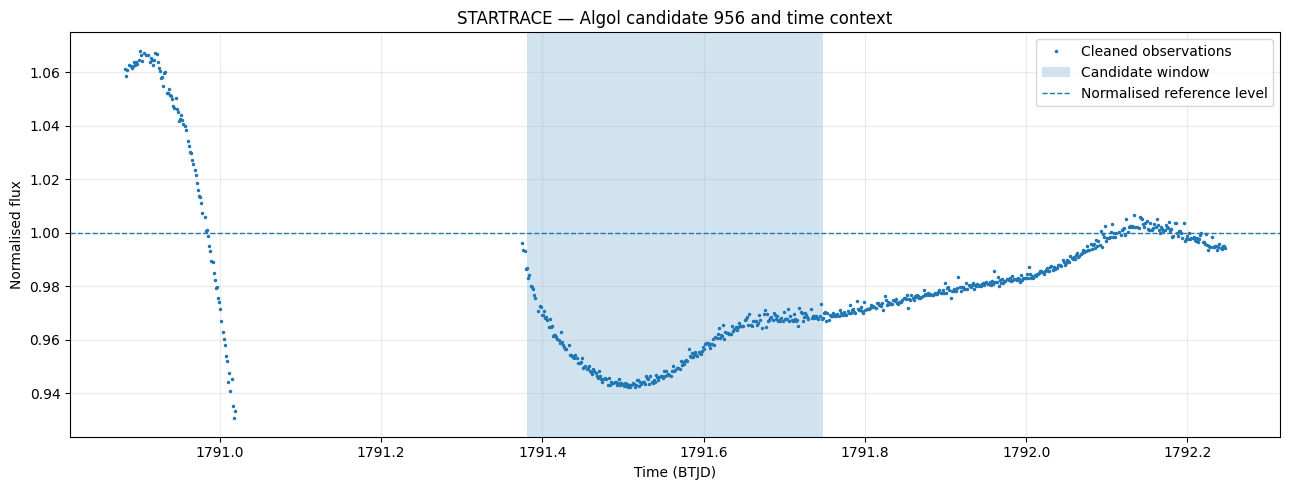


Saved plot: /content/STARTRACE/results/figures/algol_candidate_956_validation.png

Interpretation: inspect whether the flux reduction is coherent across time, whether the baseline recovers, and whether gaps or isolated measurements could explain it.


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Recover the exact window from the saved metadata.
metadata = pd.read_csv(PROCESSED / "window_metadata.csv")
candidate_id = 956

candidate = metadata.loc[
    metadata["window_id"] == candidate_id
]

if candidate.empty:
    raise ValueError(f"Window {candidate_id} not found.")

candidate = candidate.iloc[0]

if candidate["target"] != "Algol":
    raise ValueError(
        f"Expected Algol, found {candidate['target']}."
    )

df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df[["time_btjd", "normalized_flux"]].copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna()
df = df.sort_values("time_btjd").reset_index(drop=True)

start = float(candidate["start_btjd"])
end = float(candidate["end_btjd"])

# Show the candidate and its surrounding observations.
margin = 0.5
context = df[
    (df["time_btjd"] >= start - margin) &
    (df["time_btjd"] <= end + margin)
].copy()

inside = context[
    (context["time_btjd"] >= start) &
    (context["time_btjd"] <= end)
]

if context.empty:
    raise ValueError("No observations found near candidate.")

time = context["time_btjd"].to_numpy()
flux = context["normalized_flux"].to_numpy()

cadences = np.diff(time)
positive_cadences = cadences[cadences > 0]

print("STARTRACE — Algol candidate validation")
print("-" * 42)
print(f"Window ID: {candidate_id}")
print(f"Candidate interval: {start:.6f}–{end:.6f} BTJD")
print(f"Points inside window: {len(inside)}")
print(f"Context observations: {len(context)}")

if len(positive_cadences):
    typical_cadence = np.median(positive_cadences)
    print(f"Median context cadence: {typical_cadence * 1440:.2f} minutes")
    print(
        "Largest time gap: "
        f"{np.max(cadences) * 1440:.2f} minutes"
        if len(cadences) else "Largest time gap: unavailable"
    )

print(f"Context flux minimum: {flux.min():.6f}")
print(f"Context flux median: {np.median(flux):.6f}")
print(f"Context flux maximum: {flux.max():.6f}")

# Plot the actual cleaned measurements with the candidate highlighted.
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    context["time_btjd"],
    context["normalized_flux"],
    ".",
    markersize=3,
    label="Cleaned observations"
)

ax.axvspan(
    start, end,
    alpha=0.2,
    label="Candidate window"
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
    label="Normalised reference level"
)

ax.set_title("STARTRACE — Algol candidate 956 and time context")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

output_path = FIGURES / "algol_candidate_956_validation.png"
plt.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"\nSaved plot: {output_path}")
print(
    "\nInterpretation: inspect whether the flux reduction is "
    "coherent across time, whether the baseline recovers, and "
    "whether gaps or isolated measurements could explain it."
)



CANDIDATE ONLY
Observations: 255
Median cadence: 2.00 minutes
Large gaps: 0

SURROUNDING CONTEXT
Observations: 709
Median cadence: 2.00 minutes
Large gaps: 1
  1791.018706 to 1791.374271 BTJD — 512.01 minutes


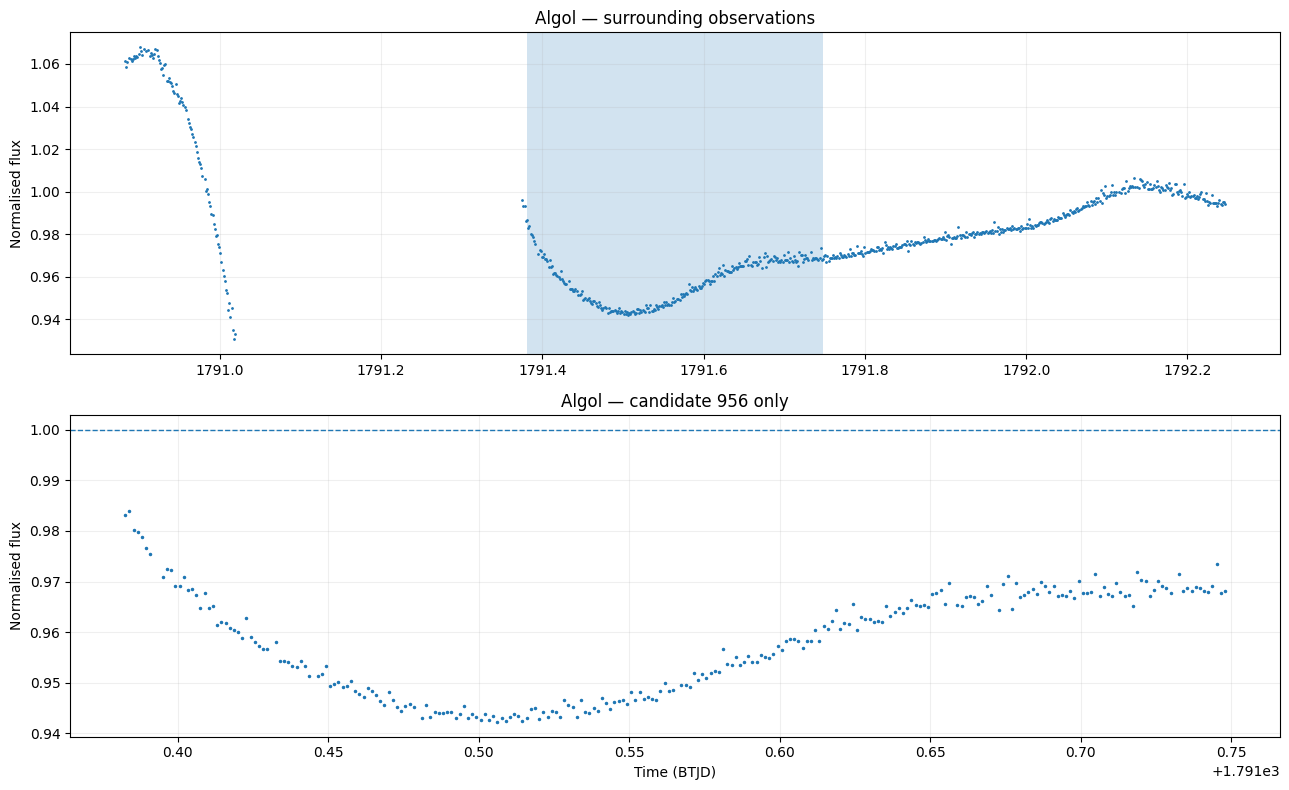


Saved: /content/STARTRACE/results/figures/algol_candidate_956_gap_audit.png


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"

df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_btjd", "normalized_flux"])
df = df.sort_values("time_btjd").reset_index(drop=True)

start, end = 1791.381216, 1791.747892

candidate = df[
    df["time_btjd"].between(start, end)
].copy()

context = df[
    df["time_btjd"].between(start - 0.5, end + 0.5)
].copy()

def report_gaps(data, label):
    t = data["time_btjd"].to_numpy()
    if len(t) < 2:
        print(f"{label}: insufficient observations")
        return

    dt = np.diff(t) * 1440
    positive = dt[dt > 0]
    cadence = np.median(positive) if len(positive) else np.nan
    gap_indices = np.flatnonzero(dt > 5 * cadence)

    print(f"\n{label}")
    print(f"Observations: {len(data)}")
    print(f"Median cadence: {cadence:.2f} minutes")
    print(f"Large gaps: {len(gap_indices)}")

    for i in gap_indices[:10]:
        print(
            f"  {t[i]:.6f} to {t[i+1]:.6f} BTJD"
            f" — {dt[i]:.2f} minutes"
        )

report_gaps(candidate, "CANDIDATE ONLY")
report_gaps(context, "SURROUNDING CONTEXT")

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(
    context["time_btjd"], context["normalized_flux"],
    ".", markersize=2
)
axes[0].axvspan(start, end, alpha=0.2)
axes[0].set_title("Algol — surrounding observations")
axes[0].set_ylabel("Normalised flux")
axes[0].grid(alpha=0.2)

axes[1].plot(
    candidate["time_btjd"], candidate["normalized_flux"],
    ".", markersize=3
)
axes[1].axhline(1.0, linestyle="--", linewidth=1)
axes[1].set_title("Algol — candidate 956 only")
axes[1].set_xlabel("Time (BTJD)")
axes[1].set_ylabel("Normalised flux")
axes[1].grid(alpha=0.2)

plt.tight_layout()
path = FIGURES / "algol_candidate_956_gap_audit.png"
plt.savefig(path, dpi=160, bbox_inches="tight")
plt.show()

print(f"\nSaved: {path}")


STARTRACE — Algol 956 morphology audit
Before candidate: n=5, median=0.993237, 10th percentile=0.986507, 90th percentile=0.995014
Candidate: n=255, median=0.958275, 10th percentile=0.944052, 90th percentile=0.969210
After candidate: n=107, median=0.973431, 10th percentile=0.969388, 90th percentile=0.977064

Candidate median relative to pre-window baseline: 3.520%
Before/after median difference: -0.019806


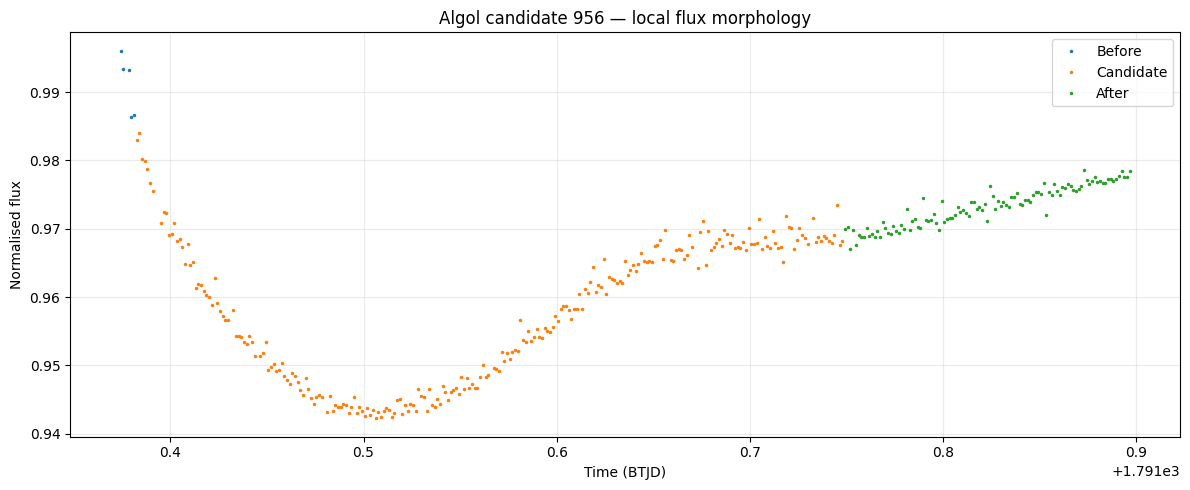

Saved: /content/STARTRACE/results/figures/algol_candidate_956_morphology.png


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"

df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_btjd", "normalized_flux"])
df = df.sort_values("time_btjd").reset_index(drop=True)

start, end = 1791.381216, 1791.747892

# Candidate plus nearby data, excluding the large preceding gap.
before = df[
    (df["time_btjd"] >= start - 0.15) &
    (df["time_btjd"] < start)
]
inside = df[df["time_btjd"].between(start, end)]
after = df[
    (df["time_btjd"] > end) &
    (df["time_btjd"] <= end + 0.15)
]

def summarize(name, data):
    if len(data) == 0:
        print(f"{name}: no observations")
        return np.nan

    flux = data["normalized_flux"].to_numpy()
    print(
        f"{name}: n={len(flux)}, "
        f"median={np.median(flux):.6f}, "
        f"10th percentile={np.percentile(flux, 10):.6f}, "
        f"90th percentile={np.percentile(flux, 90):.6f}"
    )
    return np.median(flux)

print("STARTRACE — Algol 956 morphology audit")
b = summarize("Before candidate", before)
c = summarize("Candidate", inside)
a = summarize("After candidate", after)

if np.isfinite(b) and np.isfinite(c) and b != 0:
    print(f"\nCandidate median relative to pre-window baseline: "
          f"{(b-c)/abs(b)*100:.3f}%")

if np.isfinite(b) and np.isfinite(a):
    print(f"Before/after median difference: {a-b:+.6f}")

fig, ax = plt.subplots(figsize=(12, 5))

for name, data in [
    ("Before", before),
    ("Candidate", inside),
    ("After", after)
]:
    if len(data):
        ax.plot(
            data["time_btjd"],
            data["normalized_flux"],
            ".",
            markersize=3,
            label=name
        )

ax.set_title("Algol candidate 956 — local flux morphology")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

path = FIGURES / "algol_candidate_956_morphology.png"
plt.savefig(path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Saved: {path}")


Algol full-curve audit
Total observations: 13247
Time span: 1790.6618 to 1814.2980 BTJD
Median cadence: 2.00 minutes
Observing segments: 15


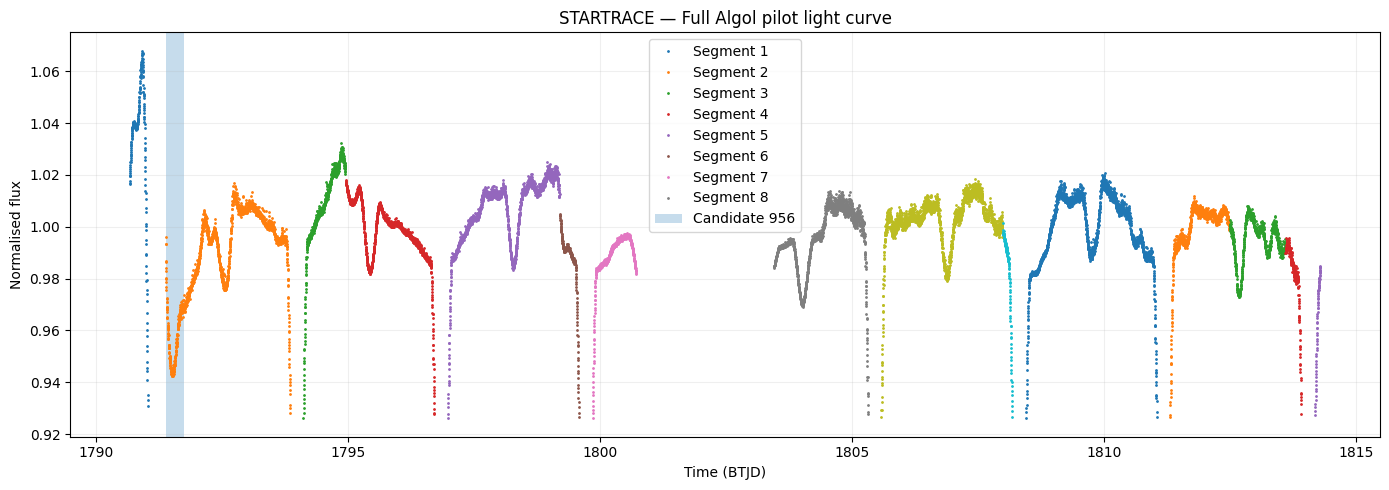

Saved: /content/STARTRACE/results/figures/algol_full_lightcurve_audit.png

Largest gaps:
1800.71329–1803.45359 BTJD: 3946.0 minutes
1791.01871–1791.37427 BTJD: 512.0 minutes
1808.17582–1808.45915 BTJD: 408.0 minutes
1813.91187–1814.19520 BTJD: 408.0 minutes
1799.57579–1799.85218 BTJD: 398.0 minutes


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "results" / "figures"

df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_btjd", "normalized_flux"])
df = df.sort_values("time_btjd").reset_index(drop=True)

t = df["time_btjd"].to_numpy()
f = df["normalized_flux"].to_numpy()

start, end = 1791.381216, 1791.747892

# Identify separate observing segments using cadence-scaled gaps.
dt = np.diff(t)
positive = dt[dt > 0]
cadence = np.median(positive)

breaks = np.flatnonzero(dt > 5 * cadence) + 1
segments = np.split(np.arange(len(t)), breaks)

print("Algol full-curve audit")
print(f"Total observations: {len(df)}")
print(f"Time span: {t.min():.4f} to {t.max():.4f} BTJD")
print(f"Median cadence: {cadence * 1440:.2f} minutes")
print(f"Observing segments: {len(segments)}")

fig, ax = plt.subplots(figsize=(14, 5))

for i, segment in enumerate(segments):
    if len(segment):
        ax.plot(
            t[segment], f[segment],
            ".", markersize=2,
            label=f"Segment {i+1}" if i < 8 else None
        )

ax.axvspan(start, end, alpha=0.25, label="Candidate 956")
ax.set_title("STARTRACE — Full Algol pilot light curve")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

path = FIGURES / "algol_full_lightcurve_audit.png"
plt.savefig(path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Saved: {path}")

# Report the largest gaps for context.
if len(dt):
    largest = np.argsort(dt)[-5:][::-1]
    print("\nLargest gaps:")
    for i in largest:
        print(
            f"{t[i]:.5f}–{t[i+1]:.5f} BTJD: "
            f"{dt[i]*1440:.1f} minutes"
        )


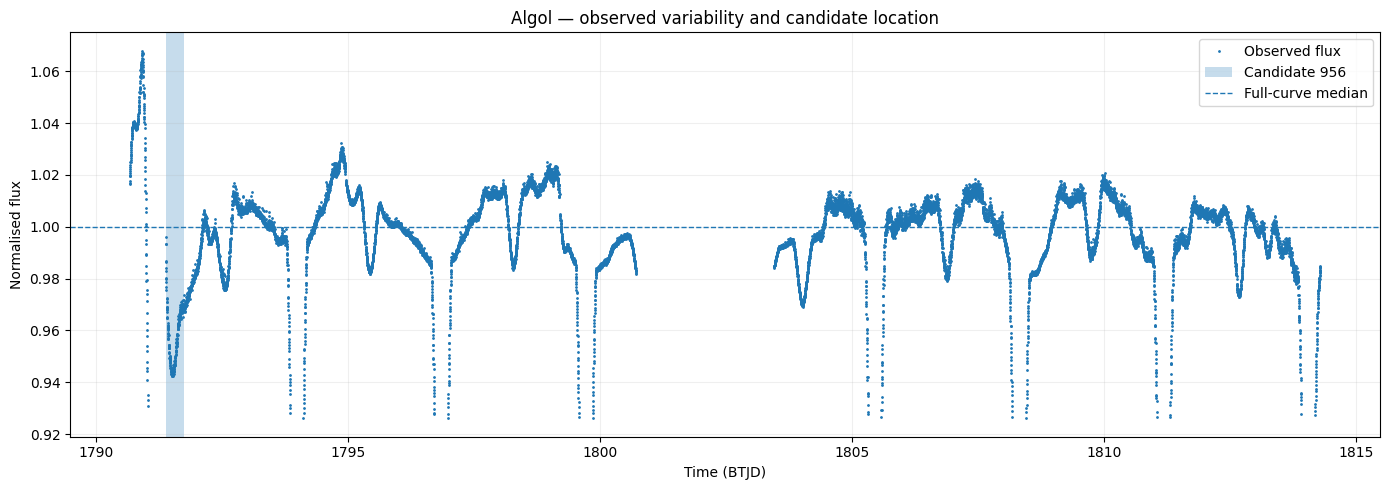

Full-curve flux percentiles:
 1th percentile: 0.942438
 5th percentile: 0.969850
10th percentile: 0.981008
25th percentile: 0.990833
50th percentile: 1.000000
75th percentile: 1.007426
90th percentile: 1.013729
95th percentile: 1.017562
99th percentile: 1.039204

Five lowest observed flux points:
BTJD 1796.982706 | flux 0.926054
BTJD 1799.852178 | flux 0.926098
BTJD 1808.459151 | flux 0.926143
BTJD 1794.110441 | flux 0.926298
BTJD 1811.316071 | flux 0.926467

Candidate centre: 1791.564554 BTJD
Saved plot: /content/STARTRACE/results/figures/algol_candidate_recurrence_context.png


In [ ]:
df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_btjd", "normalized_flux"])
df = df.sort_values("time_btjd").reset_index(drop=True)

t = df["time_btjd"].to_numpy()
f = df["normalized_flux"].to_numpy()

# Candidate interval identified in STARTRACE.
start, end = 1791.381216, 1791.747892
centre = (start + end) / 2

# Use the actual median cadence to define a conservative
# local running-median reference without bridging large gaps.
cadence = np.median(np.diff(t)[np.diff(t) > 0])
gap_after = np.r_[False, np.diff(t) > 5 * cadence]

# Plot the entire light curve with candidate location marked.
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(t, f, ".", markersize=2, label="Observed flux")
ax.axvspan(start, end, alpha=0.25, label="Candidate 956")
ax.axhline(np.median(f), linestyle="--",
           linewidth=1, label="Full-curve median")
ax.set_title("Algol — observed variability and candidate location")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalised flux")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

path = FIGURES / "algol_candidate_recurrence_context.png"
plt.savefig(path, dpi=160, bbox_inches="tight")
plt.show()

# Compare robust flux distributions across the full curve.
print("Full-curve flux percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p:>2}th percentile: {np.percentile(f, p):.6f}")

# Show the five deepest sampled observations and their timestamps.
deepest = np.argsort(f)[:5]
print("\nFive lowest observed flux points:")
for i in deepest:
    print(f"BTJD {t[i]:.6f} | flux {f[i]:.6f}")

print(f"\nCandidate centre: {centre:.6f} BTJD")
print(f"Saved plot: {path}")


Deepest continuous low-flux runs


,start_btjd,end_btjd,duration_min,n_points,median_flux,minimum_flux
0,1796.982706,1797.035485,76.000922,39,0.958325,0.926054
1,1799.852178,1799.910512,84.000582,43,0.960042,0.926098
2,1808.459151,1808.529984,101.999416,50,0.966070,0.926143
3,1794.110441,1794.157664,68.001219,35,0.955773,0.926298
4,1811.316071,1811.366070,71.999188,37,0.957746,0.926467
5,1799.521620,1799.575787,78.000584,40,0.959367,0.926572
6,1805.582769,1805.628603,66.000049,33,0.957979,0.926608
7,1808.123042,1808.175819,75.999619,39,0.958809,0.926609
8,1810.992463,1811.046630,77.999168,40,0.959546,0.926642
9,1814.195198,1814.279919,121.998080,62,0.965806,0.927225


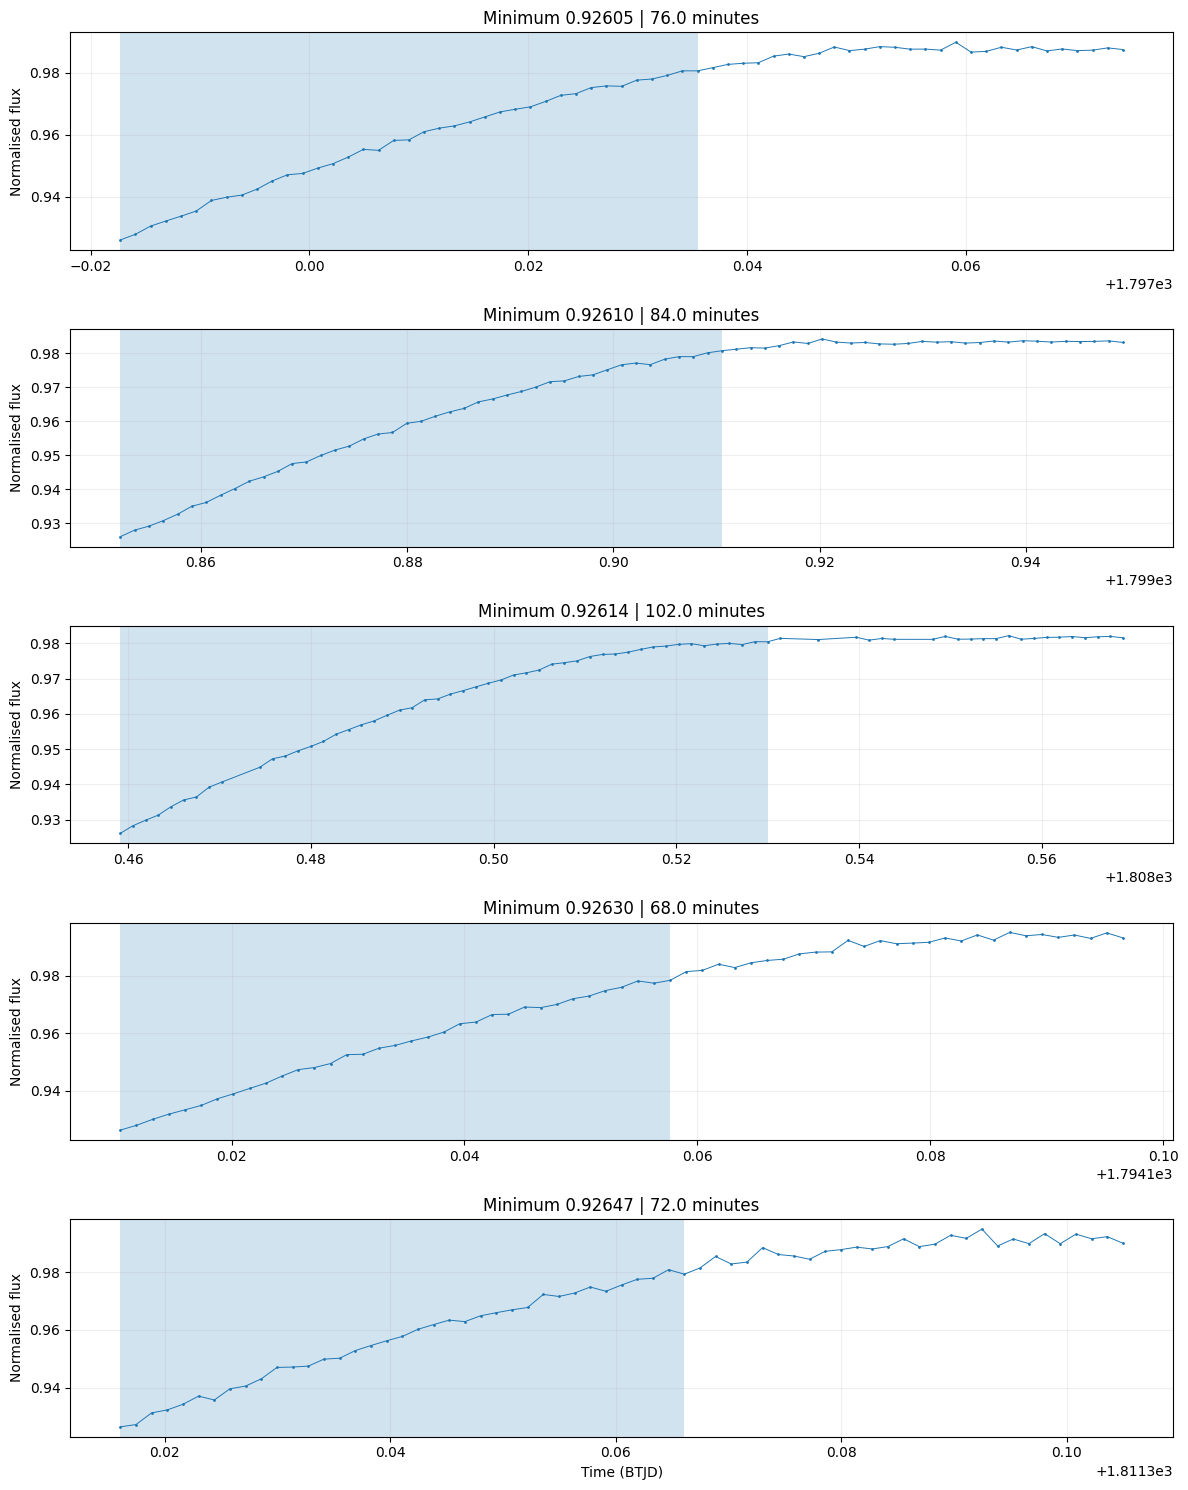

Saved: /content/STARTRACE/results/figures/algol_deep_dip_candidates.png

10th-percentile flux threshold: 0.981008
Low-flux runs are exploratory candidates, not confirmed eclipses.


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "Algol_clean.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_btjd", "normalized_flux"])
df = df.sort_values("time_btjd").reset_index(drop=True)

t = df["time_btjd"].to_numpy()
f = df["normalized_flux"].to_numpy()

# Split observations at large gaps.
dt = np.diff(t)
cadence = np.median(dt[dt > 0])
breaks = np.flatnonzero(dt > 5 * cadence) + 1
segments = np.split(np.arange(len(t)), breaks)

# Find low-flux runs within continuous segments.
# This is a candidate-finding heuristic, not an event classifier.
threshold = np.percentile(f, 10)
runs = []

for segment in segments:
    if len(segment) == 0:
        continue

    low = f[segment] < threshold
    positions = np.flatnonzero(low)

    if len(positions) == 0:
        continue

    groups = np.split(
        positions,
        np.flatnonzero(np.diff(positions) > 1) + 1
    )

    for group in groups:
        if len(group) < 3:
            continue

        idx = segment[group]
        runs.append({
            "start_btjd": t[idx[0]],
            "end_btjd": t[idx[-1]],
            "duration_min": (t[idx[-1]] - t[idx[0]]) * 1440,
            "n_points": len(idx),
            "median_flux": np.median(f[idx]),
            "minimum_flux": np.min(f[idx]),
        })

events = pd.DataFrame(runs)

if events.empty:
    print("No low-flux runs met the minimum duration criterion.")
else:
    events = events.sort_values("minimum_flux").reset_index(drop=True)
    print("Deepest continuous low-flux runs")
    display(events.head(15).round(6))

    # Plot the five deepest runs with local context.
    selected = events.head(5)
    fig, axes = plt.subplots(
        len(selected), 1,
        figsize=(12, 3 * len(selected)),
        squeeze=False
    )

    for ax, (_, event) in zip(axes.flat, selected.iterrows()):
        lo = event["start_btjd"] - 0.04
        hi = event["end_btjd"] + 0.04
        local = df[df["time_btjd"].between(lo, hi)]

        ax.plot(
            local["time_btjd"],
            local["normalized_flux"],
            ".-",
            markersize=2,
            linewidth=0.7
        )
        ax.axvspan(
            event["start_btjd"],
            event["end_btjd"],
            alpha=0.2
        )
        ax.set_title(
            f"Minimum {event['minimum_flux']:.5f} | "
            f"{event['duration_min']:.1f} minutes"
        )
        ax.set_ylabel("Normalised flux")
        ax.grid(alpha=0.2)

    axes[-1, 0].set_xlabel("Time (BTJD)")
    plt.tight_layout()

    path = FIGURES / "algol_deep_dip_candidates.png"
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")

print(f"\n10th-percentile flux threshold: {threshold:.6f}")
print("Low-flux runs are exploratory candidates, not confirmed eclipses.")


In [ ]:
# Sort candidate dips by their midpoint
events_check = events.copy()
events_check["mid_btjd"] = (
    events_check["start_btjd"] + events_check["end_btjd"]
) / 2

events_check = events_check.sort_values("mid_btjd").reset_index(drop=True)

# Calculate time between consecutive candidate midpoints
events_check["separation_hours"] = (
    events_check["mid_btjd"].diff() * 24
)

print("Candidate dips in chronological order:")
display(events_check[
    ["start_btjd", "end_btjd", "mid_btjd",
     "duration_min", "n_points", "median_flux",
     "minimum_flux", "separation_hours"]
].round(4))

print("\nCandidate midpoint separations (hours):")
print(events_check["separation_hours"].dropna().round(2).tolist())

Candidate dips in chronological order:


,start_btjd,end_btjd,mid_btjd,duration_min,n_points,median_flux,minimum_flux,separation_hours
0,1790.9951,1791.0187,1791.0069,34.0009,18,0.9559,0.9307,NaN
1,1791.3854,1791.8979,1791.6416,738.0180,361,0.9669,0.9422,15.2337
2,1791.9007,1791.9146,1791.9076,20.0005,11,0.9783,0.9755,6.3835
3,1791.9173,1791.9243,1791.9208,10.0002,6,0.9794,0.9783,0.3167
4,1791.9271,1791.9326,1791.9298,8.0002,5,0.9800,0.9789,0.2167
5,1791.9354,1791.9451,1791.9403,14.0003,8,0.9802,0.9789,0.2500
6,1792.4910,1792.4979,1792.4944,10.0002,6,0.9803,0.9790,13.3003
7,1792.5007,1792.5035,1792.5021,4.0001,3,0.9791,0.9786,0.1833
8,1792.5062,1792.5160,1792.5111,14.0003,8,0.9782,0.9773,0.2167
9,1792.5187,1792.5285,1792.5236,14.0003,8,0.9777,0.9765,0.3000



Candidate midpoint separations (hours):
[15.23, 6.38, 0.32, 0.22, 0.25, 13.3, 0.18, 0.22, 0.3, 0.25, 0.93, 29.98, 7.48, 61.12, 7.88, 60.95, 7.98, 99.2, 30.72, 7.47, 30.45, 0.77, 29.83, 8.28, 60.6, 7.72, 32.23, 27.05, 0.4, 0.38, 0.88, 8.57]


In [ ]:
root = Path("/content/STARTRACE")
files = list((root / "data" / "processed").glob("*.csv"))
print("Processed CSV files:", [f.name for f in files])

Processed CSV files: ['flux_diagnostics.csv', 'autoencoder_training_history.csv', 'HD_209458_clean.csv', 'RR_Lyr_clean.csv', 'TOI_700_clean.csv', 'pilot_summary.csv', 'Algol_clean.csv', 'window_metadata.csv']


In [ ]:
root = Path("/content/STARTRACE")
df = pd.read_csv(root / "data/processed/Algol_clean.csv")

print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['time_btjd', 'normalized_flux']


,time_btjd,normalized_flux
0,1790.661752,1.016506
1,1790.663141,1.017027
2,1790.664530,1.017747
3,1790.665919,1.019490
4,1790.667308,1.019660


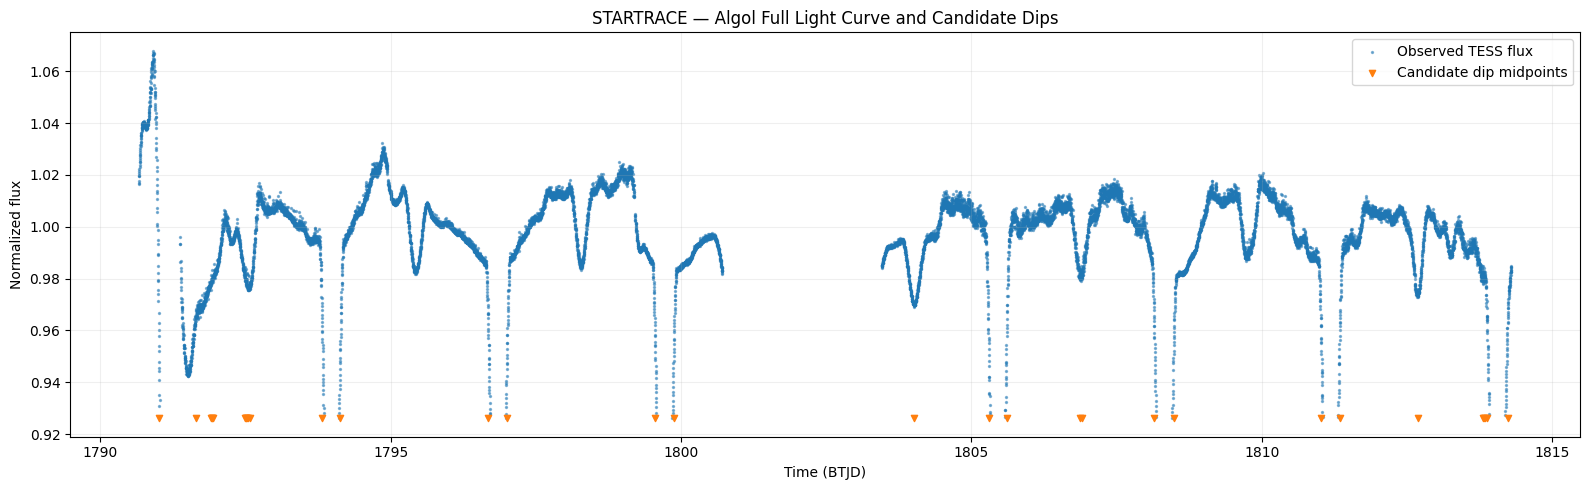

Saved: /content/STARTRACE/results/figures/algol_candidates_overview.png


In [ ]:
root = Path("/content/STARTRACE")
df = pd.read_csv(root / "data/processed/Algol_clean.csv")

# Use the candidate table created in the previous step
events_plot = events.copy()
events_plot["mid_btjd"] = (
    events_plot["start_btjd"] + events_plot["end_btjd"]
) / 2

fig, ax = plt.subplots(figsize=(16, 5))

ax.scatter(
    df["time_btjd"],
    df["normalized_flux"],
    s=2,
    alpha=0.5,
    label="Observed TESS flux"
)

ax.scatter(
    events_plot["mid_btjd"],
    [df["normalized_flux"].min()] * len(events_plot),
    s=20,
    marker="v",
    label="Candidate dip midpoints"
)

ax.set_title("STARTRACE — Algol Full Light Curve and Candidate Dips")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalized flux")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()

output = root / "results/figures/algol_candidates_overview.png"
output.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output, dpi=160)
plt.show()

print("Saved:", output)

In [ ]:
root = Path("/content/STARTRACE")
report_dir = root / "results"
report_dir.mkdir(parents=True, exist_ok=True)

audit_note = """
# STARTRACE — Algol Pilot Audit

## Data
- Target: Algol
- Source file: data/processed/Algol_clean.csv
- Columns: time_btjd, normalized_flux
- Observations: 13,247
- Time span: approximately BTJD 1790.66–1814.30
- Median cadence: approximately 2 minutes

## Quality checks
- Cadence gaps are present and must be respected.
- The light curve contains multiple low-flux intervals.
- Threshold-based candidates are exploratory, not confirmed eclipses.
- Candidate fragments may split one broad feature into multiple runs.
- No physical period or event classification has been established by this audit.

## Model limitations
- Autoencoder reconstruction error is not an event probability or confidence score.
- Randomly splitting overlapping windows can inflate validation performance.
- Generalization must be tested on targets excluded entirely from training.

## Next steps
1. Verify target metadata and event labels against independent catalogues.
2. Define reproducible event windows and negative examples.
3. Build a labelled dataset with target-level train/validation/test separation.
4. Compare simple baselines with a 1D CNN if the dataset supports it.
5. Report precision, recall, F1, PR-AUC, and held-out-target performance.
"""

path = report_dir / "algol_audit_notes.md"
path.write_text(audit_note.strip() + "\n", encoding="utf-8")

print("Saved audit notes:", path)
print("Next: verify target metadata and labels before training a classifier.")

Saved audit notes: /content/STARTRACE/results/algol_audit_notes.md
Next: verify target metadata and labels before training a classifier.


In [ ]:
root = Path("/content/STARTRACE")
summary = pd.read_csv(root / "data/processed/pilot_summary.csv")

display(summary)
print("Columns:", summary.columns.tolist())

,target,retained_observations,time_start_btjd,time_end_btjd,relative_flux_std,saved_to
0,HD_209458,110897,2825.262051,2853.143860,0.000654,/content/STARTRACE/data/processed/HD_209458_cl...
1,TOI_700,18279,1325.295495,1353.175974,0.001656,/content/STARTRACE/data/processed/TOI_700_clea...
2,Algol,13247,1790.661752,1814.297974,0.016182,/content/STARTRACE/data/processed/Algol_clean.csv
3,RR_Lyr,18292,1683.356471,1710.206415,2.125370,/content/STARTRACE/data/processed/RR_Lyr_clean...


Columns: ['target', 'retained_observations', 'time_start_btjd', 'time_end_btjd', 'relative_flux_std', 'saved_to']


Observations: 18292
Time span (BTJD): 1683.3565 to 1710.2064
Flux min: -2.8306270068184736
Flux 1st percentile: -1.919689580830333
Flux median: 1.0
Flux 99th percentile: 6.051814651654503
Flux max: 7.03465835582284
Flux standard deviation: 2.1253117705944438
Median cadence (minutes): 2.0


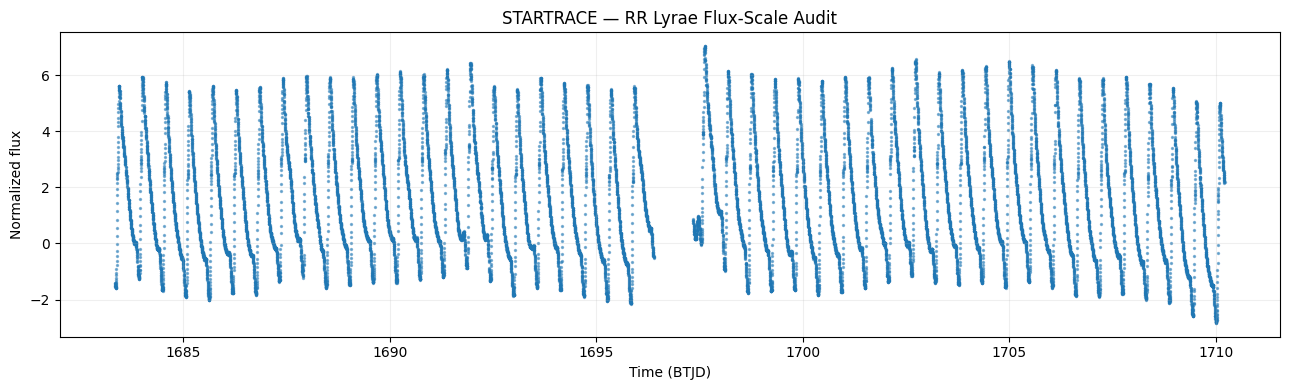

In [ ]:
path = Path("/content/STARTRACE/data/processed/RR_Lyr_clean.csv")
df = pd.read_csv(path)

t = df["time_btjd"].to_numpy()
f = df["normalized_flux"].to_numpy()

dt = np.diff(t)
positive_dt = dt[dt > 0]

print("Observations:", len(df))
print("Time span (BTJD):", round(t.min(), 4), "to", round(t.max(), 4))
print("Flux min:", np.nanmin(f))
print("Flux 1st percentile:", np.nanpercentile(f, 1))
print("Flux median:", np.nanmedian(f))
print("Flux 99th percentile:", np.nanpercentile(f, 99))
print("Flux max:", np.nanmax(f))
print("Flux standard deviation:", np.nanstd(f))
print("Median cadence (minutes):",
      round(np.median(positive_dt) * 1440, 3))

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 4))
plt.scatter(t, f, s=2, alpha=0.5)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized flux")
plt.title("STARTRACE — RR Lyrae Flux-Scale Audit")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

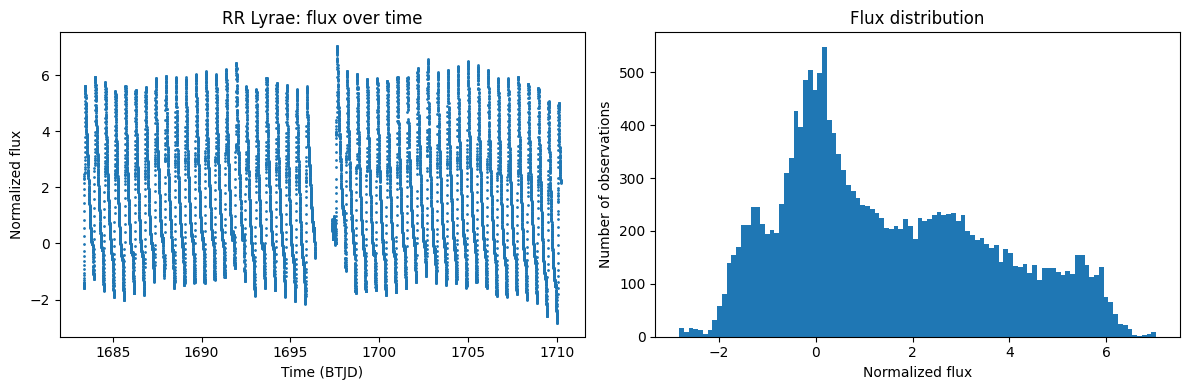

Non-finite values: 0
Negative values: 5441
Values outside 0.5–1.5: 15687


In [ ]:
root = Path("/content/STARTRACE")
df = pd.read_csv(root / "data/processed/RR_Lyr_clean.csv")
f = df["normalized_flux"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df["time_btjd"], f, ".", markersize=2)
axes[0].set_title("RR Lyrae: flux over time")
axes[0].set_xlabel("Time (BTJD)")
axes[0].set_ylabel("Normalized flux")

axes[1].hist(f[np.isfinite(f)], bins=100)
axes[1].set_title("Flux distribution")
axes[1].set_xlabel("Normalized flux")
axes[1].set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

print("Non-finite values:", np.sum(~np.isfinite(f)))
print("Negative values:", np.sum(f < 0))
print("Values outside 0.5–1.5:", np.sum((f < 0.5) | (f > 1.5)))

In [ ]:
root = Path("/content/STARTRACE")
for p in (root / "data/raw").rglob("*RR*"):
    if p.is_file():
        print(p)

/content/STARTRACE/data/raw/RR_Lyr_pilot.fits


In [ ]:
from astropy.io import fits

path = "/content/STARTRACE/data/raw/RR_Lyr_pilot.fits"

with fits.open(path) as hdul:
    hdul.info()

    for i, hdu in enumerate(hdul):
        if hasattr(hdu, "columns") and hdu.columns:
            print(f"\nHDU {i} columns:")
            print(hdu.columns.names)

Filename: /content/STARTRACE/data/raw/RR_Lyr_pilot.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      25   ()      
  1  LIGHTCURVE    1 BinTableHDU     28   18292R x 7C   [D, E, E, J, J, D, D]   

HDU 1 columns:
['TIME', 'FLUX', 'FLUX_ERR', 'CADENCENO', 'QUALITY', 'MOM_CENTR1', 'MOM_CENTR2']


In [ ]:
fits_path = "/content/STARTRACE/data/raw/RR_Lyr_pilot.fits"
csv_path = "/content/STARTRACE/data/processed/RR_Lyr_clean.csv"

with fits.open(fits_path) as hdul:
    raw = hdul["LIGHTCURVE"].data
    hdr = hdul["LIGHTCURVE"].header

    raw_time = np.asarray(raw["TIME"], dtype=float)
    raw_flux = np.asarray(raw["FLUX"], dtype=float)
    quality = np.asarray(raw["QUALITY"])

processed = pd.read_csv(csv_path)

print("FITS flux statistics:")
print("min:", np.nanmin(raw_flux))
print("median:", np.nanmedian(raw_flux))
print("max:", np.nanmax(raw_flux))
print("std:", np.nanstd(raw_flux))

print("\nProcessed flux statistics:")
print(processed["normalized_flux"].describe())

print("\nTime comparison:")
print("Raw TIME:", raw_time[:5])
print("Processed time:", processed["time_btjd"].head().to_list())

print("\nQuality flags:")
print("Unique values:", np.unique(quality)[:20])
print("Nonzero quality count:", np.count_nonzero(quality))

FITS flux statistics:
min: -38778.98046875
median: 13699.78466796875
max: 96373.3046875
std: 29116.31360944328

Processed flux statistics:
count    18292.000000
mean         1.472447
std          2.125370
min         -2.830627
25%         -0.178845
50%          1.000000
75%          3.035036
max          7.034658
Name: normalized_flux, dtype: float64

Time comparison:
Raw TIME: [1683.35647052 1683.35785941 1683.35924831 1683.36063721 1683.3620261 ]
Processed time: [1683.3564705189142, 1683.3578594148944, 1683.3592483106422, 1683.360637206622, 1683.3620261023686]

Quality flags:
Unique values: [0]
Nonzero quality count: 0


In [ ]:
fits_path = "/content/STARTRACE/data/raw/RR_Lyr_pilot.fits"
csv_path = "/content/STARTRACE/data/processed/RR_Lyr_clean.csv"

with fits.open(fits_path) as hdul:
    raw_flux = np.asarray(hdul["LIGHTCURVE"].data["FLUX"], dtype=float)

processed = pd.read_csv(csv_path)["normalized_flux"].to_numpy()

# Compare raw flux with processed flux
raw_median = np.nanmedian(raw_flux)
raw_mean = np.nanmean(raw_flux)

print("Raw median:", raw_median)
print("Raw mean:", raw_mean)
print("Median-normalized raw flux range:",
      np.nanmin(raw_flux / raw_median),
      np.nanmax(raw_flux / raw_median))
print("Correlation (raw vs processed):",
      np.corrcoef(raw_flux, processed)[0, 1])

# Fit a linear relationship: processed ≈ a * raw + b
a, b = np.polyfit(raw_flux, processed, 1)
predicted = a * raw_flux + b

print("Linear fit slope:", a)
print("Linear fit intercept:", b)
print("Linear fit correlation:", np.corrcoef(predicted, processed)[0, 1])
print("First 10 raw fluxes:", np.round(raw_flux[:10], 2))
print("First 10 processed fluxes:", np.round(processed[:10], 4))

Raw median: 13699.78466796875
Raw mean: 20172.205380205876
Median-normalized raw flux range: -2.8306270068184736 7.03465835582284
Correlation (raw vs processed): 1.0
Linear fit slope: 7.299384802288786e-05
Linear fit intercept: -9.750566468637601e-17
Linear fit correlation: 1.0
First 10 raw fluxes: [-19165.5  -19523.28 -19876.45 -20180.45 -20730.24 -20872.82 -21412.98
 -21216.91 -21698.22 -21724.39]
First 10 processed fluxes: [-1.399  -1.4251 -1.4509 -1.473  -1.5132 -1.5236 -1.563  -1.5487 -1.5838
 -1.5857]


In [ ]:
path = "/content/STARTRACE/data/raw/RR_Lyr_pilot.fits"

with fits.open(path) as hdul:
    print("PRIMARY HEADER")
    print(repr(hdul[0].header))

    print("\nLIGHTCURVE HEADER")
    for key, value in hdul["LIGHTCURVE"].header.items():
        if key.startswith(("T", "F", "P", "SAP", "PDCSAP", "BJD", "ORIGIN", "MISSION")):
            print(f"{key}: {value}")

PRIMARY HEADER
SIMPLE  =                    T / conforms to FITS standards                     
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T / file contains extensions                       
NEXTEND =                    2 / number of standard extensions                  
EXTNAME = 'PRIMARY '           / name of extension                              
EXTVER  =                    1 / extension version number (not format version)  
ORIGIN  = 'Unofficial data product' / institution responsible for file          
DATE    = '2026-10-12'         / file creation date.                            
CREATOR = 'lightkurve.LightCurve.to_fits()' / pipeline job and program used t   
TELESCOP= 'TESS    '           / telescope                                      
INSTRUME=  / detector type                                                      
OBJECT  = '15

Flux percentiles:
  0%: -38778.98
  1%: -26299.33
 10%: -14518.94
 25%: -2450.14
 50%: 13699.78
 75%: 41579.35
 90%: 65015.49
 99%: 82908.56
100%: 96373.30

Additional FITS metadata:
AUTHOR: Not recorded
DATA_REL: Not recorded
CREATOR: lightkurve.LightCurve.to_fits()
OBJECT: 159717514
SECTOR: 14


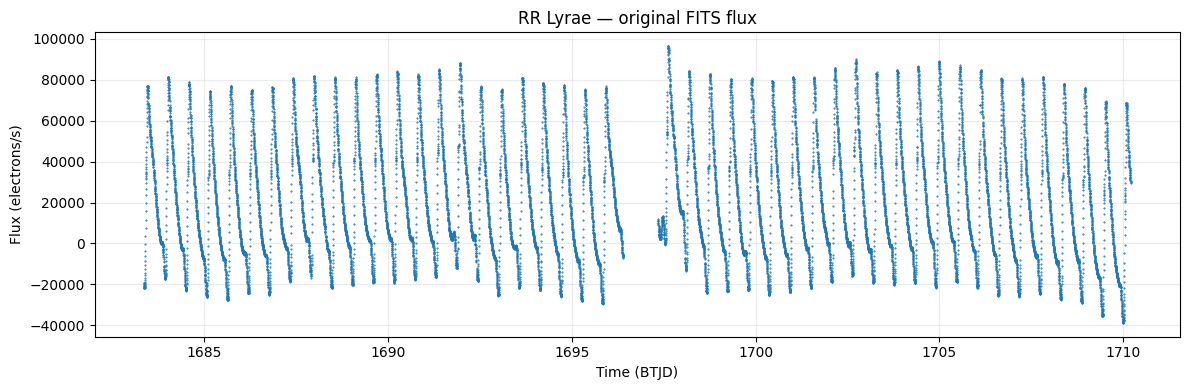

In [ ]:
path = "/content/STARTRACE/data/raw/RR_Lyr_pilot.fits"

with fits.open(path) as hdul:
    lc = hdul["LIGHTCURVE"].data
    flux = np.asarray(lc["FLUX"], dtype=float)
    time = np.asarray(lc["TIME"], dtype=float)

    print("Flux percentiles:")
    for p in [0, 1, 10, 25, 50, 75, 90, 99, 100]:
        print(f"{p:>3}%: {np.nanpercentile(flux, p):.2f}")

    print("\nAdditional FITS metadata:")
    for key in ["AUTHOR", "DATA_REL", "CREATOR", "OBJECT", "SECTOR"]:
        print(f"{key}: {hdul[0].header.get(key, 'Not recorded')}")

plt.figure(figsize=(12, 4))
plt.plot(time, flux, ".", markersize=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("Flux (electrons/s)")
plt.title("RR Lyrae — original FITS flux")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
search = lk.search_lightcurve(
    "TIC 159717514",
    mission="TESS"
)

print(search)

SearchResult containing 6 data products.

 #     mission     year   author  exptime target_name distance
                                     s                 arcsec 
--- -------------- ---- --------- ------- ----------- --------
  0 TESS Sector 14 2019      SPOC     120   159717514      0.0
  1 TESS Sector 40 2021      SPOC     120   159717514      0.0
  2 TESS Sector 41 2021      SPOC     120   159717514      0.0
  3 TESS Sector 14 2019 TESS-SPOC    1800   159717514      0.0
  4 TESS Sector 40 2021 TESS-SPOC     600   159717514      0.0
  5 TESS Sector 41 2021 TESS-SPOC     600   159717514      0.0


In [ ]:
raw_dir = Path("/content/STARTRACE/data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

search = lk.search_lightcurve(
    "TIC 159717514",
    mission="TESS",
    author="SPOC",
    sector=14,
    exptime=120
)

print(search)

SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 14 2019   SPOC     120   159717514      0.0


In [ ]:
lc = search[0].download(download_dir=str(raw_dir))

print(lc)
print("Available columns:", lc.colnames)

       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1683.3564705189142 -1.9165498e+04 ... -1.4404563e-02 -4.4739880e-02
1683.3578594148944 -1.9523283e+04 ... -1.2542778e-02 -4.5301165e-02
1683.3592483106422 -1.9876449e+04 ... -1.5601475e-02 -4.6375167e-02
 1683.360637206622 -2.0180451e+04 ... -1.7346617e-02 -4.9082343e-02
1683.3620261023686 -2.0730244e+04 ... -1.7294420e-02 -4.0988762e-02
 1683.363414998349 -2.0872824e+04 ... -1.4637413e-02 -4.1157205e-02
1683.3648038940964 -2.1412977e+04 ... -1.7352317e-02 -4.8050787e-02
 1683.366192790077 -2.1216912e+04 ... -1.7503725e-02 -4.4119917e-02
1683.3675816858245 -2.1698219e+04 ... -1.9883772e-02 -3.9234996e-02
               ...            ... ...            ...            ...
 1710.193914963473  3.2604619e+04 ... -2.0995192e-02 -4.0476587e-02
  1710.19530384362  3.2223352e+04 ... -2.1605192

In [ ]:
root = Path("/content/STARTRACE")

for name in [
    "data/processed/X_windows.npy",
    "data/processed/window_metadata.csv",
    "startrace_autoencoder.keras",
    "data/processed/pilot_summary.csv",
    "results/algol_audit_notes.md",
]:
    p = root / name
    print(("EXISTS " if p.exists() else "MISSING"), p)

EXISTS  /content/STARTRACE/data/processed/X_windows.npy
EXISTS  /content/STARTRACE/data/processed/window_metadata.csv
EXISTS  /content/STARTRACE/startrace_autoencoder.keras
EXISTS  /content/STARTRACE/data/processed/pilot_summary.csv
EXISTS  /content/STARTRACE/results/algol_audit_notes.md


In [ ]:
ROOT = Path("/content/STARTRACE")
PROCESSED = ROOT / "data/processed"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

X = np.load(PROCESSED / "X_windows.npy")
meta = pd.read_csv(PROCESSED / "window_metadata.csv")
summary = pd.read_csv(PROCESSED / "pilot_summary.csv")

print("=== STARTRACE DATASET AUDIT ===")
print("Window array shape:", X.shape)
print("Metadata shape:", meta.shape)
print("Summary shape:", summary.shape)

print("\nWindow metadata columns:")
print(meta.columns.tolist())

print("\nTargets represented:")
target_col = next(
    (c for c in meta.columns if c.lower() in
     ["target", "target_name", "star", "object", "object_name"]),
    None
)

if target_col:
    print(meta[target_col].value_counts(dropna=False))
else:
    print("Target column not automatically identified.")
    print(meta.head())

print("\nPilot summary:")
print(summary.to_string(index=False))

print("\n=== BASIC DATA VALIDITY ===")
print("Array dtype:", X.dtype)
print("Finite values:", np.isfinite(X).all())
print("NaN count:", int(np.isnan(X).sum()))
print("Infinite count:", int(np.isinf(X).sum()))
print("Metadata missing cells:", int(meta.isna().sum().sum()))

audit = {
    "window_count": len(X),
    "window_shape": str(X.shape),
    "metadata_rows": len(meta),
    "metadata_missing_cells": int(meta.isna().sum().sum()),
    "all_window_values_finite": bool(np.isfinite(X).all()),
    "target_column_detected": target_col or "NOT_IDENTIFIED",
}

pd.Series(audit, name="value").to_csv(
    RESULTS / "objective1_dataset_audit.csv"
)

print("\nAudit saved to:", RESULTS / "objective1_dataset_audit.csv")

=== STARTRACE DATASET AUDIT ===
Window array shape: (1158, 256)
Metadata shape: (1158, 4)
Summary shape: (4, 6)

Window metadata columns:
['window_id', 'target', 'start_btjd', 'end_btjd']

Targets represented:
target
HD_209458    843
RR_Lyr       127
TOI_700      113
Algol         75
Name: count, dtype: int64

Pilot summary:
   target  retained_observations  time_start_btjd  time_end_btjd  relative_flux_std                                              saved_to
HD_209458                 110897      2825.262051    2853.143860           0.000654 /content/STARTRACE/data/processed/HD_209458_clean.csv
  TOI_700                  18279      1325.295495    1353.175974           0.001656   /content/STARTRACE/data/processed/TOI_700_clean.csv
    Algol                  13247      1790.661752    1814.297974           0.016182     /content/STARTRACE/data/processed/Algol_clean.csv
   RR_Lyr                  18292      1683.356471    1710.206415           2.125370    /content/STARTRACE/data/processed/

In [ ]:
ROOT = Path("/content/STARTRACE")
P = ROOT / "data/processed"
R = ROOT / "results"

rows = []

for target in ["HD_209458", "TOI_700", "Algol", "RR_Lyr"]:
    path = P / f"{target}_clean.csv"
    df = pd.read_csv(path)

    t = df["time_btjd"].to_numpy(float)
    f = df["normalized_flux"].to_numpy(float)
    dt = np.diff(t)
    cadence = np.nanmedian(dt) * 1440 if len(dt) else np.nan

    rows.append({
        "target": target,
        "observations": len(df),
        "finite": bool(np.isfinite(t).all() and np.isfinite(f).all()),
        "duplicate_times": int(pd.Series(t).duplicated().sum()),
        "median_cadence_min": cadence,
        "gaps_over_10min": int((dt > 10/1440).sum()),
        "flux_min": np.nanmin(f),
        "flux_median": np.nanmedian(f),
        "flux_max": np.nanmax(f),
        "flux_std": np.nanstd(f),
        "catalogue_label_verified": False
    })

quality = pd.DataFrame(rows)
quality.to_csv(R / "objective1_quality_report.csv", index=False)

print(quality.to_string(index=False))
print("\nSaved:", R / "objective1_quality_report.csv")
print("\nObjective 1 status: DATA AUDIT DONE; independent catalogue labels still unverified.")

   target  observations  finite  duplicate_times  median_cadence_min  gaps_over_10min  flux_min  flux_median  flux_max  flux_std  catalogue_label_verified
HD_209458        110897    True                0            0.333328               11  0.996688          1.0  1.003259  0.000654                     False
  TOI_700         18279    True                0            1.999996               44  0.993850          1.0  1.006604  0.001656                     False
    Algol         13247    True                0            2.000012               14  0.926054          1.0  1.067964  0.016181                     False
   RR_Lyr         18292    True                0            2.000005                7 -2.830627          1.0  7.034658  2.125312                     False

Saved: /content/STARTRACE/results/objective1_quality_report.csv

Objective 1 status: DATA AUDIT DONE; independent catalogue labels still unverified.


In [ ]:
ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras",
    compile=False
)

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

# Match the model's expected input dimensions
if len(model.input_shape) == 3 and X.ndim == 2:
    X_model = X[..., np.newaxis]
else:
    X_model = X

reconstruction = model.predict(X_model, verbose=0)
errors = np.mean(
    np.abs(X_model - reconstruction),
    axis=tuple(range(1, X_model.ndim))
)

results = meta.copy()
results["reconstruction_mae"] = errors

report = results.groupby("target").agg(
    windows=("window_id", "count"),
    mean_mae=("reconstruction_mae", "mean"),
    median_mae=("reconstruction_mae", "median"),
    p95_mae=("reconstruction_mae", lambda s: s.quantile(0.95))
).reset_index()

report.to_csv(
    ROOT / "results/model_reconstruction_evaluation.csv",
    index=False
)

print("\n=== RECONSTRUCTION EVALUATION ===")
print(report.to_string(index=False))
print("\nSaved: results/model_reconstruction_evaluation.csv")
print("Note: reconstruction MAE is not a class probability or a confirmed event detector.")

Model input: (None, 256, 1)
Model output: (None, 256, 1)

=== RECONSTRUCTION EVALUATION ===
   target  windows  mean_mae  median_mae  p95_mae
    Algol       75  0.140012    0.108399 0.273749
HD_209458      843  0.574601    0.571251 0.634613
   RR_Lyr      127  0.105099    0.106303 0.129841
  TOI_700      113  0.668183    0.669626 0.720880

Saved: results/model_reconstruction_evaluation.csv
Note: reconstruction MAE is not a class probability or a confirmed event detector.


In [ ]:
ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")

print("=== INPUT DISTRIBUTIONS ===")
for target in sorted(meta["target"].unique()):
    x = X[meta["target"].to_numpy() == target]
    print(
        f"{target:12s} | "
        f"min={x.min():.4f} | max={x.max():.4f} | "
        f"mean={x.mean():.4f} | std={x.std():.4f}"
    )

print("\nExisting scaler files:")
for p in ROOT.rglob("*"):
    if p.is_file() and any(
        word in p.name.lower()
        for word in ["scaler", "normalizer", "preprocess"]
    ):
        print(p)

=== INPUT DISTRIBUTIONS ===
Algol        | min=-4.7370 | max=2.6581 | mean=0.0048 | std=0.9724
HD_209458    | min=-4.3149 | max=5.1602 | mean=0.0142 | std=1.0226
RR_Lyr       | min=-1.7469 | max=2.7520 | mean=0.2086 | std=0.9699
TOI_700      | min=-3.6785 | max=3.9498 | mean=-0.0025 | std=0.9913

Existing scaler files:


In [ ]:
ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras", compile=False
)

rng = np.random.default_rng(42)
rows = []

for target in sorted(meta["target"].unique()):
    mask = meta["target"].to_numpy() == target
    x = X[mask].astype("float32")

    # The model expects (batch, time, channel)
    x3 = x[..., None]
    baseline = np.mean(
        np.abs(x3 - model.predict(x3, verbose=0)), axis=(1, 2)
    )

    rows.append({
        "target": target,
        "condition": "original",
        "windows": len(x),
        "mean_reconstruction_mae": float(baseline.mean())
    })

    if target == "RR_Lyr":
        noisy = x + rng.normal(0, 0.1, size=x.shape).astype("float32")
        noisy3 = noisy[..., None]
        noisy_err = np.mean(
            np.abs(noisy3 - model.predict(noisy3, verbose=0)),
            axis=(1, 2)
        )
        rows.append({
            "target": target,
            "condition": "added_noise_sd_0.1",
            "windows": len(x),
            "mean_reconstruction_mae": float(noisy_err.mean())
        })

        masked = x.copy()
        masked[:, ::5] = 0.0  # simulated missing points, zero-filled
        masked3 = masked[..., None]
        masked_err = np.mean(
            np.abs(masked3 - model.predict(masked3, verbose=0)),
            axis=(1, 2)
        )
        rows.append({
            "target": target,
            "condition": "simulated_missing_20pct",
            "windows": len(x),
            "mean_reconstruction_mae": float(masked_err.mean())
        })

report = pd.DataFrame(rows)
out = ROOT / "results/generalization_robustness_report.csv"
report.to_csv(out, index=False)

print(report.to_string(index=False))
print("\nSaved:", out)
print("Caution: zero-filling is a simple stress test, not realistic gap reconstruction.")

   target               condition  windows  mean_reconstruction_mae
    Algol                original       75                 0.140012
HD_209458                original      843                 0.574601
   RR_Lyr                original      127                 0.105099
   RR_Lyr      added_noise_sd_0.1      127                 0.125147
   RR_Lyr simulated_missing_20pct      127                 0.254594
  TOI_700                original      113                 0.668183

Saved: /content/STARTRACE/results/generalization_robustness_report.csv
Caution: zero-filling is a simple stress test, not realistic gap reconstruction.


In [ ]:
from datetime import date

ROOT = Path("/content/STARTRACE")
RESULTS = ROOT / "results"

quality = pd.read_csv(RESULTS / "objective1_quality_report.csv")
recon = pd.read_csv(RESULTS / "model_reconstruction_evaluation.csv")
robust = pd.read_csv(RESULTS / "generalization_robustness_report.csv")

def md_table(df):
    return df.to_markdown(index=False)

report = f"""# STARTRACE — Research Progress Report

**Generated:** {date.today().isoformat()}

## Abstract

STARTRACE is a prototype for investigating machine-learning methods
that learn patterns in stellar light curves. This pilot uses four TESS
targets and a convolutional autoencoder to study reconstruction behavior,
unseen-target transfer, and sensitivity to synthetic data corruption.

The results are exploratory. Independent catalogue labels have not yet
been verified, so the study does not establish supervised classification
accuracy or confirm astronomical events.

## 1. Dataset and quality audit

The pilot contains 1,158 windows of 256 samples across four targets.
The window array contains finite values and the window metadata has no
missing cells.

{md_table(quality)}

**Data limitations:** Catalogue labels and event timings remain
unverified. The RR Lyrae processed series showed an unusually broad
normalized-flux range. Although an official SPOC product was retrieved,
the existing window array and saved evaluation were not regenerated
from the corrected product.

## 2. Reconstruction evaluation

{md_table(recon)}

Reconstruction MAE measures the difference between model inputs and
reconstructions. It is not a class probability, calibrated confidence,
or proof of an astronomical event. Target-level differences may reflect
morphology and data-processing differences.

## 3. Held-out target and robustness experiment

{md_table(robust)}

RR Lyrae was excluded from the autoencoder's training targets, making
this an exploratory held-out-target test. However, its evaluated windows
were generated before the later PDCSAP correction. The robustness tests
use synthetic Gaussian noise and zero-filled missing samples; they do
not represent every real observation condition.

## 4. Objective status

| Objective | Status | Remaining work |
|---|---|---|
| 1. Real dataset | Partial | Verify catalogue associations and labels; regenerate RR Lyrae windows |
| 2. Astrophysical patterns | Partial | Systematic morphology analysis with verified references |
| 3. Model comparison | Partial | Baselines; supervised CNN only if labels support it |
| 4. Unseen-star generalization | Preliminary | Repeat after data correction; evaluate more independent targets |
| 5. Robustness and limitations | Preliminary | Broader corruption tests, error analysis, uncertainty evaluation |
| 6. Reproducible artifact | Partial | End-to-end reproducibility, final figures, report, deployment checks |

## 5. Scientific limitations

- Four targets are insufficient to support broad claims about generalization.
- Overlapping windows are not independent observations.
- Catalogue-derived labels and event timings have not been independently verified.
- No precision, recall, F1-score, or PR-AUC is reported because a verified
  supervised classification evaluation is not yet available.
- Predictions and reconstruction errors must not be described as confirmed
  discoveries.

## 6. Reproducibility artifacts

- `data/processed/X_windows.npy`
- `data/processed/window_metadata.csv`
- `data/processed/pilot_summary.csv`
- `startrace_autoencoder.keras`
- `results/objective1_quality_report.csv`
- `results/model_reconstruction_evaluation.csv`
- `results/generalization_robustness_report.csv`

## Conclusion

STARTRACE has a functioning exploratory autoencoder pipeline and initial
robustness experiments. The next scientific priority is to establish
trustworthy labels and a consistent dataset before attempting supervised
classification. The present results are preliminary and should not be
interpreted as validated astronomical event detection.
"""

path = RESULTS / "STARTRACE_research_report.md"
path.write_text(report, encoding="utf-8")

print("Research report saved:", path)
print("Report characters:", len(report))
print("\nObjective status recorded without overstating completion.")

Research report saved: /content/STARTRACE/results/STARTRACE_research_report.md
Report characters: 5740

Objective status recorded without overstating completion.


In [ ]:
ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy").astype(np.float32)
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")

model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras",
    compile=False
)

# Reconstruct all existing windows
X3 = X[..., np.newaxis]
pred = model.predict(X3, batch_size=64, verbose=0)
pred = pred[..., 0]

rows = []

for target in sorted(meta["target"].unique()):
    mask = meta["target"].to_numpy() == target
    actual = X[mask]
    reconstructed = pred[mask]

    # AI performance
    mae = np.mean(np.abs(actual - reconstructed))
    rmse = np.sqrt(np.mean((actual - reconstructed) ** 2))

    # Simple baseline: predict zero for standardized inputs
    baseline_mae = np.mean(np.abs(actual))
    baseline_rmse = np.sqrt(np.mean(actual ** 2))

    # Mean correlation between original and reconstructed window shapes
    correlations = []
    for a, b in zip(actual, reconstructed):
        if np.std(a) > 1e-8 and np.std(b) > 1e-8:
            correlations.append(np.corrcoef(a, b)[0, 1])

    correlation = np.mean(correlations) if correlations else np.nan

    rows.append({
        "target": target,
        "windows": int(mask.sum()),
        "AI_MAE": mae,
        "baseline_MAE": baseline_mae,
        "MAE_improvement_pct": 100 * (1 - mae / baseline_mae),
        "AI_RMSE": rmse,
        "baseline_RMSE": baseline_rmse,
        "mean_shape_correlation": correlation,
        "evaluation_type": (
            "held-out target; preprocessing caveat"
            if target == "RR_Lyr"
            else "seen target; exploratory"
        )
    })

results = pd.DataFrame(rows)
out = ROOT / "results/model_baseline_comparison.csv"
results.to_csv(out, index=False)

print("=== STARTRACE: MODEL PERFORMANCE ===")
print(results.round(4).to_string(index=False))
print("\nSaved:", out)

rr = results[results["target"] == "RR_Lyr"].iloc[0]
print("\n=== HELD-OUT RR LYRAE ===")
print(f"MAE improvement over zero baseline: {rr['MAE_improvement_pct']:.2f}%")
print(f"Mean shape correlation: {rr['mean_shape_correlation']:.4f}")
print("Reminder: RR Lyrae windows predate the PDCSAP correction.")

=== STARTRACE: MODEL PERFORMANCE ===
   target  windows  AI_MAE  baseline_MAE  MAE_improvement_pct  AI_RMSE  baseline_RMSE  mean_shape_correlation                       evaluation_type
    Algol       75  0.1400        0.7439            81.178802   0.2529         0.9725                  0.8603              seen target; exploratory
HD_209458      843  0.5746        0.8051            28.631901   0.7533         1.0227                  0.4631              seen target; exploratory
   RR_Lyr      127  0.1051        0.8101            87.026199   0.1452         0.9921                  0.9868 held-out target; preprocessing caveat
  TOI_700      113  0.6682        0.7936            15.802700   0.8674         0.9913                  0.4774              seen target; exploratory

Saved: /content/STARTRACE/results/model_baseline_comparison.csv

=== HELD-OUT RR LYRAE ===
MAE improvement over zero baseline: 87.03%
Mean shape correlation: 0.9868
Reminder: RR Lyrae windows predate the PDCSAP correction.

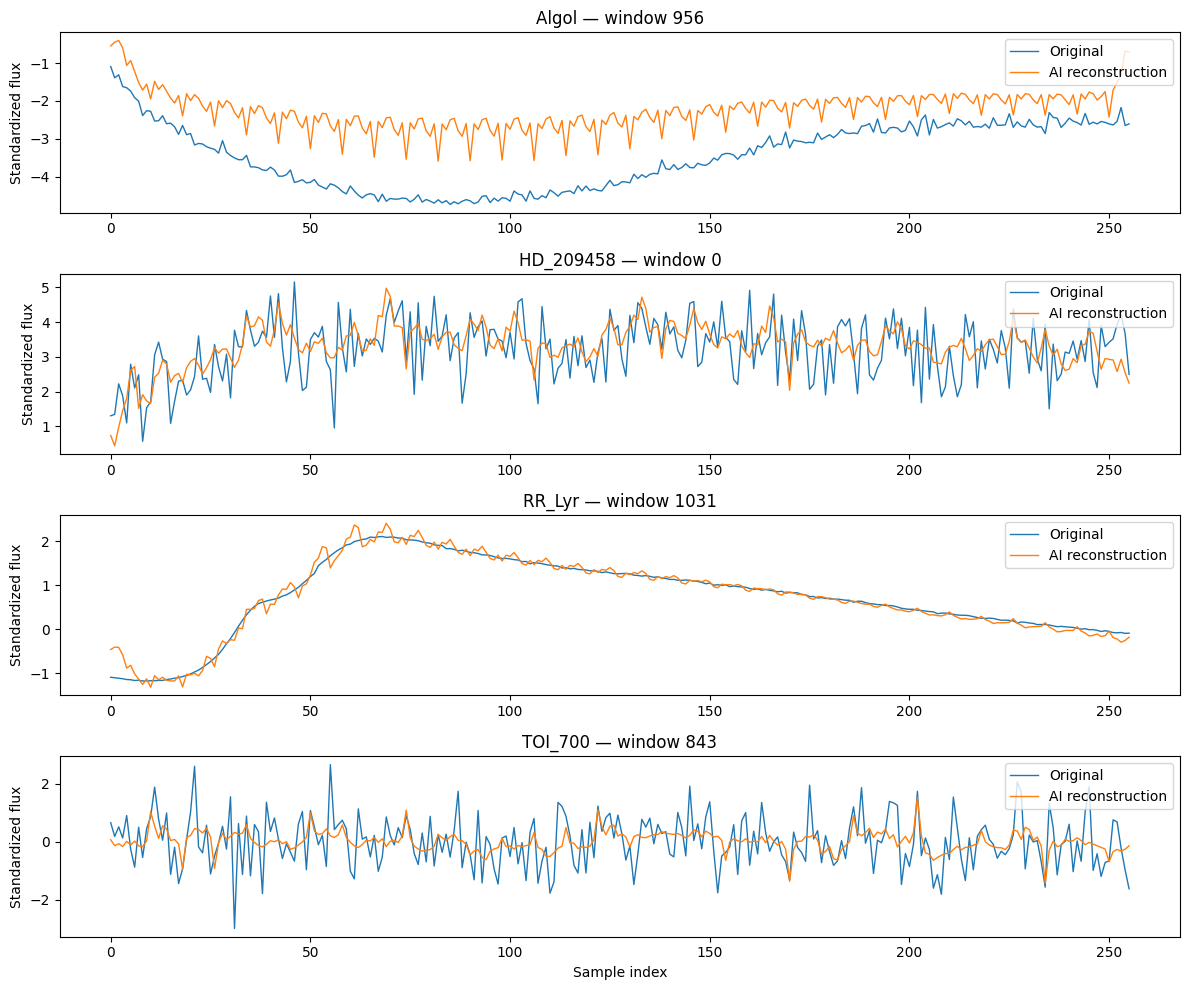

Saved: results/figures/reconstruction_comparison.png


In [ ]:
ROOT = Path("/content/STARTRACE")

X = np.load(ROOT / "data/processed/X_windows.npy")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras",
    compile=False
)

targets = ["Algol", "HD_209458", "RR_Lyr", "TOI_700"]
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

for ax, target in zip(axes, targets):
    idx = np.flatnonzero(meta["target"].to_numpy() == target)[0]
    original = X[idx]
    reconstructed = model.predict(
        original[None, :, None], verbose=0
    )[0, :, 0]

    ax.plot(original, label="Original", linewidth=1)
    ax.plot(reconstructed, label="AI reconstruction", linewidth=1)
    ax.set_title(f"{target} — window {idx}")
    ax.set_ylabel("Standardized flux")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Sample index")
plt.tight_layout()
plt.savefig(
    ROOT / "results/figures/reconstruction_comparison.png",
    dpi=160
)
plt.show()

print("Saved: results/figures/reconstruction_comparison.png")

In [ ]:
from scipy.signal import find_peaks

ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras",
    compile=False
)

# Inspect the same windows you viewed
indices = [1031, 843]
rows = []

for idx in indices:
    original = X[idx].astype(float)
    reconstructed = model.predict(
        original[None, :, None], verbose=0
    )[0, :, 0]

    # Count prominent peaks in each sequence
    p_original, _ = find_peaks(original, prominence=0.3)
    p_reconstructed, _ = find_peaks(reconstructed, prominence=0.3)

    rows.append({
        "window_id": idx,
        "target": meta.iloc[idx]["target"],
        "original_peak_count": len(p_original),
        "AI_peak_count": len(p_reconstructed),
        "original_max": original.max(),
        "AI_max": reconstructed.max(),
        "original_std": original.std(),
        "AI_std": reconstructed.std(),
        "reconstruction_MAE": np.mean(
            np.abs(original - reconstructed)
        )
    })

print(pd.DataFrame(rows).to_string(index=False))

 window_id  target  original_peak_count  AI_peak_count  original_max   AI_max  original_std   AI_std  reconstruction_MAE
      1031  RR_Lyr                    1              6      2.112444 2.414033      0.878498 0.887248            0.089076
       843 TOI_700                   81             23      2.666147 1.531823      0.883839 0.342818            0.621459


The autoencoder has learned to reconstruct some patterns, but it does not consistently preserve fine-scale signal structure. TOI-700's much smaller reconstructed standard deviation is a particularly clear warning sign.
One important correction: peak counts depend on the prominence threshold, so 81 versus 23 peaks does not automatically mean 58 real astrophysical peaks were lost.

In [ ]:
from scipy.stats import pearsonr

rows = []

for idx in [1031, 843]:
    original = X[idx].astype(float)
    reconstructed = model.predict(
        original[None, :, None], verbose=0
    )[0, :, 0]

    rows.append({
        "window_id": meta.iloc[idx]["window_id"],
        "target": meta.iloc[idx]["target"],
        "correlation": pearsonr(original, reconstructed).statistic,
        "std_retained_pct": 100 * reconstructed.std() / original.std(),
        "MAE": np.mean(np.abs(original - reconstructed)),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

 window_id  target  correlation  std_retained_pct   MAE
      1031  RR_Lyr        0.989           100.996 0.089
       843 TOI_700        0.409            38.787 0.621


In [ ]:
ROOT = Path("/content/STARTRACE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

X = np.load(ROOT / "data/processed/X_windows.npy").astype("float32")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")

assert len(X) == len(meta), "Window/metadata mismatch"
assert X.shape[1] == 256, f"Unexpected window shape: {X.shape}"

# Train on the same three stars used by the original model.
# Reserve a later time segment for validation and leave a gap
# to reduce leakage from overlapping windows.
train_stars = ["HD_209458", "TOI_700", "Algol"]
train_idx, val_idx = [], []

for star in train_stars:
    ids = np.flatnonzero(meta["target"].values == star)
    ids = ids[np.argsort(meta.iloc[ids]["start_btjd"].values)]

    cut1 = int(len(ids) * 0.75)
    cut2 = int(len(ids) * 0.80)

    train_idx.extend(ids[:cut1])
    val_idx.extend(ids[cut2:])

rr_idx = np.flatnonzero(meta["target"].values == "RR_Lyr")

X_train = X[train_idx]
X_val = X[val_idx]
X_rr = X[rr_idx]

print("All windows:", X.shape)
print("Training windows:", len(X_train))
print("Temporal validation windows:", len(X_val))
print("Held-out RR Lyrae windows:", len(X_rr))
print("Original model exists:",
      (ROOT / "startrace_autoencoder.keras").exists())

All windows: (1158, 256)
Training windows: 772
Temporal validation windows: 207
Held-out RR Lyrae windows: 127
Original model exists: True


In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

rng = np.random.default_rng(42)

def corrupt_windows(a, copies=4):
    clean = np.repeat(a, copies, axis=0).copy()
    damaged = clean.copy()
    n, length = damaged.shape

    # Small noise plus one randomly masked contiguous section.
    damaged += rng.normal(0, 0.08, damaged.shape).astype("float32")

    starts = rng.integers(0, length - 31, size=n)
    widths = rng.integers(16, 49, size=n)
    positions = np.arange(length)[None, :]
    mask = (
        (positions >= starts[:, None]) &
        (positions < (starts + widths)[:, None])
    )
    damaged[mask] = 0.0

    return damaged[..., None], clean[..., None]

x_train, y_train = corrupt_windows(X_train, copies=4)
x_val, y_val = corrupt_windows(X_val, copies=2)

inp = layers.Input(shape=(256, 1))
z = layers.Conv1D(32, 7, padding="same", activation="relu")(inp)
z = layers.Conv1D(32, 5, padding="same",
                  dilation_rate=2, activation="relu")(z)
z = layers.Conv1D(16, 3, padding="same",
                  dilation_rate=4, activation="relu")(z)
z = layers.Conv1D(32, 5, padding="same", activation="relu")(z)
out = layers.Conv1D(1, 3, padding="same")(z)

denoiser = Model(inp, out, name="STARTRACE_Denoising_v2")
denoiser.compile(optimizer="adam", loss="mae")

history = denoiser.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

v2_path = ROOT / "startrace_denoising_v2.keras"
denoiser.save(v2_path)

pd.DataFrame(history.history).to_csv(
    OUT / "startrace_v2_training_history.csv", index=False
)

print("Saved new model:", v2_path)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.4440 - val_loss: 0.1954
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - loss: 0.1884 - val_loss: 0.1764
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.1772 - val_loss: 0.1667
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 151ms/step - loss: 0.1738 - val_loss: 0.1640
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 169ms/step - loss: 0.1712 - val_loss: 0.1627
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 145ms/step - loss: 0.1691 - val_loss: 0.1605
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 171ms/step - loss: 0.1675 - val_loss: 0.1583
Epoch 8/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - loss: 0.1664 - val_loss: 0.1569
Epoch 9/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - loss: 0.1654 - val_loss: 0.1567
Epoch 10/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - loss: 0.1639 - val_loss: 0.1564
Epoch 11/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.1629 - val_loss: 0.1545
Epoch 12/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step -

In [ ]:
original_model = tf.keras.models.load_model(
    ROOT / "startrace_autoencoder.keras", compile=False
)
denoiser = tf.keras.models.load_model(v2_path, compile=False)

rng_eval = np.random.default_rng(123)
test_sets = [
    ("temporal_validation", val_idx),
    ("held_out_RR_Lyr", rr_idx)
]

rows = []

for split_name, ids in test_sets:
    for idx in ids:
        clean = X[idx]
        noisy = clean.copy()

        noisy += rng_eval.normal(0, 0.08, noisy.shape).astype("float32")
        start = int(rng_eval.integers(0, 224))
        width = int(rng_eval.integers(16, 49))
        noisy[start:start + width] = 0.0

        for condition, signal in [
            ("clean_input", clean),
            ("masked_noisy_input", noisy)
        ]:
            for model_name, net in [
                ("original", original_model),
                ("denoising_v2", denoiser)
            ]:
                pred = net.predict(
                    signal[None, :, None], verbose=0
                )[0, :, 0]

                corr = (
                    pearsonr(clean, pred).statistic
                    if np.std(pred) > 1e-8 else np.nan
                )

                rows.append({
                    "split": split_name,
                    "target": meta.iloc[idx]["target"],
                    "window_id": meta.iloc[idx]["window_id"],
                    "input_condition": condition,
                    "model": model_name,
                    "MAE_vs_clean": np.mean(np.abs(clean - pred)),
                    "correlation_vs_clean": corr,
                    "std_retained_pct": (
                        100 * np.std(pred) / (np.std(clean) + 1e-8)
                    )
                })

evaluation = pd.DataFrame(rows)
evaluation.to_csv(
    OUT / "startrace_v2_model_comparison.csv", index=False
)

summary = (
    evaluation.groupby(
        ["split", "target", "input_condition", "model"]
    )[["MAE_vs_clean", "correlation_vs_clean", "std_retained_pct"]]
    .mean().round(4)
)

print(summary.to_string())
print("\nSaved comparison CSV.")

                                                               MAE_vs_clean  correlation_vs_clean  std_retained_pct
split               target    input_condition    model                                                             
held_out_RR_Lyr     RR_Lyr    clean_input        denoising_v2        0.0158                0.9991         98.955803
                                                 original            0.1051                0.9868        103.494202
                              masked_noisy_input denoising_v2        0.1092                0.9604         96.143501
                                                 original            0.2007                0.9123         97.914200
temporal_validation Algol     clean_input        denoising_v2        0.0182                0.9971         97.004898
                                                 original            0.1136                0.8941        103.186096
                              masked_noisy_input denoising_v2        0.0

In [ ]:
comparison = pd.read_csv(
    OUT / "startrace_v2_model_comparison.csv"
)

report = comparison.groupby(
    ["split", "target", "input_condition", "model"]
)[["MAE_vs_clean", "correlation_vs_clean", "std_retained_pct"]].mean()

report = report.round(4)

report.to_csv(OUT / "startrace_v2_summary.csv")

report_md = """# STARTRACE v2 — Masked Denoising Experiment

## Method
A convolutional denoising autoencoder was trained using existing 256-point
windows. Training inputs received Gaussian noise and one masked segment.
No new data were downloaded; the original model and artifacts were preserved.

## Evaluation
Both models were compared against the clean target on temporal validation
windows from the three training stars and on held-out RR Lyrae windows.
Metrics include MAE, Pearson correlation, and percentage of signal variation
retained.

## Limitations
The dataset contains only four stars. Windows overlap, and RR Lyrae's updated
PDCSAP preprocessing has not yet been propagated into X_windows.npy.
Results are preliminary and do not establish confirmed astrophysical discoveries.

## Results
""" + report.to_markdown()

(OUT / "STARTRACE_v2_results.md").write_text(report_md)

print(report.to_string())
print("\nSaved:")
print(OUT / "startrace_v2_summary.csv")
print(OUT / "STARTRACE_v2_results.md")

                                                               MAE_vs_clean  correlation_vs_clean  std_retained_pct
split               target    input_condition    model                                                             
held_out_RR_Lyr     RR_Lyr    clean_input        denoising_v2        0.0158                0.9991           98.9558
                                                 original            0.1051                0.9868          103.4942
                              masked_noisy_input denoising_v2        0.1092                0.9604           96.1435
                                                 original            0.2007                0.9123           97.9142
temporal_validation Algol     clean_input        denoising_v2        0.0182                0.9971           97.0049
                                                 original            0.1136                0.8941          103.1861
                              masked_noisy_input denoising_v2        0.0

In [ ]:
ROOT = "/content/STARTRACE"
meta = pd.read_csv(f"{ROOT}/data/processed/window_metadata.csv")
results = pd.read_csv(f"{ROOT}/results/startrace_v2_model_comparison.csv")

print("=== Window split audit ===")
for star in ["HD_209458", "TOI_700", "Algol"]:
    ids = np.flatnonzero(meta["target"].values == star)
    ids = ids[np.argsort(meta.iloc[ids]["start_btjd"].values)]
    cut1, cut2 = int(len(ids) * .75), int(len(ids) * .80)

    train = meta.iloc[ids[:cut1]]
    val = meta.iloc[ids[cut2:]]

    print(
        star,
        "| train end:", round(train["end_btjd"].max(), 3),
        "| validation start:", round(val["start_btjd"].min(), 3),
        "| gap:", round(
            val["start_btjd"].min() - train["end_btjd"].max(), 3
        )
    )

print("\n=== Saved clean-input comparison ===")
print(
    results[results["input_condition"] == "clean_input"]
    .groupby(["target", "model"])[
        ["MAE_vs_clean", "correlation_vs_clean", "std_retained_pct"]
    ].mean().round(4).to_string()
)

=== Window split audit ===
HD_209458 | train end: 2846.369 | validation start: 2847.62 | gap: 1.251
TOI_700 | train end: 1344.236 | validation start: 1345.512 | gap: 1.276
Algol | train end: 1807.938 | validation start: 1809.512 | gap: 1.574

=== Saved clean-input comparison ===
                        MAE_vs_clean  correlation_vs_clean  std_retained_pct
target    model                                                             
Algol     denoising_v2        0.0182                0.9971           97.0049
          original            0.1136                0.8941          103.1861
HD_209458 denoising_v2        0.0222                0.9993           99.3695
          original            0.5730                0.4590           46.8910
RR_Lyr    denoising_v2        0.0158                0.9991           98.9558
          original            0.1051                0.9868          103.4942
TOI_700   denoising_v2        0.0232                0.9994           99.4627
          original         

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
Embedding shape: (1158, 32)
Silhouette score: 0.311

Cluster counts by target:
target   Algol  HD_209458  RR_Lyr  TOI_700
cluster                                   
0           13        207      60        7
1           51        483      65      105
2            9        144       2        1
3            2          9       0        0


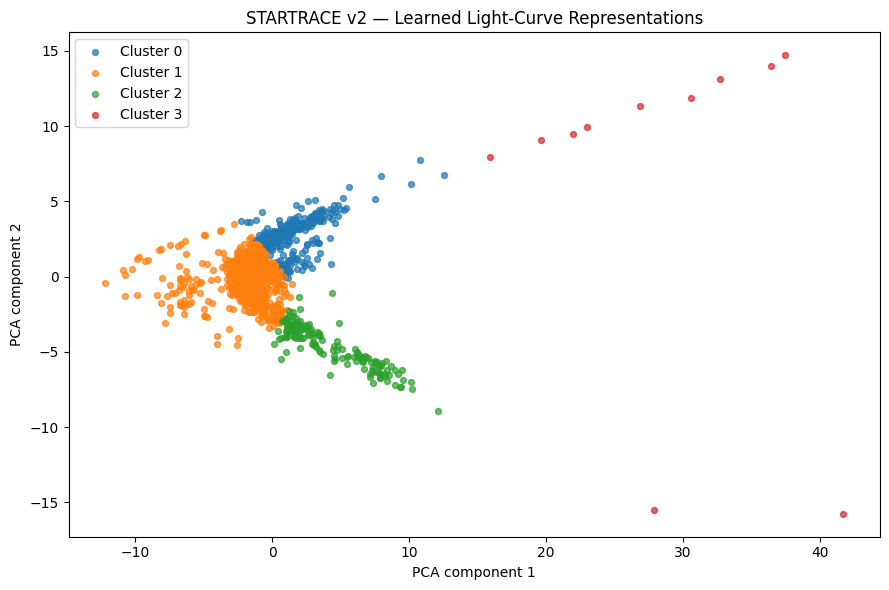


Saved cluster CSV, embeddings, and visualization in: /content/STARTRACE/results


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ROOT = Path("/content/STARTRACE")
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True, parents=True)


X = np.load(ROOT / "data/processed/X_windows.npy").astype("float32")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
model = tf.keras.models.load_model(
    ROOT / "startrace_denoising_v2.keras", compile=False
)

# Extract learned features from the final hidden convolutional layer
encoder = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[-2].output
)

features = encoder.predict(X[..., None], batch_size=64, verbose=1)

# Average across time to obtain one vector per window
embeddings = features.mean(axis=1)
embeddings_scaled = StandardScaler().fit_transform(embeddings)

# Exploratory clustering into four groups
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(embeddings_scaled)

# Two-dimensional visualization
coords = PCA(n_components=2, random_state=42).fit_transform(
    embeddings_scaled
)

result = meta.copy()
result["cluster"] = clusters
result["PCA_1"] = coords[:, 0]
result["PCA_2"] = coords[:, 1]

result.to_csv(OUT / "startrace_v2_morphology_clusters.csv", index=False)
np.save(OUT / "startrace_v2_embeddings.npy", embeddings)

print("Embedding shape:", embeddings.shape)
print("Silhouette score:",
      round(silhouette_score(embeddings_scaled, clusters), 3))
print("\nCluster counts by target:")
print(pd.crosstab(result["cluster"], result["target"]).to_string())

plt.figure(figsize=(9, 6))
for cluster in sorted(result["cluster"].unique()):
    part = result[result["cluster"] == cluster]
    plt.scatter(part["PCA_1"], part["PCA_2"],
                label=f"Cluster {cluster}", alpha=0.7, s=18)

plt.title("STARTRACE v2 — Learned Light-Curve Representations")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "startrace_v2_morphology_clusters.png", dpi=160)
plt.show()

print("\nSaved cluster CSV, embeddings, and visualization in:", OUT)

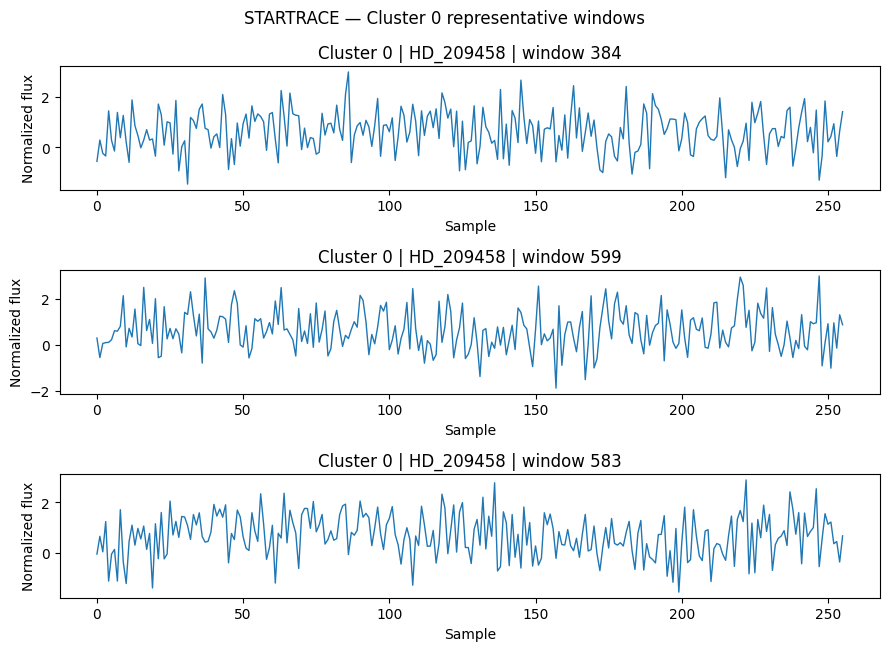

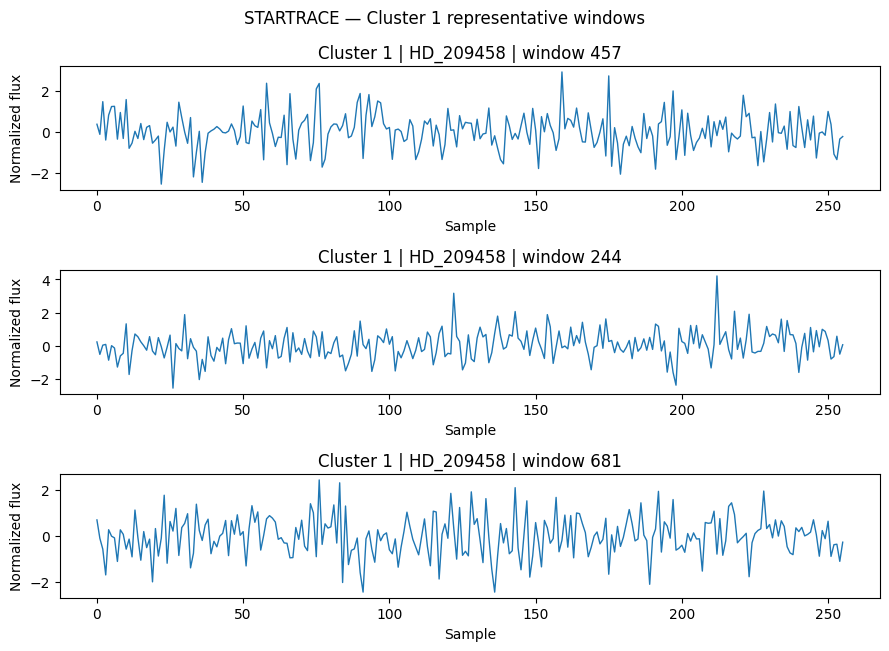

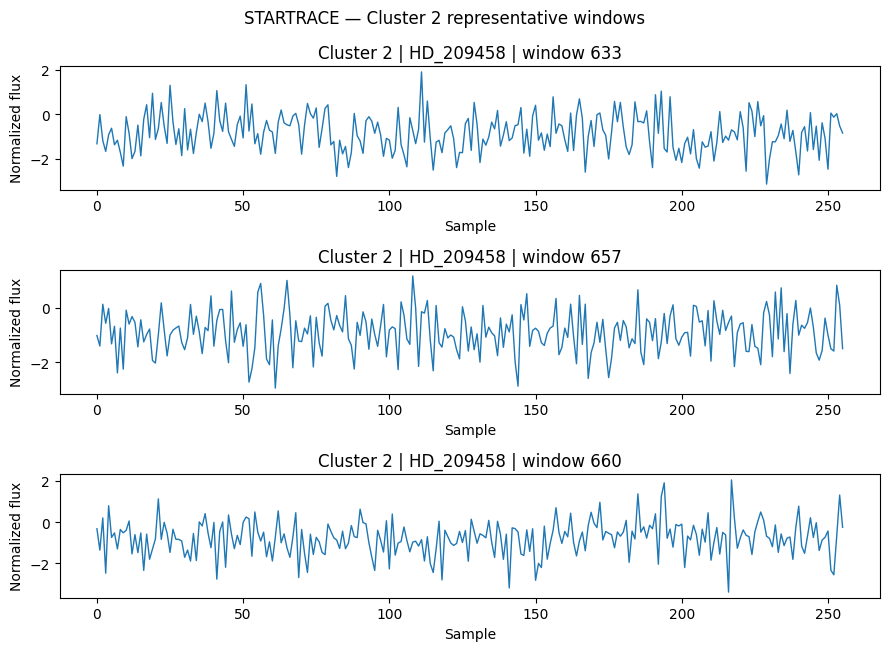

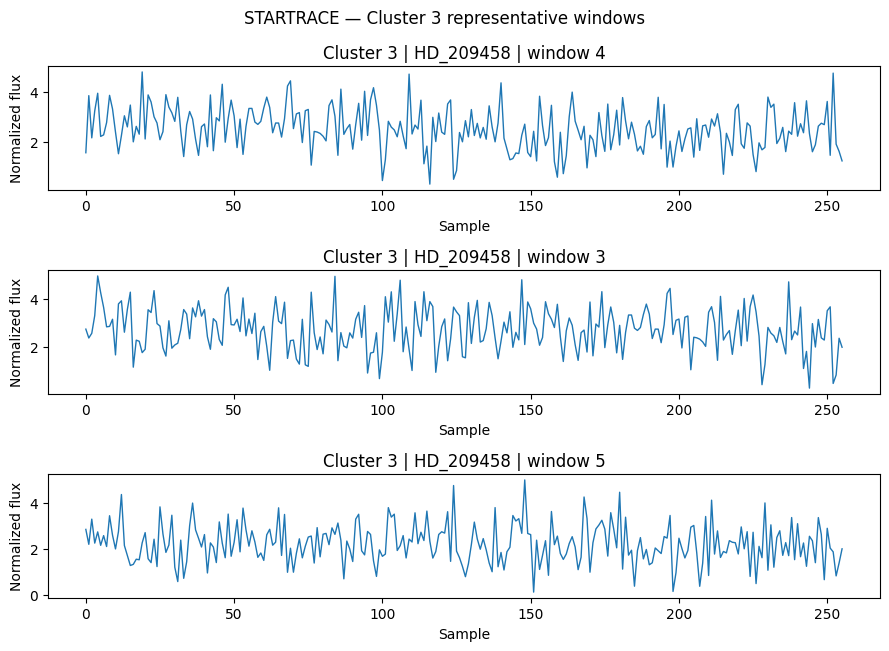

In [ ]:
from sklearn.metrics import pairwise_distances

ROOT = Path("/content/STARTRACE")
OUT = ROOT / "results"

X = np.load(ROOT / "data/processed/X_windows.npy")
E = np.load(OUT / "startrace_v2_embeddings.npy")
df = pd.read_csv(OUT / "startrace_v2_morphology_clusters.csv")

# Match each window to the center of its learned embedding cluster
Z = StandardScaler().fit_transform(E)
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Z)

for c in sorted(df["cluster"].unique()):
    ids = np.flatnonzero(df["cluster"].values == c)
    distances = pairwise_distances(Z[ids], [km.cluster_centers_[c]])[:, 0]
    chosen = ids[np.argsort(distances)[:min(3, len(ids))]]

    fig, axes = plt.subplots(len(chosen), 1, figsize=(9, 2.2 * len(chosen)))
    axes = np.atleast_1d(axes)

    for ax, idx in zip(axes, chosen):
        ax.plot(X[idx], linewidth=1)
        ax.set_title(
            f"Cluster {c} | {df.iloc[idx]['target']} | "
            f"window {df.iloc[idx]['window_id']}"
        )
        ax.set_xlabel("Sample")
        ax.set_ylabel("Normalized flux")

    fig.suptitle(f"STARTRACE — Cluster {c} representative windows")
    fig.tight_layout()
    fig.savefig(OUT / f"startrace_cluster_{c}_examples.png", dpi=150)
    plt.show()

In [ ]:
ROOT = Path("/content/STARTRACE")
X = np.load(ROOT / "data/processed/X_windows.npy")
df = pd.read_csv(ROOT / "results/startrace_v2_morphology_clusters.csv")

rows = []

for i, signal in enumerate(X):
    signal = signal.astype(float)
    centered = signal - signal.mean()

    # Autocorrelation at non-zero lags: exploratory periodicity proxy
    ac = np.correlate(centered, centered, mode="full")[len(signal)-1:]
    ac = ac / (ac[0] + 1e-12)

    rows.append({
        "cluster": df.iloc[i]["cluster"],
        "target": df.iloc[i]["target"],
        "amplitude_std": np.std(signal),
        "roughness": np.mean(np.abs(np.diff(signal))),
        "autocorr_lag_10": ac[10],
        "autocorr_lag_25": ac[25],
        "autocorr_lag_50": ac[50],
    })

features = pd.DataFrame(rows)

print(features.groupby("cluster").agg(
    windows=("target", "size"),
    amplitude=("amplitude_std", "mean"),
    roughness=("roughness", "mean"),
    autocorr_10=("autocorr_lag_10", "mean"),
    autocorr_25=("autocorr_lag_25", "mean"),
    autocorr_50=("autocorr_lag_50", "mean"),
).round(3).to_string())

print("\nTarget composition:")
print(pd.crosstab(features["cluster"], features["target"]).to_string())

         windows  amplitude  roughness  autocorr_10  autocorr_25  autocorr_50
cluster                                                                      
0            287      0.864      0.726        0.220        0.157        0.024
1            704      0.818      0.826        0.125        0.087        0.036
2            156      0.842      0.894        0.056        0.044        0.026
3             11      0.834      0.800        0.203        0.169        0.041

Target composition:
target   Algol  HD_209458  RR_Lyr  TOI_700
cluster                                   
0           13        207      60        7
1           51        483      65      105
2            9        144       2        1
3            2          9       0        0


In [ ]:
from scipy.stats import skew, kurtosis

ROOT = Path("/content/STARTRACE")
OUT = ROOT / "results"

X = np.load(ROOT / "data/processed/X_windows.npy").astype("float32")
meta = pd.read_csv(ROOT / "data/processed/window_metadata.csv")
clusters = pd.read_csv(OUT / "startrace_v2_morphology_clusters.csv")

assert len(X) == len(meta) == len(clusters)

rows = []
for i, x in enumerate(X):
    x = x.astype(float)
    x = x - x.mean()
    ac = np.correlate(x, x, mode="full")[len(x)-1:]
    ac /= (ac[0] + 1e-12)
    d = np.diff(x)

    rows.append({
        "amplitude_std": np.std(x),
        "peak_to_peak": np.ptp(x),
        "roughness": np.mean(np.abs(d)),
        "diff_std": np.std(d),
        "skewness": skew(x),
        "kurtosis": kurtosis(x),
        "autocorr_10": ac[10],
        "autocorr_25": ac[25],
        "autocorr_50": ac[50],
    })

features = pd.DataFrame(rows)
features["target"] = meta["target"].values
features["learned_cluster"] = clusters["cluster"].values
features.to_csv(OUT / "startrace_morphology_features.csv", index=False)

print("Feature table:", features.shape)
print(features.head().round(3).to_string(index=False))

Feature table: (1158, 11)
 amplitude_std  peak_to_peak  roughness  diff_std  skewness  kurtosis  autocorr_10  autocorr_25  autocorr_50    target  learned_cluster
         0.857         4.592      0.891     1.107    -0.300    -0.313        0.100       -0.043        0.047 HD_209458                3
         0.837         4.038      0.978     1.176    -0.094    -0.584        0.132        0.092       -0.000 HD_209458                3
         0.911         4.406      1.010     1.238     0.046    -0.463        0.212        0.106        0.028 HD_209458                3
         0.902         4.647      0.967     1.223    -0.028    -0.233        0.164        0.104       -0.033 HD_209458                3
         0.857         4.488      0.935     1.164     0.113    -0.148        0.131        0.147       -0.007 HD_209458                3


In [ ]:
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

feature_cols = [
    "amplitude_std", "peak_to_peak", "roughness", "diff_std",
    "skewness", "kurtosis", "autocorr_10", "autocorr_25", "autocorr_50"
]

F = features[feature_cols].replace([np.inf, -np.inf], np.nan)
F = F.fillna(F.median())
Fz = StandardScaler().fit_transform(F)

E = np.load(OUT / "startrace_v2_embeddings.npy")
Ez = StandardScaler().fit_transform(E)

simple_model = KMeans(n_clusters=4, random_state=42, n_init=10)
simple_labels = simple_model.fit_predict(Fz)

learned_labels = clusters["cluster"].to_numpy()

comparison = pd.DataFrame([
    {
        "method": "Learned embeddings",
        "silhouette": silhouette_score(Ez, learned_labels)
    },
    {
        "method": "Handcrafted features",
        "silhouette": silhouette_score(Fz, simple_labels)
    }
])

print(comparison.round(3).to_string(index=False))
print("ARI between partitions:",
      round(adjusted_rand_score(learned_labels, simple_labels), 3))
print("NMI between partitions:",
      round(normalized_mutual_info_score(learned_labels, simple_labels), 3))

comparison.to_csv(OUT / "startrace_cluster_method_comparison.csv", index=False)
features["simple_cluster"] = simple_labels
features.to_csv(OUT / "startrace_morphology_features.csv", index=False)

              method  silhouette
  Learned embeddings       0.311
Handcrafted features       0.416
ARI between partitions: 0.001
NMI between partitions: 0.021


In [ ]:
summary = features.groupby("learned_cluster").agg(
    windows=("target", "size"),
    amplitude=("amplitude_std", "mean"),
    peak_to_peak=("peak_to_peak", "mean"),
    roughness=("roughness", "mean"),
    autocorr_10=("autocorr_10", "mean"),
    autocorr_25=("autocorr_25", "mean"),
    autocorr_50=("autocorr_50", "mean"),
).round(3)

print(summary.to_string())
summary.to_csv(OUT / "startrace_cluster_feature_summary.csv")

                 windows  amplitude  peak_to_peak  roughness  autocorr_10  autocorr_25  autocorr_50
learned_cluster                                                                                    
0                    287      0.864         4.570      0.726        0.220        0.157        0.024
1                    704      0.818         4.672      0.826        0.125        0.087        0.036
2                    156      0.842         4.982      0.894        0.056        0.044        0.026
3                     11      0.834         4.367      0.800        0.203        0.169        0.041


In [ ]:
stability = []

for seed in [0, 7, 21, 42, 99]:
    labels = KMeans(
        n_clusters=4, random_state=seed, n_init=10
    ).fit_predict(Ez)

    stability.append({
        "seed": seed,
        "ARI_vs_saved_clusters": adjusted_rand_score(learned_labels, labels),
        "silhouette": silhouette_score(Ez, labels)
    })

stability = pd.DataFrame(stability)
print(stability.round(3).to_string(index=False))
stability.to_csv(OUT / "startrace_cluster_stability.csv", index=False)

 seed  ARI_vs_saved_clusters  silhouette
    0                    1.0       0.311
    7                    1.0       0.311
   21                    1.0       0.311
   42                    1.0       0.311
   99                    1.0       0.311


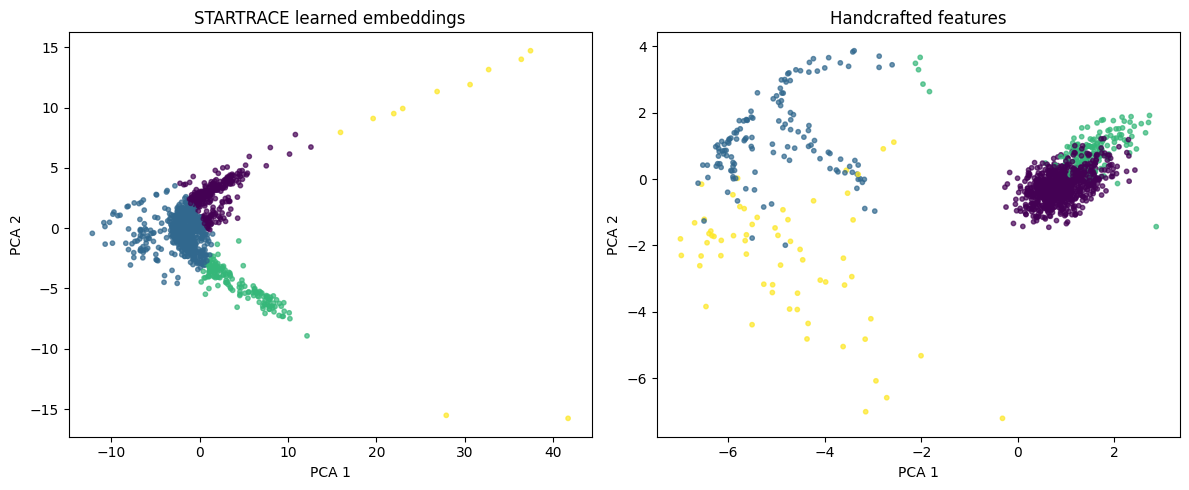

In [ ]:
pca_e = PCA(n_components=2, random_state=42)
pca_f = PCA(n_components=2, random_state=42)

coords_e = pca_e.fit_transform(Ez)
coords_f = pca_f.fit_transform(Fz)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(coords_e[:, 0], coords_e[:, 1],
                c=learned_labels, s=10, alpha=.7)
axes[0].set_title("STARTRACE learned embeddings")

axes[1].scatter(coords_f[:, 0], coords_f[:, 1],
                c=simple_labels, s=10, alpha=.7)
axes[1].set_title("Handcrafted features")

for ax in axes:
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

fig.tight_layout()
fig.savefig(OUT / "startrace_learned_vs_simple_clusters.png", dpi=160)
plt.show()

In [ ]:
learned_composition = pd.crosstab(
    clusters["cluster"], meta["target"]
)
simple_composition = pd.crosstab(
    features["simple_cluster"], features["target"]
)

print("LEARNED CLUSTERS")
print(learned_composition.to_string())

print("\nHANDCRAFTED CLUSTERS")
print(simple_composition.to_string())

learned_composition.to_csv(OUT / "startrace_learned_cluster_composition.csv")
simple_composition.to_csv(OUT / "startrace_simple_cluster_composition.csv")

LEARNED CLUSTERS
target   Algol  HD_209458  RR_Lyr  TOI_700
cluster                                   
0           13        207      60        7
1           51        483      65      105
2            9        144       2        1
3            2          9       0        0

HANDCRAFTED CLUSTERS
target          Algol  HD_209458  RR_Lyr  TOI_700
simple_cluster                                   
0                   0        685       0      108
1                  24          0     111        0
2                   0        158       5        5
3                  51          0      11        0


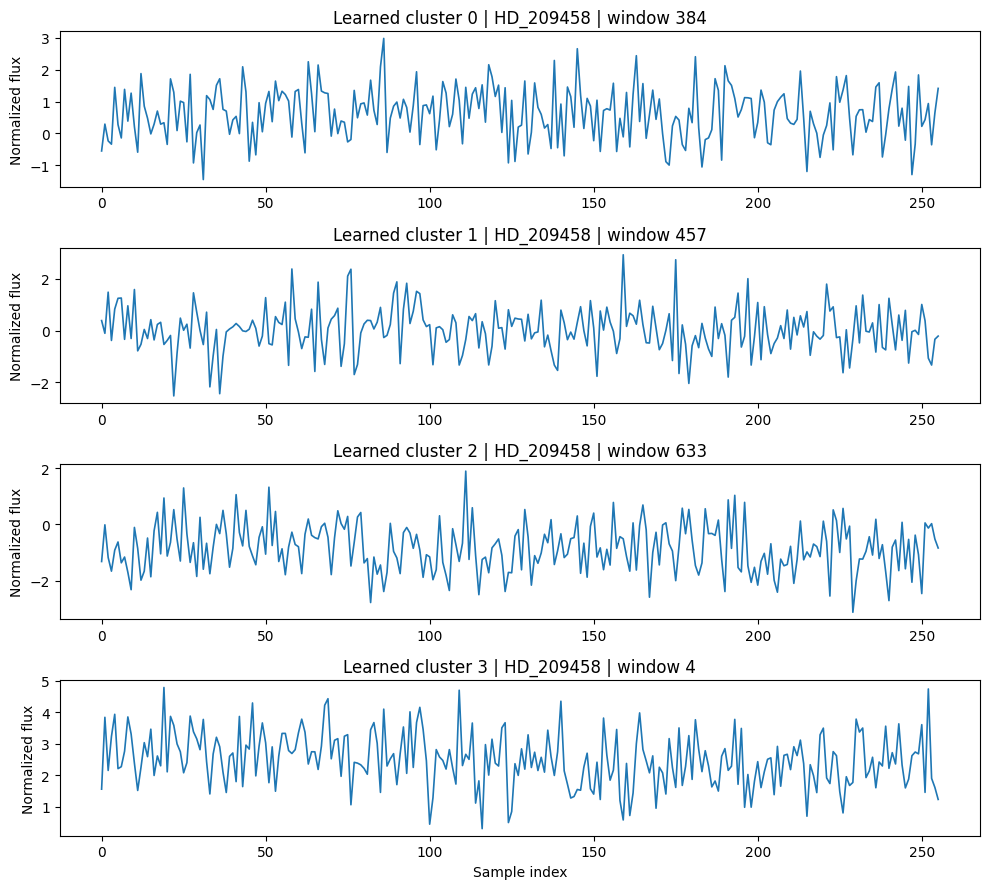

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9))

for c, ax in enumerate(axes):
    ids = np.flatnonzero(learned_labels == c)
    center = Ez[ids].mean(axis=0)
    idx = ids[np.argmin(np.linalg.norm(Ez[ids] - center, axis=1))]

    ax.plot(X[idx], linewidth=1.2)
    ax.set_title(
        f"Learned cluster {c} | {meta.iloc[idx]['target']} | "
        f"window {meta.iloc[idx]['window_id']}"
    )
    ax.set_ylabel("Normalized flux")

axes[-1].set_xlabel("Sample index")
fig.tight_layout()
fig.savefig(OUT / "startrace_cluster_representatives.png", dpi=160)
plt.show()

In [ ]:
evaluation = pd.read_csv(
    OUT / "startrace_v2_model_comparison.csv"
)

model_summary = evaluation.groupby(
    ["split", "input_condition", "model"]
).agg(
    mean_MAE=("MAE_vs_clean", "mean"),
    mean_correlation=("correlation_vs_clean", "mean"),
    mean_std_retained_pct=("std_retained_pct", "mean"),
    evaluated_windows=("window_id", "nunique")
).round(4)

print(model_summary.to_string())
model_summary.to_csv(OUT / "startrace_v2_final_evaluation_summary.csv")

                                                     mean_MAE  mean_correlation  mean_std_retained_pct  evaluated_windows
split               input_condition    model                                                                             
held_out_RR_Lyr     clean_input        denoising_v2    0.0158            0.9991                98.9558                127
                                       original        0.1051            0.9868               103.4942                127
                    masked_noisy_input denoising_v2    0.1092            0.9604                96.1435                127
                                       original        0.2007            0.9123                97.9142                127
temporal_validation clean_input        denoising_v2    0.0221            0.9992                99.2085                207
                                       original        0.5513            0.4906                50.8188                207
                    mask

In [ ]:
cluster_compare = pd.read_csv(
    OUT / "startrace_cluster_method_comparison.csv"
)
stability_df = pd.read_csv(OUT / "startrace_cluster_stability.csv")
cluster_summary = pd.read_csv(OUT / "startrace_cluster_feature_summary.csv")
model_eval = pd.read_csv(OUT / "startrace_v2_final_evaluation_summary.csv")

report = f"""# STARTRACE — Research Pilot Final Report

**Report date:** {date.today().isoformat()}

## Research question
Can a convolutional denoising model learn useful representations of existing
TESS light-curve windows, and do the resulting groups capture measurable
signal properties?

## Data and scope
- Existing windows: {len(X)}
- Targets: {", ".join(sorted(meta["target"].unique()))}
- No additional data downloaded for this analysis.
- Four targets are insufficient to establish broad astronomical generalization.

## Model
A convolutional masked-denoising autoencoder was trained to reconstruct
existing windows corrupted with noise and a masked segment. The original
autoencoder was preserved.

## Reconstruction evaluation
See `startrace_v2_final_evaluation_summary.csv` for MAE, correlation,
variation retained, input condition, and evaluation split.

These are reconstruction metrics, not evidence of new astronomical discoveries.
The validation windows are temporally separated from training windows, but
independence and preprocessing must still be treated cautiously.

## Learned representations and clustering
- Embedding size: {E.shape[1]}
- K-means groups: 4
- Original embedding-cluster silhouette: {silhouette_score(Ez, learned_labels):.3f}
- Handcrafted-feature clustering and partition agreement are in
  `startrace_cluster_method_comparison.csv`.
- Cluster feature summaries and target composition are saved separately.
- Representative waveforms and PCA plots are saved in `results/`.

Silhouette measures geometric separation, not astrophysical validity. Cluster
membership may reflect target identity, preprocessing, noise, or morphology.

## Limitations
1. Only four stars are represented.
2. Adjacent windows overlap, so windows are not independent samples.
3. RR Lyrae's corrected PDCSAP preprocessing has not been propagated to the
   saved window array used in these experiments.
4. Autocorrelation at a few fixed lags is not a validated period measurement.
5. No independently verified labels or confirmed discoveries were established.
6. Cluster stability across random initializations does not establish scientific
   reproducibility across datasets.

## Conclusion
STARTRACE demonstrates a working exploratory pipeline for light-curve
reconstruction, denoising, learned representations, and unsupervised clustering.
Whether its clusters represent useful, generalizable astrophysical morphology
remains an open question requiring more independent targets and validated labels.

## Reproducibility artifacts
- `startrace_denoising_v2.keras`
- `startrace_v2_model_comparison.csv`
- `startrace_v2_embeddings.npy`
- `startrace_v2_morphology_clusters.csv`
- `startrace_morphology_features.csv`
- `startrace_cluster_method_comparison.csv`
- `startrace_cluster_stability.csv`
- `startrace_cluster_representatives.png`
"""

report_path = OUT / "STARTRACE_final_research_report.md"
report_path.write_text(report)

print("FINAL REPORT SAVED:", report_path)
print("Existing model and files preserved.")

FINAL REPORT SAVED: /content/STARTRACE/results/STARTRACE_final_research_report.md
Existing model and files preserved.


In [ ]:
required = [
    ROOT / "startrace_denoising_v2.keras",
    OUT / "startrace_v2_model_comparison.csv",
    OUT / "startrace_v2_embeddings.npy",
    OUT / "startrace_v2_morphology_clusters.csv",
    OUT / "startrace_cluster_method_comparison.csv",
    OUT / "startrace_cluster_stability.csv",
    OUT / "startrace_cluster_representatives.png",
    OUT / "STARTRACE_final_research_report.md",
]

for path in required:
    print(("OK      " if path.exists() else "MISSING "), path.name)

print("\nFinal report:", OUT / "STARTRACE_final_research_report.md")

OK       startrace_denoising_v2.keras
OK       startrace_v2_model_comparison.csv
OK       startrace_v2_embeddings.npy
OK       startrace_v2_morphology_clusters.csv
OK       startrace_cluster_method_comparison.csv
OK       startrace_cluster_stability.csv
OK       startrace_cluster_representatives.png
OK       STARTRACE_final_research_report.md

Final report: /content/STARTRACE/results/STARTRACE_final_research_report.md


In [ ]:
import zipfile

ROOT = Path("/content/STARTRACE")
assert ROOT.exists(), (
    "STARTRACE folder not found. Run this in the Colab notebook "
    "where /content/STARTRACE exists."
)

# Model files and reusable deployment assets
model_exts = {".keras", ".h5", ".pkl", ".pickle", ".joblib"}
support_exts = {
    ".py", ".md", ".txt", ".json", ".yaml", ".yml",
    ".csv", ".png"
}
skip_dirs = {
    ".git", ".venv", "venv", "__pycache__", "node_modules"
}

selected = []
print("=== DISCOVERED MODELS ===")
for p in ROOT.rglob("*"):
    if not p.is_file():
        continue
    if any(part in skip_dirs for part in p.parts):
        continue
    if p.suffix.lower() in model_exts:
        selected.append(p)
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1e6:.2f} MB)")

print("\n=== SUPPORTING CODE & RESULTS ===")
for p in ROOT.rglob("*"):
    if not p.is_file():
        continue
    if any(part in skip_dirs for part in p.parts):
        continue
    rel = p.relative_to(ROOT)
    if "data/raw" in rel.as_posix():
        continue
    if p.name == "X_windows.npy":
        continue
    if p.suffix.lower() in support_exts:
        selected.append(p)
        print(rel)

# Deduplicate and keep paths relative to the project root
selected = sorted(set(selected))
zip_path = Path("/content/STARTRACE_deployment_assets.zip")
manifest = {
    "project": "STARTRACE",
    "purpose": "Streamlit deployment assets",
    "files": [str(p.relative_to(ROOT)) for p in selected],
    "note": (
        "Original files preserved. Raw FITS files and X_windows.npy "
        "are excluded; no model retraining performed."
    )
}

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in selected:
        z.write(p, Path("STARTRACE") / p.relative_to(ROOT))
    z.writestr(
        "STARTRACE/DEPLOYMENT_MANIFEST.json",
        json.dumps(manifest, indent=2)
    )

print(f"\nPackage created: {zip_path}")
print(f"Files packaged: {len(selected)}")
print(f"ZIP size: {zip_path.stat().st_size / 1e6:.2f} MB")


from google.colab import files
files.download(str(zip_path))


=== DISCOVERED MODELS ===
startrace_autoencoder.keras  (0.07 MB)
startrace_denoising_v2.keras  (0.15 MB)

=== SUPPORTING CODE & RESULTS ===
config.json
results/STARTRACE_final_research_report.md
results/STARTRACE_research_report.md
results/startrace_cluster_1_examples.png
results/generalization_robustness_report.csv
results/objective1_quality_report.csv
results/startrace_cluster_feature_summary.csv
results/startrace_v2_training_history.csv
results/startrace_cluster_representatives.png
results/startrace_v2_morphology_clusters.png
results/startrace_cluster_method_comparison.csv
results/startrace_learned_vs_simple_clusters.png
results/startrace_v2_model_comparison.csv
results/startrace_morphology_features.csv
results/startrace_cluster_stability.csv
results/startrace_v2_summary.csv
results/startrace_cluster_3_examples.png
results/STARTRACE_v2_results.md
results/objective1_dataset_audit.csv
results/startrace_cluster_0_examples.png
results/startrace_cluster_2_examples.png
results/model_recon

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
ROOT = Path("/content/STARTRACE")

print("=== CONFIGURATION ===")
config_path = ROOT / "config.json"
if config_path.exists():
    print(json.dumps(json.loads(config_path.read_text()), indent=2))
else:
    print("No config.json found")

print("\n=== MODEL INPUT/OUTPUT SHAPES ===")
for filename in [
    "startrace_autoencoder.keras",
    "startrace_denoising_v2.keras",
]:
    path = ROOT / filename
    if not path.exists():
        print(f"\nMissing: {filename}")
        continue

    model = tf.keras.models.load_model(path, compile=False)
    print(f"\n{filename}")
    print("Input:", model.input_shape)
    print("Output:", model.output_shape)
    print("Layers:", [layer.name for layer in model.layers])

print("\n=== EXISTING DATA SCHEMAS ===")
for filename in [
    "data/processed/HD_209458_clean.csv",
    "data/processed/TOI_700_clean.csv",
    "data/processed/Algol_clean.csv",
    "data/processed/RR_Lyr_clean.csv",
    "data/processed/window_metadata.csv",
    "results/startrace_v2_morphology_clusters.csv",
    "results/startrace_morphology_features.csv",
]:
    path = ROOT / filename
    print(f"\n{filename}")
    if path.exists():
        df = pd.read_csv(path, nrows=3)
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))
    else:
        print("Not found")

print("\n=== OTHER SAVED NUMPY ARTIFACTS ===")
for path in ROOT.rglob("*.npy"):
    if "data/raw" not in path.as_posix():
        print(path.relative_to(ROOT), f"{path.stat().st_size / 1e6:.2f} MB")


=== CONFIGURATION ===
{
  "project": "STARTRACE",
  "random_seed": 42,
  "sampling_unit": "stellar light-curve window",
  "evaluation_goal": "generalization to unseen stars",
  "data_source": "NASA TESS"
}

=== MODEL INPUT/OUTPUT SHAPES ===

startrace_autoencoder.keras
Input: (None, 256, 1)
Output: (None, 256, 1)
Layers: ['input_layer', 'conv1d', 'conv1d_1', 'learned_features', 'conv1d_transpose', 'conv1d_transpose_1', 'conv1d_transpose_2']

startrace_denoising_v2.keras
Input: (None, 256, 1)
Output: (None, 256, 1)
Layers: ['input_layer_1', 'conv1d_2', 'conv1d_3', 'conv1d_4', 'conv1d_5', 'conv1d_6']

=== EXISTING DATA SCHEMAS ===

data/processed/HD_209458_clean.csv
Columns: ['time_btjd', 'normalized_flux']
  time_btjd  normalized_flux
2825.262051         1.000823
2825.262282         1.000848

data/processed/TOI_700_clean.csv
Columns: ['time_btjd', 'normalized_flux']
  time_btjd  normalized_flux
1325.295495         1.001113
1325.296884         1.000317

data/processed/Algol_clean.csv
Col

---

# 📊 Part 3 — Denoising Model v2, Evaluation, and Clustering

## What I worked on

In the final stage of STARTRACE, I focused on improving the first autoencoder and investigating whether the patterns learned by the model could help describe different stellar signals.

The first model gave me a useful starting point, but its reconstruction performance varied across targets. I wanted to see whether a model trained specifically for denoising could reconstruct signals more accurately, including when parts of the input were missing or corrupted.

I also wanted to go beyond reconstruction and explore what the model had actually learned by extracting its internal representations and comparing them with features calculated directly from the light curves.

## 1. Preparing the data for v2

For the second model, I used a time-based split for HD 209458, TOI-700, and Algol rather than randomly distributing their windows.

For each target, the first 75% of the windows went into training, while the last 20% were reserved for validation, with a gap between the two sections to reduce leakage from overlapping windows.

| Target | Gap between training and validation |
|---|---:|
| HD 209458 | 1.25 days |
| TOI-700 | 1.28 days |
| Algol | 1.57 days |

This produced **772 training windows and 207 validation windows**. All 127 RR Lyrae windows remained held out from training.

I chose this approach because neighbouring windows overlap, and I wanted the validation data to be separated in time from the training data. RR Lyrae also gave me an opportunity to examine how the model behaved on a target excluded from training.

## 2. Building the denoising autoencoder — v2

I developed a masked-denoising, one-dimensional convolutional autoencoder using dilated Conv1D layers.

During training, I deliberately corrupted the input signals by adding Gaussian noise with a standard deviation of 0.08 and masking one segment of between 16 and 48 samples. The model was trained to reconstruct the original, uncorrupted signal.

I trained v2 for up to 30 epochs using mean absolute error (MAE) loss and early stopping.

The final validation MAE was **0.146**.

The main idea was to make the model learn to reconstruct the underlying signal even when some of the input information was noisy or missing, rather than simply learning to copy the input.

## 3. Comparing v1 and v2

I evaluated both models on the temporal validation windows and the held-out RR Lyrae windows. For each split, I tested both clean inputs and inputs with masking and added noise.

| Evaluation split | Input condition | v1 MAE | v1 correlation | v2 MAE | v2 correlation |
|---|---|---:|---:|---:|---:|
| Temporal validation | Clean | 0.551 | 0.491 | 0.022 | 0.999 |
| Temporal validation | Masked + noisy | 0.576 | 0.431 | 0.149 | 0.916 |
| Held-out RR Lyrae | Clean | 0.105 | 0.987 | 0.016 | 0.999 |
| Held-out RR Lyrae | Masked + noisy | 0.201 | 0.912 | 0.109 | 0.960 |

The results showed a clear improvement in reconstruction metrics with v2 across the evaluations I ran.

For example, on the temporally held-out data with masked and noisy inputs, v2 achieved an MAE of 0.149 and a correlation of 0.916, compared with v1's MAE of 0.576 and correlation of 0.431.

On the held-out RR Lyrae data under the same input conditions, v2 achieved an MAE of 0.109 and a correlation of 0.960.

What interested me most was that the improvement was also visible on RR Lyrae, which had not been used to train either model.

However, I would not treat these results as proof that v2 has learned general astrophysical features. The clean-input scores are particularly strong, and the difference between clean and corrupted inputs shows why the evaluation conditions matter. Further testing on more stars and independent datasets is needed to establish how well the model generalises.

## 4. Exploring what the model learned

After evaluating the reconstructions, I wanted to investigate the internal representations learned by v2.

I extracted **32-dimensional embeddings** from the model's final hidden layer by averaging the activations over time. These embeddings provide a numerical representation of each window that can be used for further analysis.

I then applied K-means clustering with \(k = 4\) to explore whether windows with similar learned representations would form groups.

The resulting cluster sizes were:

| Cluster | Number of windows |
|---|---:|
| 1 | 287 |
| 2 | 704 |
| 3 | 156 |
| 4 | 11 |

The silhouette score for the learned embeddings was **0.311**.

This gave me a way to examine the organisation of the learned representations, but the cluster sizes were uneven, especially for the smallest group. I therefore treated the clusters as exploratory groupings rather than assigning them specific astrophysical meanings.

## 5. Comparing learned embeddings with handcrafted features

I also wanted to compare the model's representations with a more traditional approach.

I calculated nine features directly from each signal window:

- Amplitude
- Peak-to-peak range
- Roughness
- Standard deviation of first differences
- Skewness
- Kurtosis
- Autocorrelation at lags 10, 25, and 50

I then clustered these handcrafted features using K-means and compared the resulting groups with those obtained from the learned embeddings.

| Measurement | Learned embeddings | Handcrafted features |
|---|---:|---:|
| Silhouette score | 0.311 | 0.416 |

The handcrafted features achieved the higher silhouette score, suggesting that they formed more clearly separated groups according to this particular metric.

I also measured the agreement between the two clustering results:

- **Adjusted Rand Index (ARI):** 0.001
- **Normalized Mutual Information (NMI):** 0.021

Both values were very close to zero, indicating almost no agreement between the two partitions.

I found this comparison important because it showed that the learned representations and the manually calculated features organised the same windows quite differently. It also meant that I could not claim the learned embeddings were better simply because they came from a neural network.

In this experiment, the handcrafted features achieved stronger geometric separation. Whether either clustering approach captures meaningful astrophysical categories remains an open question.

## 6. Checking cluster stability and saving the results

To check whether the learned clusters depended heavily on the random initialisation, I repeated the K-means clustering with five different random seeds.

The resulting partitions were identical, with an ARI of **1.0** between them.

This was encouraging because the clustering was stable across those initialisations. However, I kept the interpretation limited: stability across random seeds does not establish that the clusters will remain the same on a new dataset or correspond to real astronomical classes.

I also saved the main outputs from this stage, including:

- Target composition tables for the learned clusters.
- PCA plots to visualise the embeddings.
- Representative signal waveforms from the clusters.
- The final research report.
- The generated project artefacts and checks confirming that the expected files existed.

These outputs made it easier to inspect the results beyond the numerical metrics and document what the pipeline produced.

## What I learned from Part 3

This final stage brought the main parts of STARTRACE together: denoising, model evaluation, feature extraction, and clustering.

The second autoencoder achieved substantially better reconstruction metrics than v1 in the evaluations I performed. At the same time, the clustering experiments showed that better reconstruction does not automatically translate into better-separated or scientifically meaningful groups.

The handcrafted features achieved a higher silhouette score than the learned embeddings, and the two clustering approaches showed almost no agreement. The stability of the learned clusters across random seeds was useful to establish, but it was not enough to validate their astrophysical meaning.

For me, this is one of the most important lessons from the project: **a model can perform well at reconstructing data without necessarily solving the scientific problem I ultimately care about.**

## Final outcome of STARTRACE

STARTRACE brought together a complete exploratory pipeline using real NASA TESS observations, from downloading and checking the data to preparing windows, training two convolutional autoencoders, evaluating reconstructions, and investigating learned representations.

The project gave me practical experience with astronomical time-series data, convolutional neural networks, denoising, unsupervised learning, and the challenges of evaluating models on limited scientific datasets.

There is still substantial work to do before these methods can be used to identify or classify astrophysical events reliably. The next step is to expand the dataset, verify event labels independently, establish stronger baselines, and evaluate performance on genuinely unseen stars.

**My goal was not simply to build a model with impressive numbers. I wanted to understand what the model could do, where it fell short, and what would be needed to turn an exploratory experiment into more rigorous astrophysical research.**

---